# 06 — Weighted Score Fusion (Multimodal Medicinal Leaf Retrieval)

Notebook final hasil audit & refactoring. Jalankan dengan **Restart Kernel → Run All**.

**Sumber input (read-only)**
- `dataset/features/visual/` (atau `visual.zip` di root proyek) — artefak resmi Notebook 03: HSV 64 + GLCM 72 + Hu 7 = 143 fitur.
- `dataset/features/text/` (atau `text.zip`) — metadata & `cleaned_description` dari Notebook 02.
- `dataset/processed/images/...` — opsional tetapi diperlukan untuk audit piksel (dHash) dan visualisasi gambar di Cell 17.

**Prinsip**
- Normalisasi visual (algoritma Notebook 03) dan TF-IDF di-*fit* **hanya pada gallery**.
- α dan konfigurasi TF-IDF dipilih **hanya dari validation** (mAP@5 + tie-breaking). α lama (0,3) tidak dipakai ulang.
- Test tidak pernah dipakai untuk memilih apa pun. Label status test ditentukan Cell 13; notebook **tidak pernah** mengisi persetujuan reviewer.
- Setiap eksekusi menulis ke folder run baru `results/{metrics,figures,artifacts}/retrieval_evaluation/runs/<RUN_ID>/` dan tercatat di `experiment_registry.csv`; output lama tidak ditimpa.
- Keputusan manual reviewer disimpan permanen di `results/reviews/retrieval_evaluation/` (695, 699, 705).

## Cell 1 — Setup, protokol eksperimen & versioning run

In [1]:
# ============================================================
# CELL 1 - SETUP, ENVIRONMENT, EVALUATION PROTOCOL & RUN VERSIONING
# Notebook: 06_weighted_score_fusion_FINAL.ipynb
# ============================================================
# Sumber data resmi notebook ini:
#   - Notebook 03 : dataset/features/visual/  (atau visual.zip)
#   - Notebook 02 : dataset/features/text/    (atau text.zip)
# Artefak Notebook 05 (results/artifacts/multimodal_fusion) bersifat
# OPSIONAL dan hanya dipakai untuk pemeriksaan konsistensi urutan sampel,
# karena matriks similarity Notebook 05 di-fit pada seluruh 104 sampel.
#
# Setiap eksekusi penuh (Restart Kernel -> Run All) menulis ke folder run
# baru:  results/{metrics,figures,artifacts}/retrieval_evaluation/runs/<RUN_ID>/
# Output lama tidak pernah ditimpa; semua run dicatat di
# results/metrics/retrieval_evaluation/experiment_registry.csv
# ============================================================

import os
import io
import sys
import json
import hashlib
import platform
import zipfile
import warnings
from datetime import datetime, timezone
from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import pandas as pd
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt

from IPython.display import display

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

print("NOTEBOOK 06 - WEIGHTED SCORE FUSION (MULTIMODAL LEAF RETRIEVAL)")
print("=" * 75)

EVAL06_SETUP_COMPLETED = False

# ============================================================
# 1. EXPERIMENT CONFIGURATION (single source of truth)
# ============================================================

EVAL06_PIPELINE_VERSION = "06_wsf_final_v1.0"
EVAL06_RANDOM_STATE = 42
EVAL06_SPLIT_NAMES = ("gallery", "validation", "test")
EVAL06_SPLIT_RATIOS = {"gallery": 0.60, "validation": 0.20, "test": 0.20}
EVAL06_TOP_K_VALUES = (1, 3, 5, 10)
EVAL06_PRIMARY_K = 5
EVAL06_ALPHA_GRID = np.round(np.linspace(0.0, 1.0, 11), 10)
EVAL06_DEFAULT_ALPHA = 0.5
EVAL06_TEXT_CONFIGURATIONS = {
    "Unigram": {"slug": "unigram", "ngram_range": (1, 1)},
    "Unigram + Bigram": {"slug": "unigram_bigram", "ngram_range": (1, 2)},
}
EVAL06_PRIMARY_SELECTION_METRIC = "mAP@5"
EVAL06_SELECTION_TOLERANCE = 1e-10
EVAL06_TIE_BREAK_RULES = [
    "max validation mAP@5",
    "max validation nDCG@5 within tolerance",
    "max validation MRR@5 within tolerance",
    "alpha closest to 0.5",
    "prefer Unigram if all above tied",
    "smaller alpha",
]
EVAL06_RANKING_TIE_POLICY = "similarity_descending_then_sample_id_ascending"
EVAL06_RELEVANCE_POLICY = "same_plant_class"
EVAL06_AP_CONVENTION = "AP@K normalized by min(R, K)"
EVAL06_NDCG_CONVENTION = "binary gain, log2(rank+1) discount, ideal = min(R, K) hits"
EVAL06_VISUAL_SIMILARITY_FORMULA = "S_visual = 1 / (1 + d_euclidean / median_nonzero_gallery_distance)"
EVAL06_TEXT_SIMILARITY_FORMULA = "S_text = cosine(TF-IDF_query, TF-IDF_gallery), clipped to [0, 1]"
EVAL06_FUSION_FORMULA = "S_fusion = alpha * S_visual + (1 - alpha) * S_text"
EVAL06_FIT_POLICY = "gallery_only"
EVAL06_NEAR_DUPLICATE_DHASH_THRESHOLD = 4
EVAL06_NUMERICAL_TOLERANCE = 1e-10

# Notebook 03 visual feature definition (must not be changed here).
EVAL06_VISUAL_GROUPS = {"HSV": (0, 64), "GLCM": (64, 136), "Hu Moments": (136, 143)}
EVAL06_VISUAL_DIM = 143
EVAL06_HSV_STD_FLOOR = 1e-3
EVAL06_APPLY_GROUP_BALANCING = True

# TF-IDF parameters identical to Notebook 02 (text_feature_extraction_config.json),
# but fitted on GALLERY ONLY in Cell 4B.
EVAL06_TFIDF_PARAMS = dict(
    analyzer="word", lowercase=True, token_pattern=r"(?u)\b\w\w+\b",
    norm="l2", use_idf=True, smooth_idf=True, sublinear_tf=False,
    strip_accents=None, stop_words=None, min_df=1, max_df=1.0,
    max_features=None, dtype=np.float64,
)

# The user has confirmed that test results of earlier runs were already
# inspected. This flag can NEVER be switched off by the notebook itself.
EVAL06_TEST_PREVIOUSLY_INSPECTED_DECLARED = True

# Formal status labels.
EVAL06_STATUS_PROVISIONAL = "PROVISIONAL_AUDIT_UNRESOLVED"
EVAL06_STATUS_SIGNED_NOT_INDEPENDENT = "SIGNED_OFF_TEST_PREVIOUSLY_INSPECTED"
EVAL06_STATUS_INDEPENDENT = "INDEPENDENT_TEST_APPROVED"

# ============================================================
# 2. SHARED HELPERS (used by all following cells)
# ============================================================

def eval06_sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()


def eval06_sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def eval06_sha256_array(array):
    array = np.ascontiguousarray(array)
    digest = hashlib.sha256()
    digest.update(str(array.dtype).encode() + str(array.shape).encode())
    digest.update(array.tobytes())
    return digest.hexdigest()


def eval06_canonical_json(obj):
    return json.dumps(obj, sort_keys=True, ensure_ascii=False,
                      separators=(",", ":"), default=eval06_json_default)


def eval06_json_default(value):
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, (set, tuple)):
        return list(value)
    raise TypeError(f"Not JSON serializable: {type(value)}")


EVAL06_OUTPUT_LOG = []


def eval06_log_output(path, cell, kind):
    EVAL06_OUTPUT_LOG.append({"cell": cell, "kind": kind, "path": str(path)})


def eval06_save_csv(df, filename, cell, directory=None):
    path = Path(directory or EVAL06_METRICS_DIR) / filename
    df.to_csv(path, index=False, encoding="utf-8-sig")
    eval06_log_output(path, cell, "csv")
    print("[SAVED]", path.name)
    return path


def eval06_save_json(obj, filename, cell, directory=None):
    path = Path(directory or EVAL06_METRICS_DIR) / filename
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False,
                               allow_nan=False, default=eval06_json_default),
                    encoding="utf-8")
    eval06_log_output(path, cell, "json")
    print("[SAVED]", path.name)
    return path


def eval06_save_text(text, filename, cell, directory=None):
    path = Path(directory or EVAL06_METRICS_DIR) / filename
    path.write_text(text, encoding="utf-8")
    eval06_log_output(path, cell, "text")
    print("[SAVED]", path.name)
    return path


def eval06_save_figure(fig, filename, cell, dpi=200):
    path = EVAL06_FIGURES_DIR / filename
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    eval06_log_output(path, cell, "png")
    plt.show()
    plt.close(fig)
    print("[SAVED]", path.name)
    return path


def eval06_check(records, category, name, passed, detail="", severity="BLOCK"):
    records.append({
        "category": category,
        "validation_check": name,
        "passed": bool(passed),
        "severity_if_failed": severity,
        "detail": str(detail),
    })


def eval06_checks_frame(records):
    return pd.DataFrame(records, columns=[
        "category", "validation_check", "passed", "severity_if_failed", "detail"])


def eval06_require(check_df, label):
    """Raise if any BLOCK-severity technical check failed (never hidden)."""
    failed = check_df.loc[~check_df["passed"] & check_df["severity_if_failed"].eq("BLOCK")]
    if not failed.empty:
        raise AssertionError(f"{label}: technical checks failed:\n"
                             + failed.to_string(index=False))


_MPL_VERSION = tuple(int(p) for p in matplotlib.__version__.split(".")[:2])


def eval06_boxplot(ax, data, labels, **kwargs):
    """Matplotlib >= 3.9 uses tick_labels; older versions use labels."""
    if _MPL_VERSION >= (3, 9):
        return ax.boxplot(data, tick_labels=list(labels), **kwargs)
    return ax.boxplot(data, labels=list(labels), **kwargs)


def eval06_is_blank(value):
    """True for None/NaN/empty strings and textual placeholders."""
    if value is None:
        return True
    try:
        if pd.isna(value):
            return True
    except (TypeError, ValueError):
        pass
    return str(value).strip().lower() in {"", "nan", "none", "null", "na", "n/a"}


def eval06_clean_str(value):
    return "" if eval06_is_blank(value) else str(value).strip()


# ============================================================
# 3. LOCATE PROJECT ROOT
# ============================================================

EVAL06_WORKING_DIRECTORY = Path.cwd().resolve()

if os.environ.get("EVAL06_PROJECT_ROOT"):
    EVAL06_PROJECT_ROOT = Path(os.environ["EVAL06_PROJECT_ROOT"]).resolve()
elif EVAL06_WORKING_DIRECTORY.name.lower() in ("notebooks", "notebook"):
    EVAL06_PROJECT_ROOT = EVAL06_WORKING_DIRECTORY.parent
else:
    EVAL06_PROJECT_ROOT = EVAL06_WORKING_DIRECTORY

print("\n1. PROJECT PATHS")
print("-" * 75)
print("Working directory:", EVAL06_WORKING_DIRECTORY)
print("Project root     :", EVAL06_PROJECT_ROOT)


# ============================================================
# 4. SOURCE ARTIFACT STORE (directory or ZIP, read-only)
# ============================================================

class Eval06SourceStore:
    """Read-only access to a Notebook 02/03 artifact folder or ZIP archive."""

    def __init__(self, modality, root):
        self.modality = modality
        self.kind = None
        self.location = None
        directories = [
            root / "dataset" / "features" / modality,
            root / "features" / modality,
            root / modality,
        ]
        archives = [
            root / f"{modality}.zip",
            root / "dataset" / f"{modality}.zip",
            root / "dataset" / "features" / f"{modality}.zip",
        ]
        for directory in directories:
            if directory.is_dir() and any(directory.iterdir()):
                self.kind, self.location = "directory", directory.resolve()
                return
        for archive in archives:
            if archive.is_file():
                self.kind, self.location = "zip", archive.resolve()
                return
        raise FileNotFoundError(
            f"Artefak '{modality}' tidak ditemukan. Lokasi yang diperiksa:\n"
            + "\n".join(str(p) for p in directories + archives))

    def read_bytes(self, filename):
        if self.kind == "directory":
            path = self.location / filename
            if not path.is_file():
                raise FileNotFoundError(f"{self.modality}/{filename} tidak ada di {self.location}")
            return path.read_bytes()
        with zipfile.ZipFile(self.location) as archive:
            for member in (f"{self.modality}/{filename}", filename):
                if member in archive.namelist():
                    return archive.read(member)
        raise FileNotFoundError(f"{self.modality}/{filename} tidak ada di {self.location}")

    def exists(self, filename):
        try:
            self.read_bytes(filename)
            return True
        except FileNotFoundError:
            return False

    def npy(self, filename):
        return np.load(io.BytesIO(self.read_bytes(filename)), allow_pickle=False)

    def csv(self, filename, **kwargs):
        return pd.read_csv(io.BytesIO(self.read_bytes(filename)), **kwargs)

    def json(self, filename):
        return json.loads(self.read_bytes(filename).decode("utf-8"))

    def describe(self):
        return f"{self.kind}: {self.location}"


EVAL06_VISUAL_SOURCE = Eval06SourceStore("visual", EVAL06_PROJECT_ROOT)
EVAL06_TEXT_SOURCE = Eval06SourceStore("text", EVAL06_PROJECT_ROOT)

print("Visual source    :", EVAL06_VISUAL_SOURCE.describe())
print("Text source      :", EVAL06_TEXT_SOURCE.describe())


# ============================================================
# 5. INPUT FINGERPRINT, RUN ID AND OUTPUT DIRECTORIES
# ============================================================

EVAL06_FINGERPRINT_SOURCE_FILES = {
    "visual": ["visual_features_raw.npy", "hsv_features.npy", "glcm_features.npy",
               "hu_features.npy", "visual_sample_ids.npy", "visual_feature_metadata.csv",
               "visual_feature_manifest.json", "visual_feature_config.json"],
    "text": ["multimodal_feature_metadata.csv", "text_sample_ids.npy",
             "text_class_labels.npy", "text_feature_extraction_config.json"],
}

EVAL06_SOURCE_FILE_HASHES = {}
for modality, files in EVAL06_FINGERPRINT_SOURCE_FILES.items():
    store = EVAL06_VISUAL_SOURCE if modality == "visual" else EVAL06_TEXT_SOURCE
    for filename in files:
        EVAL06_SOURCE_FILE_HASHES[f"{modality}/{filename}"] = eval06_sha256_bytes(
            store.read_bytes(filename))

EVAL06_EVALUATION_PROTOCOL = {
    "notebook": "06_weighted_score_fusion_FINAL.ipynb",
    "pipeline_version": EVAL06_PIPELINE_VERSION,
    "random_state": EVAL06_RANDOM_STATE,
    "split_names": list(EVAL06_SPLIT_NAMES),
    "split_ratios": EVAL06_SPLIT_RATIOS,
    "top_k_values": list(EVAL06_TOP_K_VALUES),
    "alpha_grid": [float(a) for a in EVAL06_ALPHA_GRID],
    "default_alpha": EVAL06_DEFAULT_ALPHA,
    "text_configurations": {k: {"ngram_range": list(v["ngram_range"])}
                            for k, v in EVAL06_TEXT_CONFIGURATIONS.items()},
    "tfidf_parameters": {k: (str(v) if k == "dtype" else v)
                         for k, v in EVAL06_TFIDF_PARAMS.items()},
    "visual_feature_groups": {k: list(v) for k, v in EVAL06_VISUAL_GROUPS.items()},
    "visual_normalization": {
        "method": "Notebook 03: StandardScaler per group + HSV SD floor + 1/sqrt(dim) group weight",
        "hsv_std_floor": EVAL06_HSV_STD_FLOOR,
        "group_balancing": EVAL06_APPLY_GROUP_BALANCING,
        "constant_feature_policy": "constant in gallery -> transformed value 0",
        "fit_scope": "gallery_only",
    },
    "visual_similarity": EVAL06_VISUAL_SIMILARITY_FORMULA,
    "text_similarity": EVAL06_TEXT_SIMILARITY_FORMULA,
    "fusion": EVAL06_FUSION_FORMULA,
    "primary_selection_metric": EVAL06_PRIMARY_SELECTION_METRIC,
    "selection_partition": "validation",
    "selection_tolerance": EVAL06_SELECTION_TOLERANCE,
    "tie_break_rules": EVAL06_TIE_BREAK_RULES,
    "ranking_tie_policy": EVAL06_RANKING_TIE_POLICY,
    "relevance_policy": EVAL06_RELEVANCE_POLICY,
    "ap_convention": EVAL06_AP_CONVENTION,
    "ndcg_convention": EVAL06_NDCG_CONVENTION,
    "fit_policy": EVAL06_FIT_POLICY,
    "test_used_for_selection": False,
    "near_duplicate_dhash_threshold": EVAL06_NEAR_DUPLICATE_DHASH_THRESHOLD,
}

EVAL06_INPUT_FINGERPRINT = eval06_sha256_bytes(eval06_canonical_json({
    "protocol": EVAL06_EVALUATION_PROTOCOL,
    "source_files": EVAL06_SOURCE_FILE_HASHES,
}).encode("utf-8"))

EVAL06_RUN_STARTED_UTC = datetime.now(timezone.utc)
EVAL06_RUN_ID = (EVAL06_RUN_STARTED_UTC.strftime("%Y%m%dT%H%M%SZ")
                 + "_" + EVAL06_INPUT_FINGERPRINT[:10])

EVAL06_RESULTS_ROOT = EVAL06_PROJECT_ROOT / "results"
EVAL06_METRICS_BASE = EVAL06_RESULTS_ROOT / "metrics" / "retrieval_evaluation"
EVAL06_FIGURES_BASE = EVAL06_RESULTS_ROOT / "figures" / "retrieval_evaluation"
EVAL06_ARTIFACTS_BASE = EVAL06_RESULTS_ROOT / "artifacts" / "retrieval_evaluation"
EVAL06_REVIEW_DIR = EVAL06_RESULTS_ROOT / "reviews" / "retrieval_evaluation"

EVAL06_METRICS_DIR = EVAL06_METRICS_BASE / "runs" / EVAL06_RUN_ID
EVAL06_FIGURES_DIR = EVAL06_FIGURES_BASE / "runs" / EVAL06_RUN_ID
EVAL06_ARTIFACTS_DIR = EVAL06_ARTIFACTS_BASE / "runs" / EVAL06_RUN_ID
EVAL06_REGISTRY_PATH = EVAL06_METRICS_BASE / "experiment_registry.csv"
EVAL06_LATEST_POINTER_PATH = EVAL06_METRICS_BASE / "LATEST_COMPLETED_RUN.json"

for directory in (EVAL06_METRICS_DIR, EVAL06_FIGURES_DIR, EVAL06_ARTIFACTS_DIR):
    if directory.exists() and any(directory.iterdir()):
        raise FileExistsError(f"Run directory already used: {directory}")
    directory.mkdir(parents=True, exist_ok=True)
EVAL06_REVIEW_DIR.mkdir(parents=True, exist_ok=True)

print("\n2. RUN VERSIONING")
print("-" * 75)
print("Input fingerprint:", EVAL06_INPUT_FINGERPRINT)
print("Run ID           :", EVAL06_RUN_ID)
print("Metrics          :", EVAL06_METRICS_DIR)
print("Figures          :", EVAL06_FIGURES_DIR)
print("Artifacts        :", EVAL06_ARTIFACTS_DIR)
print("Manual reviews   :", EVAL06_REVIEW_DIR)


# ============================================================
# 6. LEGACY OUTPUTS AND EXPERIMENT REGISTRY
# ============================================================
# Legacy = flat files written by older notebook versions directly into
# results/metrics/retrieval_evaluation/. They are NEVER used as inputs for
# features, similarity, selection or metrics. Only three uses are allowed
# and every use is labelled in the reports:
#   (a) 608_raw_image_audit.csv : fallback image hashes if images are absent;
#   (b) 620_group_aware_split_assignments.csv : comparison only;
#   (c) 695/699/705 review files : seed manual-review notes (never approvals).

EVAL06_LEGACY_METRICS_DIR = EVAL06_METRICS_BASE
EVAL06_LEGACY_FILES = sorted(
    p.name for p in EVAL06_LEGACY_METRICS_DIR.glob("*") if p.is_file()
    and p.name[:3].isdigit())
EVAL06_LEGACY_TEST_FILES = [name for name in EVAL06_LEGACY_FILES
                            if name.startswith(("711_", "717_", "718_"))]

EVAL06_REGISTRY_COLUMNS = [
    "run_id", "started_utc", "finished_utc", "status", "pipeline_version",
    "input_fingerprint", "split_fingerprint", "feature_fingerprint",
    "selection_lock_sha256", "selected_text_configuration", "selected_alpha",
    "validation_map_at_5", "test_status", "test_ranking_fingerprint",
    "test_map_at_5", "metrics_dir",
]


def eval06_read_registry():
    if EVAL06_REGISTRY_PATH.is_file():
        registry = pd.read_csv(EVAL06_REGISTRY_PATH, dtype=str, keep_default_na=False)
        for column in EVAL06_REGISTRY_COLUMNS:
            if column not in registry.columns:
                registry[column] = ""
        return registry[EVAL06_REGISTRY_COLUMNS]
    return pd.DataFrame(columns=EVAL06_REGISTRY_COLUMNS)


def eval06_update_registry(**fields):
    registry = eval06_read_registry()
    if (registry["run_id"] == EVAL06_RUN_ID).any():
        for key, value in fields.items():
            registry.loc[registry["run_id"] == EVAL06_RUN_ID, key] = str(value)
    else:
        row = {column: "" for column in EVAL06_REGISTRY_COLUMNS}
        row.update({key: str(value) for key, value in fields.items()})
        row["run_id"] = EVAL06_RUN_ID
        registry = pd.concat([registry, pd.DataFrame([row])], ignore_index=True)
    registry.to_csv(EVAL06_REGISTRY_PATH, index=False, encoding="utf-8")
    return registry


EVAL06_PREVIOUS_REGISTRY_DF = eval06_read_registry()
EVAL06_PREVIOUS_TEST_RUNS = EVAL06_PREVIOUS_REGISTRY_DF.loc[
    EVAL06_PREVIOUS_REGISTRY_DF["test_ranking_fingerprint"].astype(str).str.len() > 0]

eval06_update_registry(
    started_utc=EVAL06_RUN_STARTED_UTC.isoformat(timespec="seconds"),
    status="STARTED", pipeline_version=EVAL06_PIPELINE_VERSION,
    input_fingerprint=EVAL06_INPUT_FINGERPRINT,
    metrics_dir=str(EVAL06_METRICS_DIR.relative_to(EVAL06_PROJECT_ROOT)))

EVAL06_TEST_PREVIOUSLY_INSPECTED = bool(
    EVAL06_TEST_PREVIOUSLY_INSPECTED_DECLARED
    or EVAL06_LEGACY_TEST_FILES
    or len(EVAL06_PREVIOUS_TEST_RUNS) > 0)

print("\n3. LEGACY OUTPUTS & REGISTRY")
print("-" * 75)
print("Legacy flat files (not used as inputs):", len(EVAL06_LEGACY_FILES))
print("Legacy test output files               :", len(EVAL06_LEGACY_TEST_FILES))
print("Previously registered runs             :", len(EVAL06_PREVIOUS_REGISTRY_DF) )
print("Previous runs with test rankings       :", len(EVAL06_PREVIOUS_TEST_RUNS))
print("Test previously inspected              :", EVAL06_TEST_PREVIOUSLY_INSPECTED)


# ============================================================
# 7. LOAD DATASET INDEX FROM NOTEBOOK 02/03 ARTIFACTS
# ============================================================

eval06_setup_checks = []

EVAL06_VISUAL_SAMPLE_IDS = EVAL06_VISUAL_SOURCE.npy("visual_sample_ids.npy").astype(str)
EVAL06_TEXT_SAMPLE_IDS = EVAL06_TEXT_SOURCE.npy("text_sample_ids.npy").astype(str)
EVAL06_TEXT_CLASS_LABELS = EVAL06_TEXT_SOURCE.npy("text_class_labels.npy").astype(str)

EVAL06_METADATA_DF = EVAL06_TEXT_SOURCE.csv(
    "multimodal_feature_metadata.csv", dtype={"sample_id": str}, encoding="utf-8-sig")
EVAL06_VISUAL_METADATA_DF = EVAL06_VISUAL_SOURCE.csv(
    "visual_feature_metadata.csv", dtype={"sample_id": str}, encoding="utf-8-sig")

eval06_check(eval06_setup_checks, "Alignment", "Visual and text sample_id arrays are identical",
             np.array_equal(EVAL06_VISUAL_SAMPLE_IDS, EVAL06_TEXT_SAMPLE_IDS))
eval06_check(eval06_setup_checks, "Alignment", "Text metadata sample order matches sample_id array",
             EVAL06_METADATA_DF["sample_id"].astype(str).tolist() == EVAL06_TEXT_SAMPLE_IDS.tolist())
eval06_check(eval06_setup_checks, "Alignment", "Visual metadata sample order matches sample_id array",
             EVAL06_VISUAL_METADATA_DF["sample_id"].astype(str).tolist() == EVAL06_VISUAL_SAMPLE_IDS.tolist())
eval06_check(eval06_setup_checks, "Alignment", "Class labels agree (text labels, text metadata, visual metadata)",
             EVAL06_METADATA_DF["kelas"].astype(str).tolist() == EVAL06_TEXT_CLASS_LABELS.tolist()
             == EVAL06_VISUAL_METADATA_DF["kelas"].astype(str).tolist()
             if len(EVAL06_METADATA_DF) == len(EVAL06_VISUAL_METADATA_DF) else False)

EVAL06_INDEX_DF = pd.DataFrame({
    "matrix_row_index": np.arange(len(EVAL06_VISUAL_SAMPLE_IDS)),
    "sample_id": EVAL06_VISUAL_SAMPLE_IDS,
    "class_label": EVAL06_METADATA_DF["kelas"].astype(str).to_numpy(),
})
EVAL06_SAMPLE_IDS = EVAL06_INDEX_DF["sample_id"].to_numpy(dtype=str)
EVAL06_LABELS = EVAL06_INDEX_DF["class_label"].to_numpy(dtype=str)
EVAL06_N_SAMPLES = len(EVAL06_SAMPLE_IDS)
EVAL06_CLASSES = sorted(np.unique(EVAL06_LABELS).tolist())

EVAL06_CLASS_COUNTS_DF = (EVAL06_INDEX_DF.groupby("class_label", as_index=False)
                          .agg(sample_count=("sample_id", "count")))

eval06_check(eval06_setup_checks, "Dataset", "Exactly 104 samples", EVAL06_N_SAMPLES == 104)
eval06_check(eval06_setup_checks, "Dataset", "Exactly five plant classes", len(EVAL06_CLASSES) == 5,
             detail=EVAL06_CLASSES)
eval06_check(eval06_setup_checks, "Dataset", "Sample IDs unique and non-null",
             EVAL06_INDEX_DF["sample_id"].notna().all() and EVAL06_INDEX_DF["sample_id"].is_unique)
eval06_check(eval06_setup_checks, "Dataset", "Every class has >= 10 samples",
             EVAL06_CLASS_COUNTS_DF["sample_count"].ge(10).all())

print("\n4. DATASET")
print("-" * 75)
print("Samples:", EVAL06_N_SAMPLES, "| Classes:", len(EVAL06_CLASSES))
display(EVAL06_CLASS_COUNTS_DF)


# ============================================================
# 8. OPTIONAL NOTEBOOK 05 CONSISTENCY CHECK
# ============================================================

EVAL06_NB05_DIR = None
for candidate in (EVAL06_RESULTS_ROOT / "artifacts" / "multimodal_fusion",
                  EVAL06_PROJECT_ROOT / "artifacts" / "multimodal_fusion"):
    if (candidate / "gallery_index.csv").is_file():
        EVAL06_NB05_DIR = candidate
        break

if EVAL06_NB05_DIR is not None:
    nb05_index = pd.read_csv(EVAL06_NB05_DIR / "gallery_index.csv",
                             dtype={"sample_id": str, "class_label": str}, encoding="utf-8-sig")
    EVAL06_NB05_CONSISTENT = bool(
        nb05_index["sample_id"].tolist() == EVAL06_SAMPLE_IDS.tolist()
        and nb05_index["class_label"].tolist() == EVAL06_LABELS.tolist())
    eval06_check(eval06_setup_checks, "Optional NB05", "Notebook 05 gallery_index order/labels match NB02/NB03",
                 EVAL06_NB05_CONSISTENT, detail=str(EVAL06_NB05_DIR), severity="REVIEW")
    print("[INFO] Notebook 05 artifacts found; consistency =", EVAL06_NB05_CONSISTENT)
else:
    EVAL06_NB05_CONSISTENT = None
    print("[INFO] Notebook 05 artifacts not found. Not required: Notebook 06 "
          "re-fits everything on the gallery from NB02/NB03 sources.")


# ============================================================
# 9. PROTOCOL CHECKS
# ============================================================

eval06_check(eval06_setup_checks, "Protocol", "Split ratios sum to 1",
             np.isclose(sum(EVAL06_SPLIT_RATIOS.values()), 1.0))
eval06_check(eval06_setup_checks, "Protocol", "Alpha grid = 0.0, 0.1, ..., 1.0",
             len(EVAL06_ALPHA_GRID) == 11 and np.allclose(EVAL06_ALPHA_GRID, np.arange(11) / 10))
eval06_check(eval06_setup_checks, "Protocol", "Top-K values = (1, 3, 5, 10)",
             EVAL06_TOP_K_VALUES == (1, 3, 5, 10))
eval06_check(eval06_setup_checks, "Protocol", "Fitting policy = gallery_only",
             EVAL06_FIT_POLICY == "gallery_only")
eval06_check(eval06_setup_checks, "Protocol", "Primary selection metric = mAP@5",
             EVAL06_PRIMARY_SELECTION_METRIC == "mAP@5" and EVAL06_PRIMARY_K == 5)
eval06_check(eval06_setup_checks, "Protocol", "Visual groups cover 143 contiguous dims",
             EVAL06_VISUAL_GROUPS["HSV"][0] == 0 and EVAL06_VISUAL_GROUPS["Hu Moments"][1] == EVAL06_VISUAL_DIM)
eval06_check(eval06_setup_checks, "Versioning", "Fresh run directories created",
             all(d.is_dir() for d in (EVAL06_METRICS_DIR, EVAL06_FIGURES_DIR, EVAL06_ARTIFACTS_DIR)))


# ============================================================
# 10. ENVIRONMENT
# ============================================================

def eval06_package_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"


EVAL06_ENVIRONMENT_DF = pd.DataFrame([
    ("Python", platform.python_version()),
    ("Platform", platform.platform()),
    ("NumPy", np.__version__),
    ("pandas", pd.__version__),
    ("SciPy", scipy.__version__),
    ("scikit-learn", sklearn.__version__),
    ("Matplotlib", matplotlib.__version__),
    ("Pillow", eval06_package_version("pillow")),
    ("joblib", eval06_package_version("joblib")),
    ("JupyterLab", eval06_package_version("jupyterlab")),
], columns=["component", "version"])

print("\n5. ENVIRONMENT")
print("-" * 75)
display(EVAL06_ENVIRONMENT_DF)


# ============================================================
# 11. SAVE SETUP REPORTS
# ============================================================

EVAL06_SETUP_VALIDATION_DF = eval06_checks_frame(eval06_setup_checks)

print("\n6. SETUP VALIDATION")
print("-" * 75)
display(EVAL06_SETUP_VALIDATION_DF)

eval06_save_csv(EVAL06_SETUP_VALIDATION_DF, "601_evaluation_setup_validation.csv", 1)
eval06_save_csv(EVAL06_CLASS_COUNTS_DF, "602_evaluation_class_distribution.csv", 1)
eval06_save_csv(pd.DataFrame([{"source_file": k, "sha256": v}
                              for k, v in EVAL06_SOURCE_FILE_HASHES.items()]),
                "603_source_artifact_hashes.csv", 1)
eval06_save_csv(EVAL06_ENVIRONMENT_DF, "604_evaluation_environment.csv", 1)
eval06_save_json(EVAL06_EVALUATION_PROTOCOL, "605_evaluation_protocol.json", 1)

EVAL06_RUN_MANIFEST = {
    "run_id": EVAL06_RUN_ID,
    "started_utc": EVAL06_RUN_STARTED_UTC.isoformat(timespec="seconds"),
    "pipeline_version": EVAL06_PIPELINE_VERSION,
    "input_fingerprint": EVAL06_INPUT_FINGERPRINT,
    "project_root": str(EVAL06_PROJECT_ROOT),
    "visual_source": EVAL06_VISUAL_SOURCE.describe(),
    "text_source": EVAL06_TEXT_SOURCE.describe(),
    "legacy_flat_file_count": len(EVAL06_LEGACY_FILES),
    "legacy_files_used_as_inputs": [],
    "test_previously_inspected": EVAL06_TEST_PREVIOUSLY_INSPECTED,
    "stage_fingerprints": {},
}
eval06_save_json(EVAL06_RUN_MANIFEST, "600_run_manifest.json", 1)

eval06_require(EVAL06_SETUP_VALIDATION_DF, "Cell 1")
EVAL06_SETUP_COMPLETED = True

print("\n" + "=" * 75)
print("CELL 1 COMPLETED")
print("=" * 75)
print("Checks passed:", f"{int(EVAL06_SETUP_VALIDATION_DF['passed'].sum())}/{len(EVAL06_SETUP_VALIDATION_DF)}")
print("[INFO] No split, fitting, ranking or metric computed yet.")

NOTEBOOK 06 - WEIGHTED SCORE FUSION (MULTIMODAL LEAF RETRIEVAL)

1. PROJECT PATHS
---------------------------------------------------------------------------
Working directory: D:\Project\Multimodal_Leaf_Retrieval\notebooks
Project root     : D:\Project\Multimodal_Leaf_Retrieval
Visual source    : directory: D:\Project\Multimodal_Leaf_Retrieval\dataset\features\visual
Text source      : directory: D:\Project\Multimodal_Leaf_Retrieval\dataset\features\text

2. RUN VERSIONING
---------------------------------------------------------------------------
Input fingerprint: c12d4354b88e7fb27fcb03a17d19b0fcb81128ac9711e3c3f1fea2e56737c0af
Run ID           : 20261127T090108Z_c12d4354b8
Metrics          : D:\Project\Multimodal_Leaf_Retrieval\results\metrics\retrieval_evaluation\runs\20261127T090108Z_c12d4354b8
Figures          : D:\Project\Multimodal_Leaf_Retrieval\results\figures\retrieval_evaluation\runs\20261127T090108Z_c12d4354b8
Artifacts        : D:\Project\Multimodal_Leaf_Retrieval\result

,class_label,sample_count
0,Mangkok,20
1,Salam,19
2,Sambang Darah,20
3,Sirih,20
4,Tapak Kuda,25


[INFO] Notebook 05 artifacts found; consistency = True

5. ENVIRONMENT
---------------------------------------------------------------------------


,component,version
0,Python,3.13.14
1,Platform,Windows-11-10.0.26300-SP0
2,NumPy,2.5.5
3,pandas,3.1.1
4,SciPy,1.18.1
5,scikit-learn,1.9.1
6,Matplotlib,3.11.2
7,Pillow,13.0.0
8,joblib,1.6.0
9,JupyterLab,4.6.6



6. SETUP VALIDATION
---------------------------------------------------------------------------


,category,validation_check,passed,severity_if_failed,detail
0,Alignment,Visual and text sample_id arrays are identical,True,BLOCK,
1,Alignment,Text metadata sample order matches sample_id a...,True,BLOCK,
2,Alignment,Visual metadata sample order matches sample_id...,True,BLOCK,
3,Alignment,"Class labels agree (text labels, text metadata...",True,BLOCK,
4,Dataset,Exactly 104 samples,True,BLOCK,
5,Dataset,Exactly five plant classes,True,BLOCK,"['Mangkok', 'Salam', 'Sambang Darah', 'Sirih',..."
6,Dataset,Sample IDs unique and non-null,True,BLOCK,
7,Dataset,Every class has >= 10 samples,True,BLOCK,
8,Optional NB05,Notebook 05 gallery_index order/labels match N...,True,REVIEW,D:\Project\Multimodal_Leaf_Retrieval\results\a...
9,Protocol,Split ratios sum to 1,True,BLOCK,


[SAVED] 601_evaluation_setup_validation.csv
[SAVED] 602_evaluation_class_distribution.csv
[SAVED] 603_source_artifact_hashes.csv
[SAVED] 604_evaluation_environment.csv
[SAVED] 605_evaluation_protocol.json
[SAVED] 600_run_manifest.json

CELL 1 COMPLETED
Checks passed: 16/16
[INFO] No split, fitting, ranking or metric computed yet.


## Cell 2 — Raw Data Audit
Audit teks `cleaned_description` dan gambar terproses (hash file, hash piksel, dHash). Kandidat near-duplicate **bukan** bukti kebocoran.

NOTEBOOK 06 - CELL 2: RAW DATA AUDIT

1. TEXT AUDIT (column = cleaned_description)
---------------------------------------------------------------------------


,column,nonempty_count,coverage_percent,median_word_count,unique_nonempty_texts,selected_for_retrieval
0,cleaned_description,104,100.0,21.0,95,True
1,tokenized_description,104,100.0,21.0,95,False
2,original_description,104,100.0,21.0,95,False


Missing descriptions        : 0
Samples with repeated text  : 17
Own class name mentioned    : 0
Any class alias mentioned   : 0
Class-level templates       : 0
Texts shared across classes : 0


,class_label,sample_count,text_available_count,unique_descriptions,repeated_text_samples,label_mention_count,class_level_template_suspected
0,Mangkok,20,20,19,2,0,False
1,Salam,19,19,19,0,0,False
2,Sambang Darah,20,20,20,0,0,False
3,Sirih,20,20,19,2,0,False
4,Tapak Kuda,25,25,18,13,0,False



2. IMAGE AUDIT
---------------------------------------------------------------------------
Images found / readable: 104 / 104
Hash source for duplicate audit: processed_images_recomputed

3. DUPLICATES
---------------------------------------------------------------------------
Exact image duplicate groups : 0
Exact text duplicate groups  : 8
Near-duplicate image pairs   : 80 (dHash Hamming <= 4)


,sample_id_i,sample_id_j,class_i,class_j,same_class,dhash_hamming_distance,hash_source,manual_review_required
0,leaf_8473270c3702f48b,leaf_8f425d66b1e193b9,Mangkok,Mangkok,True,3,processed_images_recomputed,True
1,leaf_b0c5f55e42499cae,leaf_de455d31a4df8c43,Mangkok,Mangkok,True,4,processed_images_recomputed,True
2,leaf_23b789945271fb92,leaf_de455d31a4df8c43,Mangkok,Mangkok,True,4,processed_images_recomputed,True
3,leaf_12439b9ebf0eb8d3,leaf_de455d31a4df8c43,Mangkok,Mangkok,True,4,processed_images_recomputed,True
4,leaf_c29e2560b188fb2c,leaf_45414f432e49469a,Salam,Salam,True,2,processed_images_recomputed,True
5,leaf_c29e2560b188fb2c,leaf_1da6bca6d5320ae2,Salam,Salam,True,4,processed_images_recomputed,True
6,leaf_c29e2560b188fb2c,leaf_b8ebef3e9731e352,Salam,Salam,True,3,processed_images_recomputed,True
7,leaf_c29e2560b188fb2c,leaf_68b0c81b496519cd,Salam,Salam,True,1,processed_images_recomputed,True
8,leaf_c29e2560b188fb2c,leaf_a838808299383884,Salam,Salam,True,0,processed_images_recomputed,True
9,leaf_c29e2560b188fb2c,leaf_ac463b36b6e61052,Salam,Salam,True,1,processed_images_recomputed,True



4. SPLIT GROUPS
---------------------------------------------------------------------------
Declared specimen/group column: None
Provisional groups: 104 | multi-sample groups: 0

5. LEAKAGE RISK ASSESSMENT
---------------------------------------------------------------------------


,risk,severity,finding_count,requires_review
0,Missing text descriptions,High,0,False
1,Processed images not available for pixel audit,Medium,0,False
2,Own class name inside description,High,0,False
3,Class-level single-description template,High,0,False
4,Identical text shared across classes,Medium,0,False
5,Repeated identical descriptions,Medium,17,True
6,Identical image with different classes,High,0,False
7,Possible near-duplicate images (dHash),Medium,80,True
8,No declared specimen/capture identity,Medium,1,True


,criterion,passed
0,Text complete,True
1,Image pixel audit recomputed from processed im...,True
2,No own-class name in text,True
3,No class-level text template,True
4,No cross-class identical image,True
5,No unreviewed near-duplicate image pairs,False
6,At least three groups per class,True
7,Specimen identity declared,False


Readiness status: REQUIRES_DATA_OR_LEAKAGE_REVIEW


,category,validation_check,passed,severity_if_failed,detail
0,Text,104 text audit records aligned,True,BLOCK,
1,Text,All 104 cleaned descriptions available,True,BLOCK,
2,Images,104 image audit records aligned,True,BLOCK,
3,Images,Image hashes available for duplicate audit,True,REVIEW,processed_images_recomputed
4,Images,Processed images recomputed in this run,True,REVIEW,readable=104
5,Grouping,Every sample has one group,True,BLOCK,
6,Grouping,Exact image duplicates share one group,True,BLOCK,


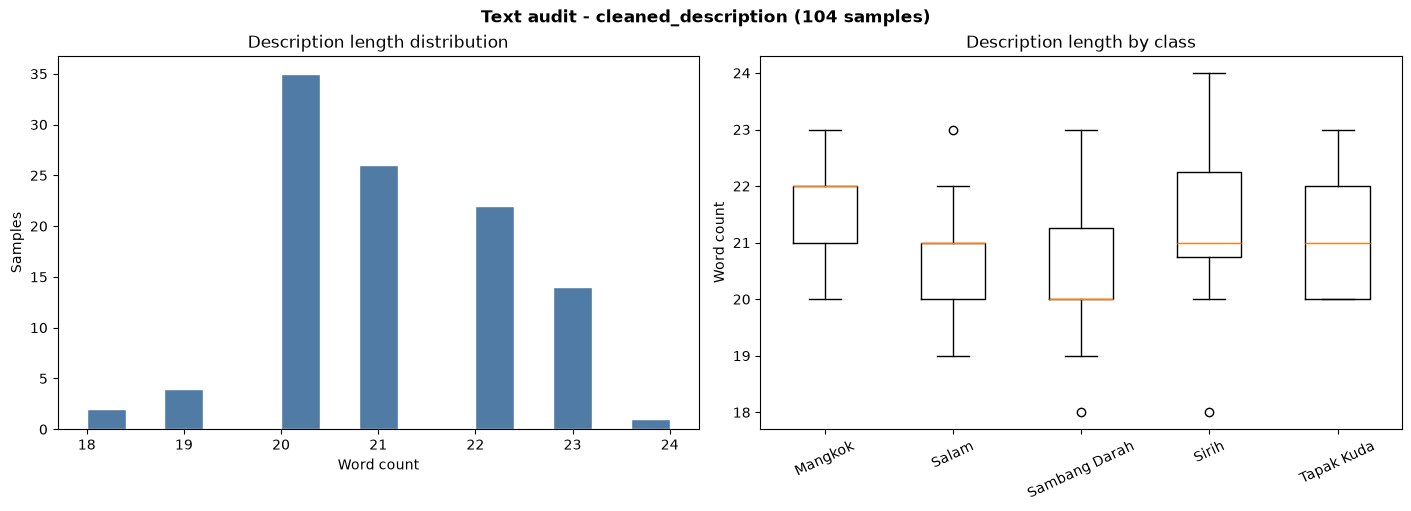

[SAVED] 201_raw_text_quality_audit.png


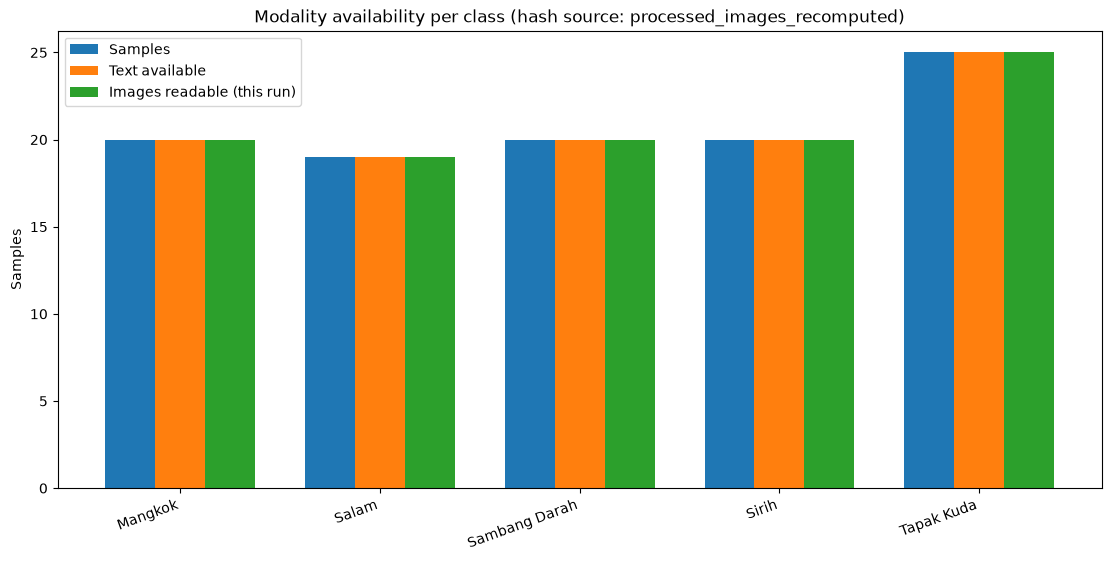

[SAVED] 202_raw_modality_availability.png
[SAVED] 606_raw_text_column_inventory.csv
[SAVED] 607_raw_text_leakage_audit.csv
[SAVED] 608_raw_image_audit.csv
[SAVED] 609_raw_class_data_quality.csv
[SAVED] 610_raw_duplicate_findings.csv
[SAVED] 611_raw_near_duplicate_image_pairs.csv
[SAVED] 612_provisional_split_groups.csv
[SAVED] 613_leakage_risk_assessment.csv
[SAVED] 614_split_readiness.csv
[SAVED] 615_raw_audit_validation.csv
[SAVED] 619_raw_data_audit_handoff.json

CELL 2 COMPLETED | readiness: REQUIRES_DATA_OR_LEAKAGE_REVIEW


In [2]:
# ============================================================
# CELL 2 - RAW DATA AUDIT & LEAKAGE DETECTION
# ============================================================
# Audits the ACTUAL text used for retrieval (cleaned_description) and the
# processed images. dHash near-duplicate pairs are only *candidates* for
# manual review; they do not prove leakage.

import re
import unicodedata
from PIL import Image, ImageOps

assert globals().get("EVAL06_SETUP_COMPLETED") is True, "Jalankan Cell 1 terlebih dahulu."

EVAL06_RAW_DATA_AUDIT_COMPLETED = False
eval06_audit_checks = []

print("NOTEBOOK 06 - CELL 2: RAW DATA AUDIT")
print("=" * 75)

EVAL06_AUDIT_DATA_DF = EVAL06_INDEX_DF.merge(
    EVAL06_METADATA_DF.drop(columns=["kelas"]), on="sample_id", how="left",
    validate="one_to_one", sort=False)
assert EVAL06_AUDIT_DATA_DF["sample_id"].tolist() == EVAL06_SAMPLE_IDS.tolist()

# ============================================================
# 1. TEXT SOURCE AUDIT
# ============================================================
# Bug fixed: the former candidate list did not contain "cleaned_description",
# so Cell 2 reported 104 missing descriptions although text was present.

EVAL06_TEXT_COLUMN_CANDIDATES = ("cleaned_description", "tokenized_description",
                                 "original_description", "description", "deskripsi")
EVAL06_TEXT_COLUMN = "cleaned_description"


def eval06_normalize_audit_text(value):
    if eval06_is_blank(value):
        return ""
    text = unicodedata.normalize("NFKC", str(value)).casefold()
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    return re.sub(r"\s+", " ", text).strip()


text_inventory = []
for column in EVAL06_TEXT_COLUMN_CANDIDATES:
    if column not in EVAL06_AUDIT_DATA_DF.columns:
        continue
    values = EVAL06_AUDIT_DATA_DF[column].map(eval06_normalize_audit_text)
    lengths = values.str.split().str.len().fillna(0)
    text_inventory.append({
        "column": column,
        "nonempty_count": int(values.ne("").sum()),
        "coverage_percent": float(100 * values.ne("").mean()),
        "median_word_count": float(lengths[values.ne("")].median()) if values.ne("").any() else 0.0,
        "unique_nonempty_texts": int(values[values.ne("")].nunique()),
        "selected_for_retrieval": column == EVAL06_TEXT_COLUMN,
    })
EVAL06_TEXT_COLUMN_INVENTORY_DF = pd.DataFrame(text_inventory)
assert EVAL06_TEXT_COLUMN in EVAL06_AUDIT_DATA_DF.columns, "cleaned_description tidak ada."

query_config = EVAL06_TEXT_SOURCE.json("text_query_preprocessing_config.json")
EVAL06_CLASS_ALIASES = sorted({eval06_normalize_audit_text(a) for a in
                               query_config.get("class_aliases", [])}
                              | {eval06_normalize_audit_text(c) for c in EVAL06_CLASSES})

rows = []
for record in EVAL06_AUDIT_DATA_DF.itertuples(index=False):
    normalized = eval06_normalize_audit_text(getattr(record, EVAL06_TEXT_COLUMN))
    own = eval06_normalize_audit_text(record.class_label)
    padded = f" {normalized} "
    rows.append({
        "matrix_row_index": record.matrix_row_index,
        "sample_id": record.sample_id,
        "class_label": record.class_label,
        "text_available": bool(normalized),
        "word_count": len(normalized.split()),
        "normalized_text": normalized,
        "text_sha256": eval06_sha256_bytes(normalized.encode()) if normalized else "",
        "own_class_name_mentioned": f" {own} " in padded,
        "any_class_alias_mentioned": any(f" {alias} " in padded for alias in EVAL06_CLASS_ALIASES),
    })
EVAL06_TEXT_AUDIT_DF = pd.DataFrame(rows)
text_counts = EVAL06_TEXT_AUDIT_DF.loc[EVAL06_TEXT_AUDIT_DF["text_available"], "text_sha256"].value_counts()
EVAL06_TEXT_AUDIT_DF["duplicate_text_count"] = EVAL06_TEXT_AUDIT_DF["text_sha256"].map(text_counts).fillna(0).astype(int)
EVAL06_TEXT_AUDIT_DF["repeated_description"] = EVAL06_TEXT_AUDIT_DF["duplicate_text_count"] > 1
classes_per_text = EVAL06_TEXT_AUDIT_DF.groupby("text_sha256")["class_label"].nunique()
EVAL06_TEXT_AUDIT_DF["description_shared_across_classes"] = (
    EVAL06_TEXT_AUDIT_DF["text_sha256"].map(classes_per_text).fillna(0).gt(1)
    & EVAL06_TEXT_AUDIT_DF["text_available"])

EVAL06_CLASS_TEXT_AUDIT_DF = (EVAL06_TEXT_AUDIT_DF.groupby("class_label")
    .agg(sample_count=("sample_id", "size"),
         text_available_count=("text_available", "sum"),
         unique_descriptions=("text_sha256", "nunique"),
         repeated_text_samples=("repeated_description", "sum"),
         label_mention_count=("own_class_name_mentioned", "sum"))
    .reset_index())
EVAL06_CLASS_TEXT_AUDIT_DF["class_level_template_suspected"] = (
    EVAL06_CLASS_TEXT_AUDIT_DF["text_available_count"].gt(1)
    & EVAL06_CLASS_TEXT_AUDIT_DF["unique_descriptions"].eq(1))

EVAL06_TEXT_MISSING_COUNT = int((~EVAL06_TEXT_AUDIT_DF["text_available"]).sum())
EVAL06_TEXT_DUPLICATE_COUNT = int(EVAL06_TEXT_AUDIT_DF["repeated_description"].sum())
EVAL06_LABEL_MENTION_COUNT = int(EVAL06_TEXT_AUDIT_DF["own_class_name_mentioned"].sum())
EVAL06_ANY_ALIAS_MENTION_COUNT = int(EVAL06_TEXT_AUDIT_DF["any_class_alias_mentioned"].sum())
EVAL06_CLASS_TEMPLATE_COUNT = int(EVAL06_CLASS_TEXT_AUDIT_DF["class_level_template_suspected"].sum())
EVAL06_CROSS_CLASS_TEXT_COLLISIONS = int(EVAL06_TEXT_AUDIT_DF["description_shared_across_classes"].sum())

print("\n1. TEXT AUDIT (column = cleaned_description)")
print("-" * 75)
display(EVAL06_TEXT_COLUMN_INVENTORY_DF)
print("Missing descriptions        :", EVAL06_TEXT_MISSING_COUNT)
print("Samples with repeated text  :", EVAL06_TEXT_DUPLICATE_COUNT)
print("Own class name mentioned    :", EVAL06_LABEL_MENTION_COUNT)
print("Any class alias mentioned   :", EVAL06_ANY_ALIAS_MENTION_COUNT)
print("Class-level templates       :", EVAL06_CLASS_TEMPLATE_COUNT)
print("Texts shared across classes :", EVAL06_CROSS_CLASS_TEXT_COLLISIONS)
display(EVAL06_CLASS_TEXT_AUDIT_DF)

# ============================================================
# 2. IMAGE AUDIT
# ============================================================
# Image paths in the metadata are relative to the project root.
# Optional extra roots: define EVAL06_IMAGE_SEARCH_ROOTS = [Path(...)]
# BEFORE running this cell.

EVAL06_IMAGE_COLUMN = "processed_image_path"
EVAL06_IMAGE_ROOTS = [EVAL06_PROJECT_ROOT] + [Path(p) for p in globals().get("EVAL06_IMAGE_SEARCH_ROOTS", [])]


def eval06_resolve_image(value):
    if eval06_is_blank(value):
        return None
    relative = Path(str(value).replace("\\", "/"))
    for candidate in [relative] + [root / relative for root in EVAL06_IMAGE_ROOTS]:
        if candidate.is_file():
            return candidate.resolve()
    return None


def eval06_image_dhash(image):
    small = image.convert("L").resize((9, 8), Image.Resampling.LANCZOS)
    pixels = np.asarray(small, dtype=np.int16)
    bits = (pixels[:, 1:] > pixels[:, :-1]).ravel()
    value = 0
    for bit in bits:
        value = (value << 1) | int(bit)
    return value


image_rows = []
for record in EVAL06_AUDIT_DATA_DF.itertuples(index=False):
    raw_value = getattr(record, EVAL06_IMAGE_COLUMN)
    resolved = eval06_resolve_image(raw_value)
    row = {"matrix_row_index": record.matrix_row_index, "sample_id": record.sample_id,
           "class_label": record.class_label, "raw_image_value": eval06_clean_str(raw_value),
           "resolved_image_path": str(resolved) if resolved else "", "image_found": resolved is not None,
           "image_readable": False, "width": np.nan, "height": np.nan, "file_sha256": "",
           "decoded_pixel_sha256": "", "dhash_hex": "", "read_error": ""}
    if resolved is not None:
        try:
            row["file_sha256"] = eval06_sha256_file(resolved)
            with Image.open(resolved) as source:
                image = ImageOps.exif_transpose(source).convert("RGB")
                row["width"], row["height"] = image.size
                row["decoded_pixel_sha256"] = eval06_sha256_bytes(
                    f"{image.size[0]}x{image.size[1]}|".encode() + image.tobytes())
                row["dhash_hex"] = f"{eval06_image_dhash(image):016x}"
                row["image_readable"] = True
        except (OSError, ValueError) as error:
            row["read_error"] = str(error)
    image_rows.append(row)
EVAL06_IMAGE_AUDIT_DF = pd.DataFrame(image_rows)
EVAL06_IMAGES_FOUND = int(EVAL06_IMAGE_AUDIT_DF["image_found"].sum())
EVAL06_IMAGES_READABLE = int(EVAL06_IMAGE_AUDIT_DF["image_readable"].sum())

# Source of the hashes used for duplicate detection.
EVAL06_IMAGE_HASH_SOURCE = "processed_images_recomputed"
EVAL06_IMAGE_HASH_DF = EVAL06_IMAGE_AUDIT_DF[["sample_id", "class_label", "file_sha256",
                                              "decoded_pixel_sha256", "dhash_hex"]].copy()

if EVAL06_IMAGES_READABLE < EVAL06_N_SAMPLES:
    legacy_608 = EVAL06_LEGACY_METRICS_DIR / "608_raw_image_audit.csv"
    legacy_ok = False
    if legacy_608.is_file():
        legacy = pd.read_csv(legacy_608, dtype=str, keep_default_na=False, encoding="utf-8-sig")
        needed = {"sample_id", "file_sha256", "decoded_pixel_sha256", "dhash_hex"}
        if needed.issubset(legacy.columns) and set(legacy["sample_id"]) == set(EVAL06_SAMPLE_IDS) \
                and legacy["dhash_hex"].str.len().eq(16).all():
            legacy_ok = True
            EVAL06_IMAGE_HASH_DF = (EVAL06_INDEX_DF[["sample_id", "class_label"]]
                                    .merge(legacy[list(needed)], on="sample_id", validate="one_to_one"))
            EVAL06_IMAGE_HASH_SOURCE = "LEGACY_608_HASHES_IMAGES_NOT_AVAILABLE"
            EVAL06_RUN_MANIFEST["legacy_files_used_as_inputs"].append(
                {"file": legacy_608.name, "sha256": eval06_sha256_file(legacy_608),
                 "purpose": "fallback image hashes for duplicate/near-duplicate audit (Cell 2)"})
    if not legacy_ok:
        EVAL06_IMAGE_HASH_SOURCE = "UNAVAILABLE"

print("\n2. IMAGE AUDIT")
print("-" * 75)
print("Images found / readable:", EVAL06_IMAGES_FOUND, "/", EVAL06_IMAGES_READABLE)
print("Hash source for duplicate audit:", EVAL06_IMAGE_HASH_SOURCE)
if EVAL06_IMAGE_HASH_SOURCE != "processed_images_recomputed":
    print("[WARNING] Processed images are not available in this environment.")
    print("          Image duplicate audit uses:", EVAL06_IMAGE_HASH_SOURCE)
    print("          Required for full verification: dataset/processed/images/<class>/... (104 files)")

# ============================================================
# 3. EXACT AND NEAR DUPLICATES
# ============================================================

duplicate_records = []


def eval06_collect_duplicates(frame, column, duplicate_type):
    valid = frame.loc[frame[column].astype(str).ne("")]
    for key, group in valid.groupby(column):
        if len(group) > 1:
            duplicate_records.append({
                "duplicate_type": duplicate_type, "duplicate_key": key,
                "sample_count": len(group), "class_count": group["class_label"].nunique(),
                "class_labels": " | ".join(sorted(group["class_label"].unique())),
                "sample_ids": " | ".join(group["sample_id"]),
                "cross_class_collision": group["class_label"].nunique() > 1})


eval06_collect_duplicates(EVAL06_TEXT_AUDIT_DF, "text_sha256", "exact_normalized_text")
eval06_collect_duplicates(EVAL06_IMAGE_HASH_DF, "file_sha256", "exact_image_file")
eval06_collect_duplicates(EVAL06_IMAGE_HASH_DF, "decoded_pixel_sha256", "exact_decoded_pixels")
EVAL06_DUPLICATE_FINDINGS_DF = pd.DataFrame(duplicate_records, columns=[
    "duplicate_type", "duplicate_key", "sample_count", "class_count", "class_labels",
    "sample_ids", "cross_class_collision"])

near_rows = []
hashed = EVAL06_IMAGE_HASH_DF.loc[EVAL06_IMAGE_HASH_DF["dhash_hex"].astype(str).str.len() == 16].reset_index(drop=True)
hash_ints = [int(h, 16) for h in hashed["dhash_hex"]]
for i in range(len(hashed)):
    for j in range(i + 1, len(hashed)):
        distance = (hash_ints[i] ^ hash_ints[j]).bit_count()
        if distance <= EVAL06_NEAR_DUPLICATE_DHASH_THRESHOLD and \
                hashed.at[i, "decoded_pixel_sha256"] != hashed.at[j, "decoded_pixel_sha256"]:
            near_rows.append({
                "sample_id_i": hashed.at[i, "sample_id"], "sample_id_j": hashed.at[j, "sample_id"],
                "class_i": hashed.at[i, "class_label"], "class_j": hashed.at[j, "class_label"],
                "same_class": hashed.at[i, "class_label"] == hashed.at[j, "class_label"],
                "dhash_hamming_distance": distance, "hash_source": EVAL06_IMAGE_HASH_SOURCE,
                "manual_review_required": True})
EVAL06_NEAR_DUPLICATE_DF = pd.DataFrame(near_rows, columns=[
    "sample_id_i", "sample_id_j", "class_i", "class_j", "same_class",
    "dhash_hamming_distance", "hash_source", "manual_review_required"])

image_dup = EVAL06_DUPLICATE_FINDINGS_DF["duplicate_type"].isin(["exact_image_file", "exact_decoded_pixels"])
EVAL06_CROSS_CLASS_IMAGE_COLLISIONS = int((image_dup & EVAL06_DUPLICATE_FINDINGS_DF["cross_class_collision"]).sum())
EVAL06_EXACT_IMAGE_DUPLICATE_GROUPS = int(image_dup.sum())
EVAL06_NEAR_DUPLICATE_PAIR_COUNT = len(EVAL06_NEAR_DUPLICATE_DF)

print("\n3. DUPLICATES")
print("-" * 75)
print("Exact image duplicate groups :", EVAL06_EXACT_IMAGE_DUPLICATE_GROUPS)
print("Exact text duplicate groups  :", int(EVAL06_DUPLICATE_FINDINGS_DF["duplicate_type"].eq("exact_normalized_text").sum()))
print("Near-duplicate image pairs   :", EVAL06_NEAR_DUPLICATE_PAIR_COUNT,
      f"(dHash Hamming <= {EVAL06_NEAR_DUPLICATE_DHASH_THRESHOLD})")
display(EVAL06_NEAR_DUPLICATE_DF.head(10))

# ============================================================
# 4. GROUPS FOR SPLITTING (exact image duplicates are atomic)
# ============================================================

EVAL06_GROUP_COLUMN_CANDIDATES = ("group_id", "specimen_id", "plant_id", "capture_session",
                                  "session_id", "original_image_id", "source_image_id", "leaf_id")
EVAL06_AVAILABLE_GROUP_COLUMNS = [c for c in EVAL06_GROUP_COLUMN_CANDIDATES if c in EVAL06_AUDIT_DATA_DF.columns]
EVAL06_GROUP_COLUMN = EVAL06_AVAILABLE_GROUP_COLUMNS[0] if EVAL06_AVAILABLE_GROUP_COLUMNS else None

parent = list(range(EVAL06_N_SAMPLES))


def eval06_find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


def eval06_union_equal_values(values):
    seen = {}
    for position, value in enumerate(values):
        if eval06_is_blank(value):
            continue
        if value in seen:
            a, b = eval06_find(position), eval06_find(seen[value])
            if a != b:
                parent[max(a, b)] = min(a, b)
        else:
            seen[value] = position


hash_aligned = EVAL06_INDEX_DF[["sample_id"]].merge(EVAL06_IMAGE_HASH_DF, on="sample_id", how="left")
eval06_union_equal_values(hash_aligned["file_sha256"].fillna("").tolist())
eval06_union_equal_values(hash_aligned["decoded_pixel_sha256"].fillna("").tolist())
if EVAL06_GROUP_COLUMN is not None:
    eval06_union_equal_values(EVAL06_AUDIT_DATA_DF[EVAL06_GROUP_COLUMN].tolist())

roots = [eval06_find(i) for i in range(EVAL06_N_SAMPLES)]
root_ids = {root: f"group_{k:03d}" for k, root in enumerate(sorted(set(roots)))}
EVAL06_SPLIT_GROUPS_DF = pd.DataFrame({
    "matrix_row_index": np.arange(EVAL06_N_SAMPLES), "sample_id": EVAL06_SAMPLE_IDS,
    "class_label": EVAL06_LABELS, "provisional_group_id": [root_ids[r] for r in roots]})
EVAL06_SPLIT_GROUPS_DF["provisional_group_size"] = EVAL06_SPLIT_GROUPS_DF["provisional_group_id"].map(
    EVAL06_SPLIT_GROUPS_DF["provisional_group_id"].value_counts())
EVAL06_SPLIT_GROUP_FEASIBLE = bool(EVAL06_SPLIT_GROUPS_DF.groupby("class_label")["provisional_group_id"].nunique().ge(3).all())

print("\n4. SPLIT GROUPS")
print("-" * 75)
print("Declared specimen/group column:", EVAL06_GROUP_COLUMN)
print("Provisional groups:", EVAL06_SPLIT_GROUPS_DF["provisional_group_id"].nunique(),
      "| multi-sample groups:", int(EVAL06_SPLIT_GROUPS_DF["provisional_group_size"].gt(1).sum()))

# ============================================================
# 5. CLASS QUALITY, RISK ASSESSMENT, READINESS
# ============================================================

EVAL06_CLASS_DATA_QUALITY_DF = pd.DataFrame([{
    "class_name": c,
    "sample_count": int((EVAL06_LABELS == c).sum()),
    "text_available": int(EVAL06_TEXT_AUDIT_DF.loc[EVAL06_TEXT_AUDIT_DF["class_label"] == c, "text_available"].sum()),
    "unique_text_descriptions": int(EVAL06_TEXT_AUDIT_DF.loc[EVAL06_TEXT_AUDIT_DF["class_label"] == c, "text_sha256"].nunique()),
    "images_readable": int(EVAL06_IMAGE_AUDIT_DF.loc[EVAL06_IMAGE_AUDIT_DF["class_label"] == c, "image_readable"].sum()),
    "provisional_split_groups": int(EVAL06_SPLIT_GROUPS_DF.loc[EVAL06_SPLIT_GROUPS_DF["class_label"] == c, "provisional_group_id"].nunique()),
} for c in EVAL06_CLASSES])

image_audit_complete = EVAL06_IMAGE_HASH_SOURCE == "processed_images_recomputed"
EVAL06_LEAKAGE_FINDINGS_DF = pd.DataFrame([
    ("Missing text descriptions", "High", EVAL06_TEXT_MISSING_COUNT, EVAL06_TEXT_MISSING_COUNT > 0),
    ("Processed images not available for pixel audit", "Medium",
     EVAL06_N_SAMPLES - EVAL06_IMAGES_READABLE, not image_audit_complete),
    ("Own class name inside description", "High", EVAL06_LABEL_MENTION_COUNT, EVAL06_LABEL_MENTION_COUNT > 0),
    ("Class-level single-description template", "High", EVAL06_CLASS_TEMPLATE_COUNT, EVAL06_CLASS_TEMPLATE_COUNT > 0),
    ("Identical text shared across classes", "Medium", EVAL06_CROSS_CLASS_TEXT_COLLISIONS, EVAL06_CROSS_CLASS_TEXT_COLLISIONS > 0),
    ("Repeated identical descriptions", "Medium", EVAL06_TEXT_DUPLICATE_COUNT, EVAL06_TEXT_DUPLICATE_COUNT > 0),
    ("Identical image with different classes", "High", EVAL06_CROSS_CLASS_IMAGE_COLLISIONS, EVAL06_CROSS_CLASS_IMAGE_COLLISIONS > 0),
    ("Possible near-duplicate images (dHash)", "Medium", EVAL06_NEAR_DUPLICATE_PAIR_COUNT, EVAL06_NEAR_DUPLICATE_PAIR_COUNT > 0),
    ("No declared specimen/capture identity", "Medium", int(EVAL06_GROUP_COLUMN is None), EVAL06_GROUP_COLUMN is None),
], columns=["risk", "severity", "finding_count", "requires_review"])

EVAL06_READINESS_DF = pd.DataFrame([
    ("Text complete", EVAL06_TEXT_MISSING_COUNT == 0),
    ("Image pixel audit recomputed from processed images", image_audit_complete),
    ("No own-class name in text", EVAL06_LABEL_MENTION_COUNT == 0),
    ("No class-level text template", EVAL06_CLASS_TEMPLATE_COUNT == 0),
    ("No cross-class identical image", EVAL06_CROSS_CLASS_IMAGE_COLLISIONS == 0),
    ("No unreviewed near-duplicate image pairs", EVAL06_NEAR_DUPLICATE_PAIR_COUNT == 0),
    ("At least three groups per class", EVAL06_SPLIT_GROUP_FEASIBLE),
    ("Specimen identity declared", EVAL06_GROUP_COLUMN is not None),
], columns=["criterion", "passed"])
EVAL06_READY_FOR_SPLIT_PLANNING = bool(EVAL06_READINESS_DF["passed"].all())
EVAL06_SPLIT_READINESS_STATUS = ("READY_FOR_SPLIT_PLANNING" if EVAL06_READY_FOR_SPLIT_PLANNING
                                 else "REQUIRES_DATA_OR_LEAKAGE_REVIEW")

print("\n5. LEAKAGE RISK ASSESSMENT")
print("-" * 75)
display(EVAL06_LEAKAGE_FINDINGS_DF)
display(EVAL06_READINESS_DF)
print("Readiness status:", EVAL06_SPLIT_READINESS_STATUS)

# ============================================================
# 6. TECHNICAL CHECKS
# ============================================================

eval06_check(eval06_audit_checks, "Text", "104 text audit records aligned",
             EVAL06_TEXT_AUDIT_DF["sample_id"].tolist() == EVAL06_SAMPLE_IDS.tolist())
eval06_check(eval06_audit_checks, "Text", "All 104 cleaned descriptions available",
             EVAL06_TEXT_MISSING_COUNT == 0)
eval06_check(eval06_audit_checks, "Images", "104 image audit records aligned",
             EVAL06_IMAGE_AUDIT_DF["sample_id"].tolist() == EVAL06_SAMPLE_IDS.tolist())
eval06_check(eval06_audit_checks, "Images", "Image hashes available for duplicate audit",
             EVAL06_IMAGE_HASH_SOURCE != "UNAVAILABLE", detail=EVAL06_IMAGE_HASH_SOURCE, severity="REVIEW")
eval06_check(eval06_audit_checks, "Images", "Processed images recomputed in this run",
             image_audit_complete, detail=f"readable={EVAL06_IMAGES_READABLE}", severity="REVIEW")
eval06_check(eval06_audit_checks, "Grouping", "Every sample has one group",
             EVAL06_SPLIT_GROUPS_DF["provisional_group_id"].notna().all())
eval06_check(eval06_audit_checks, "Grouping", "Exact image duplicates share one group",
             all(EVAL06_SPLIT_GROUPS_DF.set_index("sample_id").loc[s.split(" | "), "provisional_group_id"].nunique() == 1
                 for s in EVAL06_DUPLICATE_FINDINGS_DF.loc[image_dup, "sample_ids"]))
EVAL06_AUDIT_VALIDATION_DF = eval06_checks_frame(eval06_audit_checks)
display(EVAL06_AUDIT_VALIDATION_DF)

# ============================================================
# 7. FIGURES
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
axes[0].hist(EVAL06_TEXT_AUDIT_DF["word_count"], bins=15, color="#507BA5", edgecolor="white")
axes[0].set(title="Description length distribution", xlabel="Word count", ylabel="Samples")
eval06_boxplot(axes[1], [EVAL06_TEXT_AUDIT_DF.loc[EVAL06_TEXT_AUDIT_DF["class_label"] == c, "word_count"]
                         for c in EVAL06_CLASSES], EVAL06_CLASSES)
axes[1].set(title="Description length by class", ylabel="Word count")
axes[1].tick_params(axis="x", labelrotation=25)
fig.suptitle("Text audit - cleaned_description (104 samples)", fontweight="bold")
eval06_save_figure(fig, "201_raw_text_quality_audit.png", 2)

fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
plot = EVAL06_CLASS_DATA_QUALITY_DF.set_index("class_name").loc[EVAL06_CLASSES]
x = np.arange(len(EVAL06_CLASSES))
for offset, column, label in [(-0.25, "sample_count", "Samples"),
                              (0.0, "text_available", "Text available"),
                              (0.25, "images_readable", "Images readable (this run)")]:
    ax.bar(x + offset, plot[column], width=0.25, label=label)
ax.set_xticks(x, EVAL06_CLASSES, rotation=20, ha="right")
ax.set(ylabel="Samples", title=f"Modality availability per class (hash source: {EVAL06_IMAGE_HASH_SOURCE})")
ax.legend()
eval06_save_figure(fig, "202_raw_modality_availability.png", 2)

# ============================================================
# 8. SAVE REPORTS
# ============================================================

eval06_save_csv(EVAL06_TEXT_COLUMN_INVENTORY_DF, "606_raw_text_column_inventory.csv", 2)
eval06_save_csv(EVAL06_TEXT_AUDIT_DF, "607_raw_text_leakage_audit.csv", 2)
eval06_save_csv(EVAL06_IMAGE_AUDIT_DF, "608_raw_image_audit.csv", 2)
eval06_save_csv(EVAL06_CLASS_DATA_QUALITY_DF, "609_raw_class_data_quality.csv", 2)
eval06_save_csv(EVAL06_DUPLICATE_FINDINGS_DF, "610_raw_duplicate_findings.csv", 2)
eval06_save_csv(EVAL06_NEAR_DUPLICATE_DF, "611_raw_near_duplicate_image_pairs.csv", 2)
eval06_save_csv(EVAL06_SPLIT_GROUPS_DF, "612_provisional_split_groups.csv", 2)
eval06_save_csv(EVAL06_LEAKAGE_FINDINGS_DF, "613_leakage_risk_assessment.csv", 2)
eval06_save_csv(EVAL06_READINESS_DF, "614_split_readiness.csv", 2)
eval06_save_csv(EVAL06_AUDIT_VALIDATION_DF, "615_raw_audit_validation.csv", 2)
eval06_save_json({
    "cell": 2, "text_column": EVAL06_TEXT_COLUMN, "image_hash_source": EVAL06_IMAGE_HASH_SOURCE,
    "images_readable": EVAL06_IMAGES_READABLE, "near_duplicate_pairs": EVAL06_NEAR_DUPLICATE_PAIR_COUNT,
    "repeated_text_samples": EVAL06_TEXT_DUPLICATE_COUNT, "readiness_status": EVAL06_SPLIT_READINESS_STATUS,
    "leakage_confirmed": False, "note": "Candidates require manual review; they do not prove leakage.",
}, "619_raw_data_audit_handoff.json", 2)

eval06_require(EVAL06_AUDIT_VALIDATION_DF, "Cell 2")
EVAL06_RAW_DATA_AUDIT_COMPLETED = True
print("\nCELL 2 COMPLETED | readiness:", EVAL06_SPLIT_READINESS_STATUS)

## Cell 3 — Dataset Splitting (group-aware, seed 42)

NOTEBOOK 06 - CELL 3: GROUP-AWARE DATASET SPLITTING

1. SPLIT CLASS DISTRIBUTION
---------------------------------------------------------------------------


split,gallery,validation,test,total
class_label,,,,
Mangkok,12,4,4,20
Salam,11,4,4,19
Sambang Darah,12,4,4,20
Sirih,12,4,4,20
Tapak Kuda,15,5,5,25


,split,target_ratio,target_sample_count,actual_sample_count,actual_ratio,ratio_deviation
0,gallery,0.6,62.4,62,0.596154,-0.003846
1,validation,0.2,20.8,21,0.201923,0.001923
2,test,0.2,20.8,21,0.201923,0.001923


Cross-split near-duplicate candidates: 44
Cross-split repeated-description groups: 4
Identical to legacy split (620): True
Split fingerprint: 7f5cb9c76cdbb248


,category,validation_check,passed,severity_if_failed,detail
0,Structure,All 104 samples assigned to exactly one split,True,BLOCK,
1,Structure,"Gallery, validation and test are disjoint (sam...",True,BLOCK,
2,Structure,Groups never cross splits,True,BLOCK,
3,Structure,Every class appears in every split,True,BLOCK,
4,Structure,Sample order preserved inside every split,True,BLOCK,
5,Leakage,No exact duplicate image crosses splits,True,BLOCK,
6,Leakage,No cross-split near-duplicate candidates,False,REVIEW,pairs=44
7,Leakage,No identical description crosses splits,False,REVIEW,groups=4
8,Methodology,No retrieval score used for splitting,True,BLOCK,
9,Reproducibility,Split identical to legacy 620 assignment,True,REVIEW,legacy_available=True


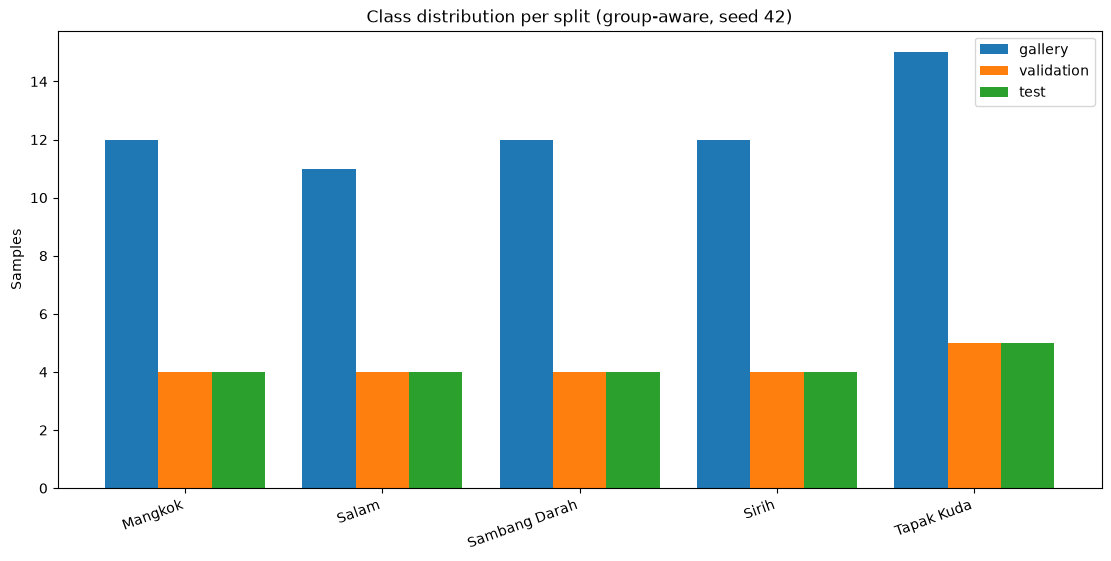

[SAVED] 203_group_aware_split_class_distribution.png


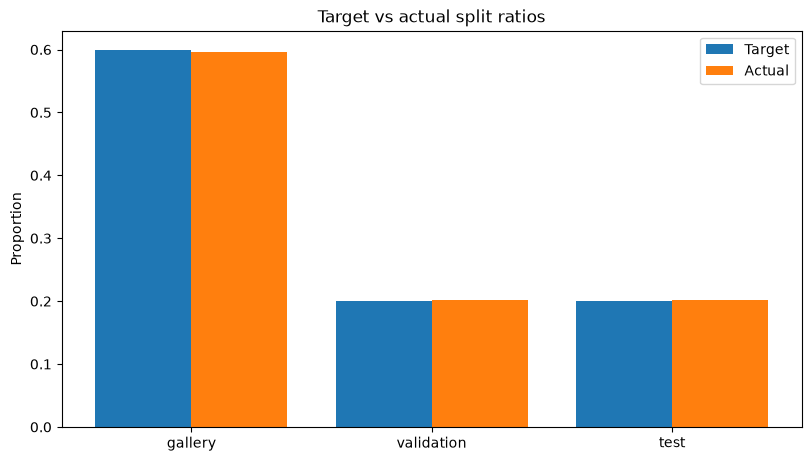

[SAVED] 204_group_aware_split_ratio_comparison.png
[SAVED] 620_group_aware_split_assignments.csv
[SAVED] 621_group_aware_split_class_counts.csv
[SAVED] 622_group_aware_split_ratios.csv
[SAVED] 623_split_cross_partition_exact_images.csv
[SAVED] 624_split_near_duplicate_review.csv
[SAVED] 625_split_repeated_text_review.csv
[SAVED] 626_group_aware_split_validation.csv

CELL 3 COMPLETED | split status: PROVISIONAL_REVIEW_REQUIRED | sizes: {'gallery': 62, 'validation': 21, 'test': 21}


In [3]:
# ============================================================
# CELL 3 - GROUP-AWARE DATASET SPLITTING (gallery / validation / test)
# ============================================================
# Same deterministic algorithm and seed as the original notebook
# (stratified, group-aware greedy assignment + local search, seed 42).
# The objective uses only class labels, group sizes and target ratios;
# no similarity or retrieval score is used.

assert globals().get("EVAL06_RAW_DATA_AUDIT_COMPLETED") is True, "Jalankan Cell 2 terlebih dahulu."

EVAL06_SPLIT_COMPLETED = False
eval06_split_checks = []

print("NOTEBOOK 06 - CELL 3: GROUP-AWARE DATASET SPLITTING")
print("=" * 75)

SPLIT03_RATIOS = np.array([EVAL06_SPLIT_RATIOS[s] for s in EVAL06_SPLIT_NAMES], dtype=float)
SPLIT03_RESTARTS = 120
SPLIT03_LOCAL_SWEEPS = 4

split_base = EVAL06_INDEX_DF.merge(EVAL06_SPLIT_GROUPS_DF[["sample_id", "provisional_group_id"]],
                                   on="sample_id", validate="one_to_one")
group_counts = pd.crosstab(split_base["provisional_group_id"], split_base["class_label"]) \
    .reindex(columns=EVAL06_CLASSES, fill_value=0).sort_index()
group_names = group_counts.index.astype(str).tolist()
group_matrix = group_counts.to_numpy(dtype=int)
group_sizes = group_matrix.sum(axis=1)
n_groups = len(group_names)
class_counts = group_matrix.sum(axis=0)
target_by_class = class_counts[:, None] * SPLIT03_RATIOS[None, :]
target_overall = EVAL06_N_SAMPLES * SPLIT03_RATIOS
EVAL06_MIXED_LABEL_GROUPS = int(((group_matrix > 0).sum(axis=1) > 1).sum())


def split03_objective(counts):
    class_error = np.sum((counts - target_by_class) ** 2 / (target_by_class + 1.0))
    total_error = np.sum((counts.sum(axis=0) - target_overall) ** 2 / (target_overall + 1.0))
    return float(class_error + 0.4 * total_error + 1000.0 * int(np.sum(counts == 0)))


rng = np.random.default_rng(EVAL06_RANDOM_STATE)
best_assignment, best_score = None, np.inf
for restart in range(SPLIT03_RESTARTS):
    shuffled = rng.permutation(n_groups)
    order = shuffled[np.argsort(-group_sizes[shuffled], kind="stable")]
    assignment = np.full(n_groups, -1, dtype=int)
    counts = np.zeros((len(EVAL06_CLASSES), 3), dtype=int)
    for g in order:
        costs = []
        for s in range(3):
            proposed = counts.copy()
            proposed[:, s] += group_matrix[g]
            costs.append(split03_objective(proposed))
        s = int(np.argmin(np.asarray(costs) + rng.random(3) * 1e-8))
        assignment[g] = s
        counts[:, s] += group_matrix[g]
    for sweep in range(SPLIT03_LOCAL_SWEEPS):
        improved = False
        for g in rng.permutation(n_groups):
            previous = int(assignment[g])
            best_move, best_move_score = previous, split03_objective(counts)
            for candidate in range(3):
                if candidate == previous:
                    continue
                proposed = counts.copy()
                proposed[:, previous] -= group_matrix[g]
                proposed[:, candidate] += group_matrix[g]
                score = split03_objective(proposed)
                if score < best_move_score - 1e-12:
                    best_move, best_move_score = candidate, score
            if best_move != previous:
                counts[:, previous] -= group_matrix[g]
                counts[:, best_move] += group_matrix[g]
                assignment[g] = best_move
                improved = True
        if not improved:
            break
    final_score = split03_objective(counts)
    if final_score < best_score - 1e-12:
        best_score, best_assignment = final_score, assignment.copy()

assignment_map = {group_names[g]: EVAL06_SPLIT_NAMES[int(best_assignment[g])] for g in range(n_groups)}
EVAL06_SPLIT_ASSIGNMENTS_DF = split_base.rename(columns={"provisional_group_id": "split_group_id"})
EVAL06_SPLIT_ASSIGNMENTS_DF["split"] = EVAL06_SPLIT_ASSIGNMENTS_DF["split_group_id"].map(assignment_map)
EVAL06_SPLIT_ASSIGNMENTS_DF["split_seed"] = EVAL06_RANDOM_STATE

EVAL06_SPLIT_INDICES = {s: EVAL06_SPLIT_ASSIGNMENTS_DF.loc[EVAL06_SPLIT_ASSIGNMENTS_DF["split"] == s,
                                                           "matrix_row_index"].to_numpy(dtype=int)
                        for s in EVAL06_SPLIT_NAMES}
EVAL06_SPLIT_SAMPLE_IDS = {s: EVAL06_SAMPLE_IDS[EVAL06_SPLIT_INDICES[s]].tolist() for s in EVAL06_SPLIT_NAMES}
EVAL06_SPLIT_LABELS = {s: EVAL06_LABELS[EVAL06_SPLIT_INDICES[s]] for s in EVAL06_SPLIT_NAMES}
EVAL06_SPLIT_LOOKUP = EVAL06_SPLIT_ASSIGNMENTS_DF.set_index("sample_id")["split"].to_dict()

EVAL06_SPLIT_CLASS_COUNTS_DF = pd.crosstab(EVAL06_SPLIT_ASSIGNMENTS_DF["class_label"],
                                           EVAL06_SPLIT_ASSIGNMENTS_DF["split"]) \
    .reindex(index=EVAL06_CLASSES, columns=list(EVAL06_SPLIT_NAMES), fill_value=0)
EVAL06_SPLIT_CLASS_COUNTS_DF["total"] = EVAL06_SPLIT_CLASS_COUNTS_DF.sum(axis=1)
EVAL06_SPLIT_SUMMARY_DF = pd.DataFrame({
    "split": EVAL06_SPLIT_NAMES, "target_ratio": SPLIT03_RATIOS, "target_sample_count": target_overall,
    "actual_sample_count": [len(EVAL06_SPLIT_INDICES[s]) for s in EVAL06_SPLIT_NAMES]})
EVAL06_SPLIT_SUMMARY_DF["actual_ratio"] = EVAL06_SPLIT_SUMMARY_DF["actual_sample_count"] / EVAL06_N_SAMPLES
EVAL06_SPLIT_SUMMARY_DF["ratio_deviation"] = EVAL06_SPLIT_SUMMARY_DF["actual_ratio"] - EVAL06_SPLIT_SUMMARY_DF["target_ratio"]

# ------------------------------------------------------------
# Cross-split review tables (near-duplicates and repeated texts)
# ------------------------------------------------------------
EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF = EVAL06_NEAR_DUPLICATE_DF.copy()
EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF["split_i"] = EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF["sample_id_i"].map(EVAL06_SPLIT_LOOKUP)
EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF["split_j"] = EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF["sample_id_j"].map(EVAL06_SPLIT_LOOKUP)
EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF["cross_split"] = (
    EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF["split_i"] != EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF["split_j"])
EVAL06_CROSS_SPLIT_NEAR_DUPLICATES = int(EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF["cross_split"].sum())

text_split = EVAL06_TEXT_AUDIT_DF.loc[EVAL06_TEXT_AUDIT_DF["text_available"],
                                      ["sample_id", "class_label", "text_sha256", "normalized_text"]].copy()
text_split["split"] = text_split["sample_id"].map(EVAL06_SPLIT_LOOKUP)
EVAL06_SPLIT_REPEATED_TEXT_DF = (text_split.groupby("text_sha256")
    .agg(sample_count=("sample_id", "size"), class_count=("class_label", "nunique"),
         split_count=("split", "nunique"),
         sample_ids=("sample_id", lambda v: " | ".join(v)),
         classes=("class_label", lambda v: " | ".join(sorted(set(v)))),
         splits=("split", lambda v: " | ".join(sorted(set(v)))),
         excerpt=("normalized_text", lambda v: v.iloc[0][:90]))
    .reset_index())
EVAL06_SPLIT_REPEATED_TEXT_DF = EVAL06_SPLIT_REPEATED_TEXT_DF.loc[
    EVAL06_SPLIT_REPEATED_TEXT_DF["sample_count"] > 1].reset_index(drop=True)
EVAL06_SPLIT_REPEATED_TEXT_DF["cross_split"] = EVAL06_SPLIT_REPEATED_TEXT_DF["split_count"] > 1
EVAL06_CROSS_SPLIT_TEXT_GROUPS = int(EVAL06_SPLIT_REPEATED_TEXT_DF["cross_split"].sum())

exact_hash = EVAL06_INDEX_DF[["sample_id"]].merge(EVAL06_IMAGE_HASH_DF, on="sample_id", how="left")
exact_hash["split"] = exact_hash["sample_id"].map(EVAL06_SPLIT_LOOKUP)
exact_rows = []
for column in ("file_sha256", "decoded_pixel_sha256"):
    valid = exact_hash.loc[exact_hash[column].fillna("").ne("")]
    for key, group in valid.groupby(column):
        if group["split"].nunique() > 1:
            exact_rows.append({"hash_type": column, "hash_value": key,
                               "sample_ids": " | ".join(group["sample_id"]),
                               "splits": " | ".join(sorted(group["split"].unique()))})
EVAL06_CROSS_SPLIT_EXACT_IMAGES_DF = pd.DataFrame(exact_rows, columns=["hash_type", "hash_value", "sample_ids", "splits"])

# ------------------------------------------------------------
# Comparison with legacy split (information only)
# ------------------------------------------------------------
legacy_620 = EVAL06_LEGACY_METRICS_DIR / "620_group_aware_split_assignments.csv"
if legacy_620.is_file():
    legacy_split = pd.read_csv(legacy_620, dtype=str, encoding="utf-8-sig").set_index("sample_id")["split"]
    EVAL06_SPLIT_MATCHES_LEGACY = bool(
        set(legacy_split.index) == set(EVAL06_SAMPLE_IDS)
        and all(legacy_split[s] == EVAL06_SPLIT_LOOKUP[s] for s in EVAL06_SAMPLE_IDS))
else:
    EVAL06_SPLIT_MATCHES_LEGACY = None

# ------------------------------------------------------------
# Checks
# ------------------------------------------------------------
sets = {s: set(EVAL06_SPLIT_SAMPLE_IDS[s]) for s in EVAL06_SPLIT_NAMES}
eval06_check(eval06_split_checks, "Structure", "All 104 samples assigned to exactly one split",
             EVAL06_SPLIT_ASSIGNMENTS_DF["split"].isin(EVAL06_SPLIT_NAMES).all()
             and sum(len(v) for v in sets.values()) == EVAL06_N_SAMPLES)
eval06_check(eval06_split_checks, "Structure", "Gallery, validation and test are disjoint (sample_id)",
             not (sets["gallery"] & sets["validation"]) and not (sets["gallery"] & sets["test"])
             and not (sets["validation"] & sets["test"]))
eval06_check(eval06_split_checks, "Structure", "Groups never cross splits",
             EVAL06_SPLIT_ASSIGNMENTS_DF.groupby("split_group_id")["split"].nunique().eq(1).all())
eval06_check(eval06_split_checks, "Structure", "Every class appears in every split",
             EVAL06_SPLIT_CLASS_COUNTS_DF[list(EVAL06_SPLIT_NAMES)].gt(0).all().all())
eval06_check(eval06_split_checks, "Structure", "Sample order preserved inside every split",
             all(np.all(np.diff(EVAL06_SPLIT_INDICES[s]) > 0) for s in EVAL06_SPLIT_NAMES))
eval06_check(eval06_split_checks, "Leakage", "No exact duplicate image crosses splits",
             EVAL06_CROSS_SPLIT_EXACT_IMAGES_DF.empty)
eval06_check(eval06_split_checks, "Leakage", "No cross-split near-duplicate candidates",
             EVAL06_CROSS_SPLIT_NEAR_DUPLICATES == 0,
             detail=f"pairs={EVAL06_CROSS_SPLIT_NEAR_DUPLICATES}", severity="REVIEW")
eval06_check(eval06_split_checks, "Leakage", "No identical description crosses splits",
             EVAL06_CROSS_SPLIT_TEXT_GROUPS == 0, detail=f"groups={EVAL06_CROSS_SPLIT_TEXT_GROUPS}", severity="REVIEW")
eval06_check(eval06_split_checks, "Methodology", "No retrieval score used for splitting", True)
eval06_check(eval06_split_checks, "Reproducibility", "Split identical to legacy 620 assignment",
             bool(EVAL06_SPLIT_MATCHES_LEGACY), detail=f"legacy_available={EVAL06_SPLIT_MATCHES_LEGACY is not None}",
             severity="REVIEW")
EVAL06_SPLIT_VALIDATION_DF = eval06_checks_frame(eval06_split_checks)

EVAL06_SPLIT_FINGERPRINT = eval06_sha256_bytes(eval06_canonical_json(
    {s: EVAL06_SPLIT_SAMPLE_IDS[s] for s in EVAL06_SPLIT_NAMES}).encode())
EVAL06_RUN_MANIFEST["stage_fingerprints"]["split"] = EVAL06_SPLIT_FINGERPRINT
eval06_update_registry(split_fingerprint=EVAL06_SPLIT_FINGERPRINT)

print("\n1. SPLIT CLASS DISTRIBUTION")
print("-" * 75)
display(EVAL06_SPLIT_CLASS_COUNTS_DF)
display(EVAL06_SPLIT_SUMMARY_DF)
print("Cross-split near-duplicate candidates:", EVAL06_CROSS_SPLIT_NEAR_DUPLICATES)
print("Cross-split repeated-description groups:", EVAL06_CROSS_SPLIT_TEXT_GROUPS)
print("Identical to legacy split (620):", EVAL06_SPLIT_MATCHES_LEGACY)
print("Split fingerprint:", EVAL06_SPLIT_FINGERPRINT[:16])
display(EVAL06_SPLIT_VALIDATION_DF)

fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
x = np.arange(len(EVAL06_CLASSES))
for k, s in enumerate(EVAL06_SPLIT_NAMES):
    ax.bar(x + (k - 1) * 0.27, EVAL06_SPLIT_CLASS_COUNTS_DF[s], width=0.27, label=s)
ax.set_xticks(x, EVAL06_CLASSES, rotation=20, ha="right")
ax.set(ylabel="Samples", title="Class distribution per split (group-aware, seed 42)")
ax.legend()
eval06_save_figure(fig, "203_group_aware_split_class_distribution.png", 3)

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
x = np.arange(3)
ax.bar(x - 0.2, EVAL06_SPLIT_SUMMARY_DF["target_ratio"], width=0.4, label="Target")
ax.bar(x + 0.2, EVAL06_SPLIT_SUMMARY_DF["actual_ratio"], width=0.4, label="Actual")
ax.set_xticks(x, EVAL06_SPLIT_NAMES)
ax.set(ylabel="Proportion", title="Target vs actual split ratios")
ax.legend()
eval06_save_figure(fig, "204_group_aware_split_ratio_comparison.png", 3)

eval06_save_csv(EVAL06_SPLIT_ASSIGNMENTS_DF, "620_group_aware_split_assignments.csv", 3)
eval06_save_csv(EVAL06_SPLIT_CLASS_COUNTS_DF.reset_index(), "621_group_aware_split_class_counts.csv", 3)
eval06_save_csv(EVAL06_SPLIT_SUMMARY_DF, "622_group_aware_split_ratios.csv", 3)
eval06_save_csv(EVAL06_CROSS_SPLIT_EXACT_IMAGES_DF, "623_split_cross_partition_exact_images.csv", 3)
eval06_save_csv(EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF, "624_split_near_duplicate_review.csv", 3)
eval06_save_csv(EVAL06_SPLIT_REPEATED_TEXT_DF, "625_split_repeated_text_review.csv", 3)
eval06_save_csv(EVAL06_SPLIT_VALIDATION_DF, "626_group_aware_split_validation.csv", 3)

eval06_require(EVAL06_SPLIT_VALIDATION_DF, "Cell 3")
EVAL06_SPLIT_STATUS = "PROVISIONAL_REVIEW_REQUIRED" if (
    EVAL06_CROSS_SPLIT_NEAR_DUPLICATES or EVAL06_CROSS_SPLIT_TEXT_GROUPS
    or not EVAL06_READY_FOR_SPLIT_PLANNING) else "STRUCTURALLY_VALID"
EVAL06_SPLIT_COMPLETED = True
print("\nCELL 3 COMPLETED | split status:", EVAL06_SPLIT_STATUS,
      "| sizes:", {s: len(v) for s, v in EVAL06_SPLIT_SAMPLE_IDS.items()})

## Cell 4 — Feature Preparation (verifikasi sumber, tanpa fitting)
Ekstraktor alternatif lama dihapus. Fitur visual = vektor asli Notebook 03 yang diverifikasi SHA-256, konkatenasi, dan reproduksi normalizer.

In [4]:
# ============================================================
# CELL 4 - FEATURE PREPARATION: LOAD & VERIFY NOTEBOOK 03 / TEXT SOURCES
# ============================================================
# This cell ONLY loads and verifies source representations. No fitting.
#   * Visual: Notebook 03 raw 143-D vectors (HSV 64 + GLCM 72 + Hu 7),
#     verified by SHA-256 manifest and by exact concatenation check.
#   * The Notebook 03 normalizer is re-implemented here and verified by
#     reproducing Notebook 03's own normalized matrix bit-for-bit.
#   * Text: cleaned_description from Notebook 02 metadata (raw text);
#     the old TF-IDF matrices/vectorizers are NOT used because they were
#     fitted on all 104 samples (reference_fit_scope = Full Dataset).
#
# The former alternative image-based extractor of the old Cell 4 has been
# removed: it produced representations that were not verified against
# Notebook 03.

from sklearn.preprocessing import StandardScaler

assert globals().get("EVAL06_SPLIT_COMPLETED") is True, "Jalankan Cell 3 terlebih dahulu."

EVAL06_FEATURE_SOURCES_VERIFIED = False
eval06_feature_checks = []

print("NOTEBOOK 06 - CELL 4: FEATURE SOURCE VERIFICATION")
print("=" * 75)

# ============================================================
# 1. NOTEBOOK 03 MANIFEST (SHA-256)
# ============================================================

visual_manifest = EVAL06_VISUAL_SOURCE.json("visual_feature_manifest.json")
manifest_rows = []
for item in visual_manifest["artifacts"]:
    data = EVAL06_VISUAL_SOURCE.read_bytes(item["filename"])
    manifest_rows.append({"modality": "visual", "filename": item["filename"],
                          "expected_sha256": item["sha256"], "actual_sha256": eval06_sha256_bytes(data),
                          "size_bytes": len(data)})

text_manifest = EVAL06_TEXT_SOURCE.csv("text_feature_artifact_manifest.csv", encoding="utf-8-sig")
for item in text_manifest.to_dict("records"):
    if EVAL06_TEXT_SOURCE.exists(item["filename"]):
        data = EVAL06_TEXT_SOURCE.read_bytes(item["filename"])
        manifest_rows.append({"modality": "text", "filename": item["filename"],
                              "expected_sha256": item["sha256"], "actual_sha256": eval06_sha256_bytes(data),
                              "size_bytes": len(data)})
EVAL06_SOURCE_INTEGRITY_DF = pd.DataFrame(manifest_rows)
EVAL06_SOURCE_INTEGRITY_DF["sha256_matches"] = (
    EVAL06_SOURCE_INTEGRITY_DF["expected_sha256"] == EVAL06_SOURCE_INTEGRITY_DF["actual_sha256"])
visual_integrity = EVAL06_SOURCE_INTEGRITY_DF.loc[EVAL06_SOURCE_INTEGRITY_DF["modality"] == "visual"]
visual_hash_ok = int(visual_integrity["sha256_matches"].sum())

eval06_check(eval06_feature_checks, "Integrity", "All Notebook 03 visual artifacts match manifest SHA-256",
             visual_integrity["sha256_matches"].all()
             and len(visual_integrity) == visual_manifest["total_artifacts"],
             detail=f"{visual_hash_ok}/{visual_manifest['total_artifacts']}")
eval06_check(eval06_feature_checks, "Integrity", "Text artifacts present in manifest match SHA-256",
             EVAL06_SOURCE_INTEGRITY_DF.query("modality == 'text'")["sha256_matches"].all())

# ============================================================
# 2. VISUAL FEATURES: 143 = HSV 64 + GLCM 72 + Hu 7
# ============================================================

hsv = EVAL06_VISUAL_SOURCE.npy("hsv_features.npy")
glcm = EVAL06_VISUAL_SOURCE.npy("glcm_features.npy")
hu = EVAL06_VISUAL_SOURCE.npy("hu_features.npy")
EVAL06_VISUAL_RAW_FEATURES = EVAL06_VISUAL_SOURCE.npy("visual_features_raw.npy").astype(np.float64)
nb03_normalized = EVAL06_VISUAL_SOURCE.npy("visual_features_normalized.npy")
nb03_baseline = EVAL06_VISUAL_SOURCE.npy("visual_features_baseline.npy")
nb03_config = EVAL06_VISUAL_SOURCE.json("visual_feature_config.json")
nb03_names = EVAL06_VISUAL_SOURCE.json("visual_feature_names.json")
nb03_index = EVAL06_VISUAL_SOURCE.csv("visual_feature_index.csv")
EVAL06_VISUAL_FEATURE_NAMES = list(nb03_names)

eval06_check(eval06_feature_checks, "Visual", "HSV/GLCM/Hu shapes = (104,64)/(104,72)/(104,7)",
             (hsv.shape, glcm.shape, hu.shape) == ((104, 64), (104, 72), (104, 7)))
eval06_check(eval06_feature_checks, "Visual", "visual_features_raw.npy has shape (104, 143) and is finite",
             EVAL06_VISUAL_RAW_FEATURES.shape == (104, EVAL06_VISUAL_DIM) and np.isfinite(EVAL06_VISUAL_RAW_FEATURES).all())
eval06_check(eval06_feature_checks, "Visual", "raw == concatenate(HSV, GLCM, Hu) exactly",
             np.array_equal(np.column_stack((hsv, glcm, hu)), EVAL06_VISUAL_RAW_FEATURES))
eval06_check(eval06_feature_checks, "Visual", "Feature names (143) follow HSV -> GLCM -> Hu order",
             len(EVAL06_VISUAL_FEATURE_NAMES) == 143
             and all(n.startswith("hsv_") for n in EVAL06_VISUAL_FEATURE_NAMES[:64])
             and all(n.startswith("glcm_") for n in EVAL06_VISUAL_FEATURE_NAMES[64:136])
             and all(n.startswith("hu_") for n in EVAL06_VISUAL_FEATURE_NAMES[136:]))
eval06_check(eval06_feature_checks, "Visual", "visual_feature_index.csv names agree with feature names",
             nb03_index["feature_name"].tolist() == EVAL06_VISUAL_FEATURE_NAMES)
eval06_check(eval06_feature_checks, "Visual", "Notebook 03 config slices = HSV[0:64], GLCM[64:136], Hu[136:143]",
             {k: (v["start"], v["stop"]) for k, v in nb03_config["concatenation"]["feature_slices"].items()}
             == EVAL06_VISUAL_GROUPS)
eval06_check(eval06_feature_checks, "Visual", "Notebook 03 HSV SD floor / group balancing match protocol",
             np.isclose(nb03_config["normalization"]["hsv_std_floor"], EVAL06_HSV_STD_FLOOR)
             and nb03_config["normalization"]["apply_group_balancing"] is EVAL06_APPLY_GROUP_BALANCING)

# ============================================================
# 3. NOTEBOOK 03 NORMALIZER (re-implementation, verified)
# ============================================================

def eval06_fit_visual_normalizer(reference, hsv_std_floor=EVAL06_HSV_STD_FLOOR,
                                 apply_group_balancing=EVAL06_APPLY_GROUP_BALANCING):
    """Fit Notebook 03 normalization on reference rows only."""
    reference = np.asarray(reference, dtype=np.float64)
    if reference.shape[0] < 2 or reference.shape[1] != EVAL06_VISUAL_DIM:
        raise ValueError("Reference matrix must be (n>=2, 143).")
    params = {"n_reference_samples": int(reference.shape[0]), "groups": {}}
    for group, (start, stop) in EVAL06_VISUAL_GROUPS.items():
        block = reference[:, start:stop]
        scaler = StandardScaler(with_mean=True, with_std=True).fit(block)
        raw_std = np.sqrt(scaler.var_)
        constant = np.ptp(block, axis=0) == 0
        scale = scaler.scale_.copy()
        floor_mask = np.zeros(block.shape[1], dtype=bool)
        if group == "HSV" and hsv_std_floor > 0:
            floor_mask = (raw_std < hsv_std_floor) & ~constant
            scale[floor_mask] = hsv_std_floor
        scale[constant] = 1.0
        params["groups"][group] = {
            "start": start, "stop": stop, "mean": scaler.mean_.copy(), "scale": scale,
            "constant_mask": constant, "floor_mask": floor_mask,
            "weight": (1.0 / np.sqrt(stop - start)) if apply_group_balancing else 1.0}
    return params


def eval06_transform_visual(matrix, params):
    """Apply fitted normalization (no fitting)."""
    matrix = np.asarray(matrix, dtype=np.float64)
    out = np.empty_like(matrix)
    for group, p in params["groups"].items():
        z = (matrix[:, p["start"]:p["stop"]] - p["mean"]) / p["scale"]
        z[:, p["constant_mask"]] = 0.0
        out[:, p["start"]:p["stop"]] = z * p["weight"]
    if not np.isfinite(out).all():
        raise ValueError("Non-finite normalized visual features.")
    return out


# Verification: fitting on all 104 rows must reproduce Notebook 03's
# own (full-dataset) matrices exactly. This proves the implementation is
# identical; the full-dataset fit itself is NOT used for evaluation.
reproduced_proposed = eval06_transform_visual(EVAL06_VISUAL_RAW_FEATURES,
                                              eval06_fit_visual_normalizer(EVAL06_VISUAL_RAW_FEATURES))
reproduced_baseline = eval06_transform_visual(EVAL06_VISUAL_RAW_FEATURES,
                                              eval06_fit_visual_normalizer(EVAL06_VISUAL_RAW_FEATURES, hsv_std_floor=0.0))
EVAL06_NB03_REPRODUCTION_MAX_ERROR = float(np.abs(reproduced_proposed - nb03_normalized).max())
EVAL06_NB03_BASELINE_MAX_ERROR = float(np.abs(reproduced_baseline - nb03_baseline).max())
eval06_check(eval06_feature_checks, "Visual", "Normalizer reproduces NB03 visual_features_normalized.npy",
             EVAL06_NB03_REPRODUCTION_MAX_ERROR <= 1e-12, detail=f"max_abs_error={EVAL06_NB03_REPRODUCTION_MAX_ERROR:.3e}")
eval06_check(eval06_feature_checks, "Visual", "Normalizer (floor=0) reproduces NB03 visual_features_baseline.npy",
             EVAL06_NB03_BASELINE_MAX_ERROR <= 1e-12, detail=f"max_abs_error={EVAL06_NB03_BASELINE_MAX_ERROR:.3e}")

# ============================================================
# 4. TEXT SOURCE
# ============================================================

text_corpus = EVAL06_TEXT_SOURCE.json("text_corpus.json")
text_config = EVAL06_TEXT_SOURCE.json("text_feature_extraction_config.json")
EVAL06_TEXT_DOCUMENTS_ALL = (EVAL06_AUDIT_DATA_DF["cleaned_description"].map(eval06_clean_str).tolist())

eval06_check(eval06_feature_checks, "Text", "104 non-empty cleaned descriptions",
             len(EVAL06_TEXT_DOCUMENTS_ALL) == 104 and all(EVAL06_TEXT_DOCUMENTS_ALL))
eval06_check(eval06_feature_checks, "Text", "cleaned_description equals NB02 text_corpus.json (same order)",
             text_corpus["sample_ids"] == EVAL06_SAMPLE_IDS.tolist()
             and text_corpus["descriptions"] == EVAL06_TEXT_DOCUMENTS_ALL)
legacy_vocab = {name: text_config["configurations"][name]["feature_dimension"]
                for name in EVAL06_TEXT_CONFIGURATIONS}
eval06_check(eval06_feature_checks, "Text", "Legacy NB02 TF-IDF detected as full-dataset fit (therefore not reused)",
             str(text_config.get("reference_fit_scope", "")).startswith("Full Dataset")
             and text_config.get("number_of_samples") == 104,
             detail=f"legacy vocabulary sizes={legacy_vocab}", severity="REVIEW")
nb02_params = text_config["configurations"]["Unigram"]["vectorizer_parameters"]
eval06_check(eval06_feature_checks, "Text", "Protocol TF-IDF parameters equal NB02 vectorizer parameters",
             all(nb02_params[k] == EVAL06_TFIDF_PARAMS[k] for k in
                 ("lowercase", "token_pattern", "norm", "use_idf", "smooth_idf", "sublinear_tf", "min_df", "max_df")))

# Feature input table (one row per sample, split-aware)
EVAL06_FEATURE_INPUT_DF = EVAL06_SPLIT_ASSIGNMENTS_DF[["matrix_row_index", "sample_id", "class_label", "split"]].copy()
EVAL06_FEATURE_INPUT_DF["text_document"] = EVAL06_TEXT_DOCUMENTS_ALL
EVAL06_FEATURE_INPUT_DF["text_sha256"] = [eval06_sha256_bytes(t.encode()) for t in EVAL06_TEXT_DOCUMENTS_ALL]
EVAL06_FEATURE_INPUT_DF["visual_raw_row_sha256"] = [eval06_sha256_array(r) for r in EVAL06_VISUAL_RAW_FEATURES]
EVAL06_FEATURE_INPUT_DF["visual_source"] = "notebook03:visual_features_raw.npy"
EVAL06_FEATURE_INPUT_DF["text_source"] = "notebook02:multimodal_feature_metadata.csv:cleaned_description"

EVAL06_FEATURE_SOURCE_VALIDATION_DF = eval06_checks_frame(eval06_feature_checks)

print("\n1. SOURCE INTEGRITY")
print("-" * 75)
print("Visual manifest files verified:",
      int(EVAL06_SOURCE_INTEGRITY_DF.query("modality == 'visual'")["sha256_matches"].sum()),
      "/", visual_manifest["total_artifacts"])
print("Text manifest files verified  :",
      int(EVAL06_SOURCE_INTEGRITY_DF.query("modality == 'text'")["sha256_matches"].sum()),
      "/", int((EVAL06_SOURCE_INTEGRITY_DF["modality"] == "text").sum()))
print("\n2. VISUAL FEATURES")
print("-" * 75)
print("Raw matrix:", EVAL06_VISUAL_RAW_FEATURES.shape, "| HSV 64 + GLCM 72 + Hu 7 =",
      hsv.shape[1] + glcm.shape[1] + hu.shape[1])
print(f"NB03 normalizer reproduction max |error| = {EVAL06_NB03_REPRODUCTION_MAX_ERROR:.3e}")
print("\n3. TEXT")
print("-" * 75)
print("Documents:", len(EVAL06_TEXT_DOCUMENTS_ALL), "| legacy full-data vocab sizes:", legacy_vocab)
display(EVAL06_FEATURE_SOURCE_VALIDATION_DF)

eval06_save_csv(EVAL06_FEATURE_INPUT_DF, "629_feature_input_readiness.csv", 4)
eval06_save_csv(EVAL06_SOURCE_INTEGRITY_DF, "630_feature_source_integrity.csv", 4)
eval06_save_csv(EVAL06_FEATURE_SOURCE_VALIDATION_DF, "634_feature_source_validation.csv", 4)

eval06_require(EVAL06_FEATURE_SOURCE_VALIDATION_DF, "Cell 4")
EVAL06_FEATURE_SOURCES_VERIFIED = True
print("\nCELL 4 COMPLETED | sources verified; no fitting performed.")

NOTEBOOK 06 - CELL 4: FEATURE SOURCE VERIFICATION

1. SOURCE INTEGRITY
---------------------------------------------------------------------------
Visual manifest files verified: 14 / 14
Text manifest files verified  : 16 / 16

2. VISUAL FEATURES
---------------------------------------------------------------------------
Raw matrix: (104, 143) | HSV 64 + GLCM 72 + Hu 7 = 143
NB03 normalizer reproduction max |error| = 0.000e+00

3. TEXT
---------------------------------------------------------------------------
Documents: 104 | legacy full-data vocab sizes: {'Unigram': 68, 'Unigram + Bigram': 261}


,category,validation_check,passed,severity_if_failed,detail
0,Integrity,All Notebook 03 visual artifacts match manifes...,True,BLOCK,14/14
1,Integrity,Text artifacts present in manifest match SHA-256,True,BLOCK,
2,Visual,"HSV/GLCM/Hu shapes = (104,64)/(104,72)/(104,7)",True,BLOCK,
3,Visual,"visual_features_raw.npy has shape (104, 143) a...",True,BLOCK,
4,Visual,"raw == concatenate(HSV, GLCM, Hu) exactly",True,BLOCK,
5,Visual,Feature names (143) follow HSV -> GLCM -> Hu o...,True,BLOCK,
6,Visual,visual_feature_index.csv names agree with feat...,True,BLOCK,
7,Visual,"Notebook 03 config slices = HSV[0:64], GLCM[64...",True,BLOCK,
8,Visual,Notebook 03 HSV SD floor / group balancing mat...,True,BLOCK,
9,Visual,Normalizer reproduces NB03 visual_features_nor...,True,BLOCK,max_abs_error=0.000e+00


[SAVED] 629_feature_input_readiness.csv
[SAVED] 630_feature_source_integrity.csv
[SAVED] 634_feature_source_validation.csv

CELL 4 COMPLETED | sources verified; no fitting performed.


## Cell 4B — Original Feature Integration (fitting gallery-only)
Satu-satunya sumber matriks fitur untuk Cell 5 dst. Token provenance diverifikasi ulang di Cell 5, 10, 14.

NOTEBOOK 06 - CELL 4B: GALLERY-ONLY FEATURE FITTING
[SAVED] feature_provenance.json

1. VISUAL (Notebook 03 normalizer, gallery-fitted)
---------------------------------------------------------------------------


,split,n_samples,visual_dim,mean_l2_norm,median_l2_norm,max_abs_value,constant_gallery_features,hsv_floor_applied_features,fitted_on
0,gallery,62,143,1.630812,1.544558,1.142410,0,16,gallery_only
1,validation,21,143,7.559629,1.546946,120.538899,0,16,gallery_only
2,test,21,143,1.705649,1.576650,1.634160,0,16,gallery_only



2. TEXT (TF-IDF, gallery-fitted)
---------------------------------------------------------------------------


,text_configuration,ngram_range,gallery_fit_documents,vocabulary_size_gallery_fit,legacy_full_data_vocabulary,fitted_on
0,Unigram,"(1, 1)",62,66,68,gallery_only
1,Unigram + Bigram,"(1, 2)",62,233,261,gallery_only


,text_configuration,split,sample_count,feature_count,zero_vector_count,zero_vector_percent,mean_nonzero_features_per_sample
0,Unigram,gallery,62,66,0,0.0,20.129032
1,Unigram,validation,21,66,0,0.0,19.714286
2,Unigram,test,21,66,0,0.0,20.095238
3,Unigram + Bigram,gallery,62,233,0,0.0,40.161290
4,Unigram + Bigram,validation,21,233,0,0.0,38.523810
5,Unigram + Bigram,test,21,233,0,0.0,39.666667


,category,validation_check,passed,severity_if_failed,detail
0,Visual fit,HSV: mean equals gallery mean,True,BLOCK,
1,Visual fit,GLCM: mean equals gallery mean,True,BLOCK,
2,Visual fit,Hu Moments: mean equals gallery mean,True,BLOCK,
3,Visual fit,Normalizer fitted on exactly the gallery rows,True,BLOCK,
4,Visual fit,Gallery-fitted parameters differ from full-dat...,True,BLOCK,
5,Visual fit,Batch transform == per-sample transform (no qu...,True,BLOCK,
6,Visual shape,"gallery: (62, 143), finite",True,BLOCK,
7,Visual shape,"validation: (21, 143), finite",True,BLOCK,
8,Visual shape,"test: (21, 143), finite",True,BLOCK,
9,Visual diagnostic,No query feature with |z| > 10,False,REVIEW,"rows=13, samples=7"


[REVIEW] Query features far outside the gallery range (Notebook 03 method unchanged):


,split,sample_id,class_label,feature,raw_value,gallery_min,gallery_max,gallery_std,z_score
0,validation,leaf_ef0854556175e2b0,Mangkok,hsv_s_00,0.055585,0.000000,0.033917,0.005301,10.186930
1,validation,leaf_8809ccde35d4b945,Salam,hsv_h_19,0.964359,0.000000,0.001194,0.000178,964.311194
2,validation,leaf_8809ccde35d4b945,Salam,hsv_h_20,0.035641,0.000000,0.001039,0.000191,35.589434
3,validation,leaf_8809ccde35d4b945,Salam,hsv_s_01,0.508059,0.000000,0.021438,0.003798,132.825791
4,validation,leaf_8809ccde35d4b945,Salam,hsv_s_02,0.491941,0.000393,0.072569,0.013044,36.750446
5,validation,leaf_8809ccde35d4b945,Salam,hsv_v_10,0.909421,0.000000,0.176748,0.031769,28.016924
6,validation,leaf_a838808299383884,Salam,hsv_h_13,0.380758,0.000000,0.094435,0.015394,24.465054
7,validation,leaf_a838808299383884,Salam,hsv_h_14,0.027514,0.000000,0.004950,0.001192,22.608269
8,validation,leaf_3c3fafa9c7913736,Sambang Darah,hsv_h_31,0.055809,0.000000,0.020825,0.003691,14.903533
9,validation,leaf_620d73b8cfb217b6,Sambang Darah,hsv_s_01,0.048024,0.000000,0.021438,0.003798,11.716046


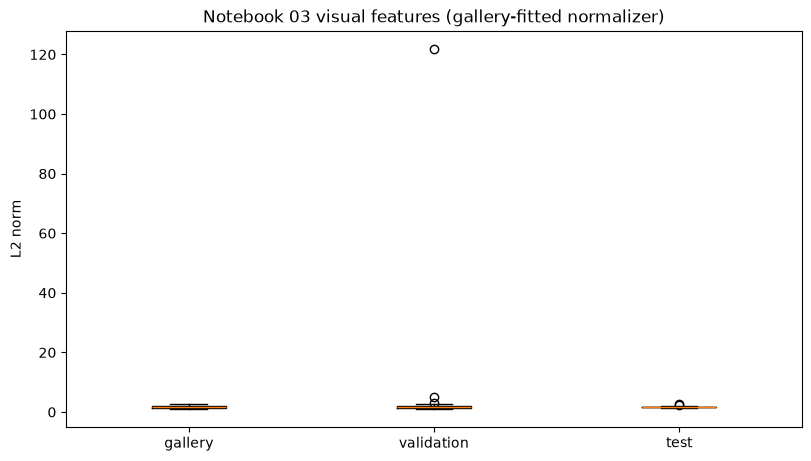

[SAVED] 205_gallery_fitted_visual_feature_norms.png


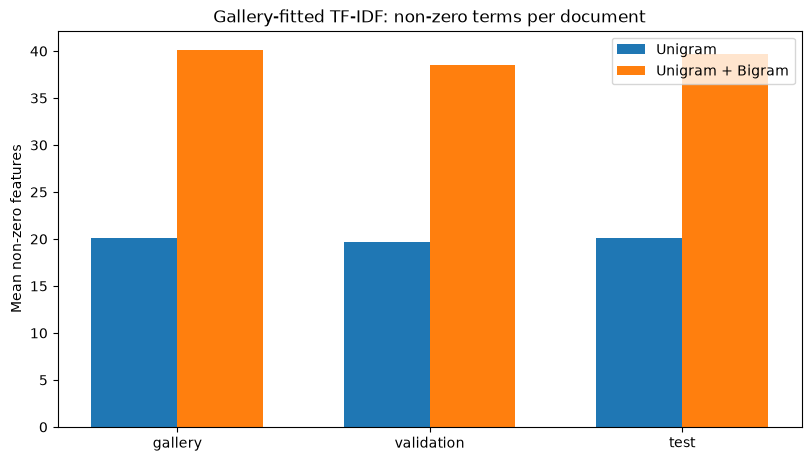

[SAVED] 206_gallery_fitted_tfidf_coverage.png
[SAVED] 631_visual_feature_summary.csv
[SAVED] 632_text_gallery_vocabularies.csv
[SAVED] 633_text_split_coverage.csv
[SAVED] 635_feature_fit_validation.csv
[SAVED] 637_query_visual_out_of_range_audit.csv
[SAVED] 636_feature_preparation_handoff.json

CELL 4B COMPLETED | feature fingerprint: 2339c38dc7dc7b51


In [5]:
# ============================================================
# CELL 4B - ORIGINAL FEATURE INTEGRATION: GALLERY-ONLY FITTING
# ============================================================
# Fits the Notebook 03 visual normalizer and both TF-IDF vectorizers on
# the GALLERY ONLY, then transforms validation/test without refitting.
# The resulting matrices are the ONLY feature matrices used by Cell 5+.
# A provenance token (hashes of every matrix) is created here and
# re-verified in Cell 5, so stale matrices from older code cannot be used.

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from scipy.sparse import save_npz, issparse
from joblib import dump

assert globals().get("EVAL06_FEATURE_SOURCES_VERIFIED") is True, "Jalankan Cell 4 terlebih dahulu."

EVAL06_FEATURE_PREPARATION_COMPLETED = False
eval06_fit_checks = []

print("NOTEBOOK 06 - CELL 4B: GALLERY-ONLY FEATURE FITTING")
print("=" * 75)

gallery_idx = EVAL06_SPLIT_INDICES["gallery"]
n_gallery = len(gallery_idx)

# ============================================================
# 1. VISUAL: Notebook 03 normalizer fitted on gallery
# ============================================================

EVAL06_VISUAL_NORMALIZER = eval06_fit_visual_normalizer(EVAL06_VISUAL_RAW_FEATURES[gallery_idx])
EVAL06_VISUAL_FEATURES_BY_SPLIT = {
    s: eval06_transform_visual(EVAL06_VISUAL_RAW_FEATURES[EVAL06_SPLIT_INDICES[s]], EVAL06_VISUAL_NORMALIZER)
    for s in EVAL06_SPLIT_NAMES}

gallery_raw = EVAL06_VISUAL_RAW_FEATURES[gallery_idx]
for group, p in EVAL06_VISUAL_NORMALIZER["groups"].items():
    eval06_check(eval06_fit_checks, "Visual fit", f"{group}: mean equals gallery mean",
                 np.allclose(p["mean"], gallery_raw[:, p["start"]:p["stop"]].mean(axis=0), atol=1e-12, rtol=0))
eval06_check(eval06_fit_checks, "Visual fit", "Normalizer fitted on exactly the gallery rows",
             EVAL06_VISUAL_NORMALIZER["n_reference_samples"] == n_gallery)
eval06_check(eval06_fit_checks, "Visual fit", "Gallery-fitted parameters differ from full-dataset fit (no leakage)",
             not np.allclose(EVAL06_VISUAL_NORMALIZER["groups"]["GLCM"]["mean"],
                             EVAL06_VISUAL_RAW_FEATURES[:, 64:136].mean(axis=0)))
eval06_check(eval06_fit_checks, "Visual fit", "Batch transform == per-sample transform (no query-dependent state)",
             np.allclose(eval06_transform_visual(EVAL06_VISUAL_RAW_FEATURES[EVAL06_SPLIT_INDICES["test"][:1]],
                                                 EVAL06_VISUAL_NORMALIZER),
                         EVAL06_VISUAL_FEATURES_BY_SPLIT["test"][:1], atol=0, rtol=0))
for s in EVAL06_SPLIT_NAMES:
    eval06_check(eval06_fit_checks, "Visual shape", f"{s}: ({len(EVAL06_SPLIT_INDICES[s])}, 143), finite",
                 EVAL06_VISUAL_FEATURES_BY_SPLIT[s].shape == (len(EVAL06_SPLIT_INDICES[s]), 143)
                 and np.isfinite(EVAL06_VISUAL_FEATURES_BY_SPLIT[s]).all())

# Query features far outside the gallery range (diagnostic only; the
# Notebook 03 method is NOT changed). With the HSV SD floor of 1e-3, a
# histogram bin that is ~0 for every gallery image produces a very large
# z-score for a query that has mass in that bin.
EVAL06_OOD_Z_THRESHOLD = 10.0
ood_rows = []
for s in ("validation", "test"):
    z = EVAL06_VISUAL_FEATURES_BY_SPLIT[s]
    for group, p in EVAL06_VISUAL_NORMALIZER["groups"].items():
        z_unweighted = z[:, p["start"]:p["stop"]] / p["weight"]
        for qi, fj in zip(*np.nonzero(np.abs(z_unweighted) > EVAL06_OOD_Z_THRESHOLD)):
            j = p["start"] + fj
            ood_rows.append({"split": s, "sample_id": EVAL06_SPLIT_SAMPLE_IDS[s][qi],
                             "class_label": EVAL06_SPLIT_LABELS[s][qi], "feature": EVAL06_VISUAL_FEATURE_NAMES[j],
                             "raw_value": float(EVAL06_VISUAL_RAW_FEATURES[EVAL06_SPLIT_INDICES[s][qi], j]),
                             "gallery_min": float(gallery_raw[:, j].min()), "gallery_max": float(gallery_raw[:, j].max()),
                             "gallery_std": float(gallery_raw[:, j].std()), "z_score": float(z_unweighted[qi, fj])})
EVAL06_VISUAL_OOD_DF = pd.DataFrame(ood_rows, columns=["split", "sample_id", "class_label", "feature", "raw_value",
                                                       "gallery_min", "gallery_max", "gallery_std", "z_score"])
eval06_check(eval06_fit_checks, "Visual diagnostic", f"No query feature with |z| > {EVAL06_OOD_Z_THRESHOLD:g}",
             EVAL06_VISUAL_OOD_DF.empty, detail=f"rows={len(EVAL06_VISUAL_OOD_DF)}, samples={EVAL06_VISUAL_OOD_DF['sample_id'].nunique()}",
             severity="REVIEW")

EVAL06_VISUAL_CONSTANT_GALLERY_FEATURES = int(sum(p["constant_mask"].sum() for p in EVAL06_VISUAL_NORMALIZER["groups"].values()))
EVAL06_VISUAL_FLOOR_APPLIED = int(EVAL06_VISUAL_NORMALIZER["groups"]["HSV"]["floor_mask"].sum())

# ============================================================
# 2. TEXT: TF-IDF fitted on gallery documents only
# ============================================================

EVAL06_FEATURE_TEXT_DOCUMENTS = {s: [EVAL06_TEXT_DOCUMENTS_ALL[i] for i in EVAL06_SPLIT_INDICES[s]]
                                 for s in EVAL06_SPLIT_NAMES}
EVAL06_TFIDF_VECTORIZERS = {}
EVAL06_TEXT_FEATURES_BY_CONFIG = {}

for config, spec in EVAL06_TEXT_CONFIGURATIONS.items():
    vectorizer = TfidfVectorizer(ngram_range=spec["ngram_range"], **EVAL06_TFIDF_PARAMS)
    matrices = {"gallery": vectorizer.fit_transform(EVAL06_FEATURE_TEXT_DOCUMENTS["gallery"]).tocsr()}
    for s in ("validation", "test"):
        matrices[s] = vectorizer.transform(EVAL06_FEATURE_TEXT_DOCUMENTS[s]).tocsr()
    EVAL06_TFIDF_VECTORIZERS[config] = vectorizer
    EVAL06_TEXT_FEATURES_BY_CONFIG[config] = matrices

    # Independent recomputation of the gallery IDF (smooth_idf formula).
    counter = CountVectorizer(ngram_range=spec["ngram_range"], lowercase=True,
                              token_pattern=EVAL06_TFIDF_PARAMS["token_pattern"])
    gallery_counts = counter.fit_transform(EVAL06_FEATURE_TEXT_DOCUMENTS["gallery"])
    df_counts = np.asarray((gallery_counts > 0).sum(axis=0)).ravel()
    expected_idf = np.log((1 + n_gallery) / (1 + df_counts)) + 1
    order = np.argsort(counter.get_feature_names_out())
    fitted_order = np.argsort(vectorizer.get_feature_names_out())
    eval06_check(eval06_fit_checks, "TF-IDF fit", f"{config}: vocabulary built from gallery only",
                 set(vectorizer.vocabulary_) == set(counter.vocabulary_),
                 detail=f"vocabulary={len(vectorizer.vocabulary_)}")
    eval06_check(eval06_fit_checks, "TF-IDF fit", f"{config}: IDF equals gallery document frequencies",
                 np.allclose(vectorizer.idf_[fitted_order], expected_idf[order], atol=1e-12, rtol=0))
    eval06_check(eval06_fit_checks, "TF-IDF fit", f"{config}: vocabulary differs from legacy full-data vectorizer",
                 len(vectorizer.vocabulary_) != legacy_vocab[config],
                 detail=f"gallery={len(vectorizer.vocabulary_)} vs full-data={legacy_vocab[config]}", severity="REVIEW")
    for s in EVAL06_SPLIT_NAMES:
        m = matrices[s]
        eval06_check(eval06_fit_checks, "TF-IDF shape", f"{config}/{s}: sparse ({m.shape[0]}, {len(vectorizer.vocabulary_)})",
                     issparse(m) and m.shape == (len(EVAL06_SPLIT_INDICES[s]), len(vectorizer.vocabulary_))
                     and np.isfinite(m.data).all())

# ============================================================
# 3. FEATURE PROVENANCE TOKEN
# ============================================================

def eval06_feature_matrix_hashes():
    hashes = {f"visual/{s}": eval06_sha256_array(EVAL06_VISUAL_FEATURES_BY_SPLIT[s]) for s in EVAL06_SPLIT_NAMES}
    for config, matrices in EVAL06_TEXT_FEATURES_BY_CONFIG.items():
        for s, m in matrices.items():
            m = m.tocsr()
            hashes[f"text/{config}/{s}"] = eval06_sha256_bytes(
                m.data.tobytes() + m.indices.tobytes() + m.indptr.tobytes() + str(m.shape).encode())
    return hashes


EVAL06_FEATURE_PROVENANCE = {
    "created_by": "Cell 4B",
    "visual_source": "Notebook 03 visual_features_raw.npy (manifest SHA-256 verified)",
    "visual_raw_sha256": EVAL06_SOURCE_FILE_HASHES["visual/visual_features_raw.npy"],
    "visual_normalizer": "Notebook 03 algorithm, fitted on gallery only",
    "text_source": "Notebook 02 cleaned_description",
    "tfidf_fit": "gallery only",
    "split_fingerprint": EVAL06_SPLIT_FINGERPRINT,
    "matrix_hashes": eval06_feature_matrix_hashes(),
}
EVAL06_FEATURE_FINGERPRINT = eval06_sha256_bytes(eval06_canonical_json(EVAL06_FEATURE_PROVENANCE).encode())
EVAL06_FEATURE_PROVENANCE["feature_fingerprint"] = EVAL06_FEATURE_FINGERPRINT
EVAL06_RUN_MANIFEST["stage_fingerprints"]["features"] = EVAL06_FEATURE_FINGERPRINT
eval06_update_registry(feature_fingerprint=EVAL06_FEATURE_FINGERPRINT)

# ============================================================
# 4. SAVE ARTIFACTS AND REPORTS
# ============================================================

np.save(EVAL06_ARTIFACTS_DIR / "visual_raw_143.npy", EVAL06_VISUAL_RAW_FEATURES, allow_pickle=False)
np.savez_compressed(EVAL06_ARTIFACTS_DIR / "visual_gallery_fitted_splits.npz", **EVAL06_VISUAL_FEATURES_BY_SPLIT)
dump(EVAL06_VISUAL_NORMALIZER, EVAL06_ARTIFACTS_DIR / "visual_gallery_fitted_normalizer.joblib")
for config, spec in EVAL06_TEXT_CONFIGURATIONS.items():
    dump(EVAL06_TFIDF_VECTORIZERS[config], EVAL06_ARTIFACTS_DIR / f"tfidf_{spec['slug']}_gallery_fitted.joblib")
    for s in EVAL06_SPLIT_NAMES:
        save_npz(EVAL06_ARTIFACTS_DIR / f"tfidf_{spec['slug']}_{s}.npz", EVAL06_TEXT_FEATURES_BY_CONFIG[config][s])
for path in EVAL06_ARTIFACTS_DIR.iterdir():
    eval06_log_output(path, "4B", "artifact")
eval06_save_json(EVAL06_FEATURE_PROVENANCE, "feature_provenance.json", "4B", directory=EVAL06_ARTIFACTS_DIR)

EVAL06_VISUAL_FEATURE_SUMMARY_DF = pd.DataFrame([{
    "split": s, "n_samples": len(EVAL06_SPLIT_INDICES[s]), "visual_dim": 143,
    "mean_l2_norm": float(np.linalg.norm(v, axis=1).mean()),
    "median_l2_norm": float(np.median(np.linalg.norm(v, axis=1))),
    "max_abs_value": float(np.abs(v).max()),
    "constant_gallery_features": EVAL06_VISUAL_CONSTANT_GALLERY_FEATURES,
    "hsv_floor_applied_features": EVAL06_VISUAL_FLOOR_APPLIED, "fitted_on": "gallery_only"}
    for s, v in EVAL06_VISUAL_FEATURES_BY_SPLIT.items()])
EVAL06_TEXT_VOCABULARY_SUMMARY_DF = pd.DataFrame([{
    "text_configuration": c, "ngram_range": str(v.ngram_range), "gallery_fit_documents": n_gallery,
    "vocabulary_size_gallery_fit": len(v.vocabulary_), "legacy_full_data_vocabulary": legacy_vocab[c],
    "fitted_on": "gallery_only"} for c, v in EVAL06_TFIDF_VECTORIZERS.items()])
EVAL06_TEXT_COVERAGE_DF = pd.DataFrame([{
    "text_configuration": c, "split": s, "sample_count": m.shape[0], "feature_count": m.shape[1],
    "zero_vector_count": int((np.diff(m.indptr) == 0).sum()),
    "zero_vector_percent": float((np.diff(m.indptr) == 0).mean() * 100),
    "mean_nonzero_features_per_sample": float(np.diff(m.indptr).mean())}
    for c, ms in EVAL06_TEXT_FEATURES_BY_CONFIG.items() for s, m in ms.items()])
EVAL06_FEATURE_FIT_VALIDATION_DF = eval06_checks_frame(eval06_fit_checks)

print("\n1. VISUAL (Notebook 03 normalizer, gallery-fitted)")
print("-" * 75)
display(EVAL06_VISUAL_FEATURE_SUMMARY_DF)
print("\n2. TEXT (TF-IDF, gallery-fitted)")
print("-" * 75)
display(EVAL06_TEXT_VOCABULARY_SUMMARY_DF)
display(EVAL06_TEXT_COVERAGE_DF)
display(EVAL06_FEATURE_FIT_VALIDATION_DF)
if not EVAL06_VISUAL_OOD_DF.empty:
    print("[REVIEW] Query features far outside the gallery range (Notebook 03 method unchanged):")
    display(EVAL06_VISUAL_OOD_DF)

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
eval06_boxplot(ax, [np.linalg.norm(EVAL06_VISUAL_FEATURES_BY_SPLIT[s], axis=1) for s in EVAL06_SPLIT_NAMES],
               EVAL06_SPLIT_NAMES)
ax.set(title="Notebook 03 visual features (gallery-fitted normalizer)", ylabel="L2 norm")
eval06_save_figure(fig, "205_gallery_fitted_visual_feature_norms.png", "4B")

fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
coverage = EVAL06_TEXT_COVERAGE_DF.set_index(["text_configuration", "split"])
for k, config in enumerate(EVAL06_TEXT_CONFIGURATIONS):
    ax.bar(np.arange(3) + (k - 0.5) * 0.34,
           [coverage.loc[(config, s), "mean_nonzero_features_per_sample"] for s in EVAL06_SPLIT_NAMES],
           width=0.34, label=config)
ax.set_xticks(np.arange(3), EVAL06_SPLIT_NAMES)
ax.set(title="Gallery-fitted TF-IDF: non-zero terms per document", ylabel="Mean non-zero features")
ax.legend()
eval06_save_figure(fig, "206_gallery_fitted_tfidf_coverage.png", "4B")

eval06_save_csv(EVAL06_VISUAL_FEATURE_SUMMARY_DF, "631_visual_feature_summary.csv", "4B")
eval06_save_csv(EVAL06_TEXT_VOCABULARY_SUMMARY_DF, "632_text_gallery_vocabularies.csv", "4B")
eval06_save_csv(EVAL06_TEXT_COVERAGE_DF, "633_text_split_coverage.csv", "4B")
eval06_save_csv(EVAL06_FEATURE_FIT_VALIDATION_DF, "635_feature_fit_validation.csv", "4B")
eval06_save_csv(EVAL06_VISUAL_OOD_DF, "637_query_visual_out_of_range_audit.csv", "4B")
eval06_save_json({k: v for k, v in EVAL06_FEATURE_PROVENANCE.items()},
                 "636_feature_preparation_handoff.json", "4B")

eval06_require(EVAL06_FEATURE_FIT_VALIDATION_DF, "Cell 4B")
EVAL06_FEATURE_PREPARATION_COMPLETED = True
print("\nCELL 4B COMPLETED | feature fingerprint:", EVAL06_FEATURE_FINGERPRINT[:16])

## Cell 5 — Similarity Calculation

NOTEBOOK 06 - CELL 5: SIMILARITY CALCULATION
Visual distance scale (gallery median): 2.262902


,partition,modality,configuration,matrix_shape,fitted_on,score_mean,score_std
0,gallery,Visual,HSV64_GLCM72_Hu7,"(62, 62)",gallery_only,0.510639,0.089800
1,gallery,Text,Unigram,"(62, 62)",gallery_only,0.364218,0.191265
2,gallery,Text,Unigram + Bigram,"(62, 62)",gallery_only,0.254036,0.184662
3,validation,Visual,HSV64_GLCM72_Hu7,"(21, 62)",gallery_only,0.469031,0.127241
4,validation,Text,Unigram,"(21, 62)",gallery_only,0.355156,0.167194
5,validation,Text,Unigram + Bigram,"(21, 62)",gallery_only,0.248970,0.156909
6,test,Visual,HSV64_GLCM72_Hu7,"(21, 62)",gallery_only,NaN,NaN
7,test,Text,Unigram,"(21, 62)",gallery_only,NaN,NaN
8,test,Text,Unigram + Bigram,"(21, 62)",gallery_only,NaN,NaN


[INFO] Test similarity statistics are sealed (not displayed, not used for selection).


,category,validation_check,passed,severity_if_failed,detail
0,Provenance,Feature matrices identical to Cell 4B provenan...,True,BLOCK,
1,Provenance,Provenance split fingerprint equals Cell 3 split,True,BLOCK,
2,Provenance,Visual source is Notebook 03 raw file,True,BLOCK,
3,Alignment,Validation/test queries never appear in gallery,True,BLOCK,
4,Alignment,Validation and test query sets disjoint,True,BLOCK,
5,Visual,"gallery: shape (62, 62), finite, in (0, 1]",True,BLOCK,
6,Cross-check,gallery: direct Euclidean spot-check,True,BLOCK,
7,Visual,"validation: shape (21, 62), finite, in (0, 1]",True,BLOCK,
8,Cross-check,validation: direct Euclidean spot-check,True,BLOCK,
9,Visual,"test: shape (21, 62), finite, in (0, 1]",True,BLOCK,


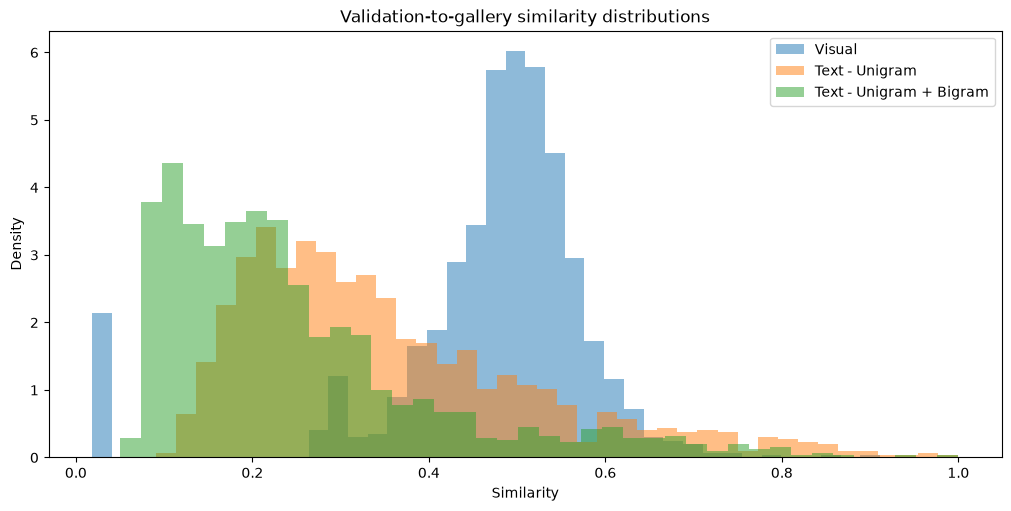

[SAVED] 207_validation_gallery_similarity_distributions.png


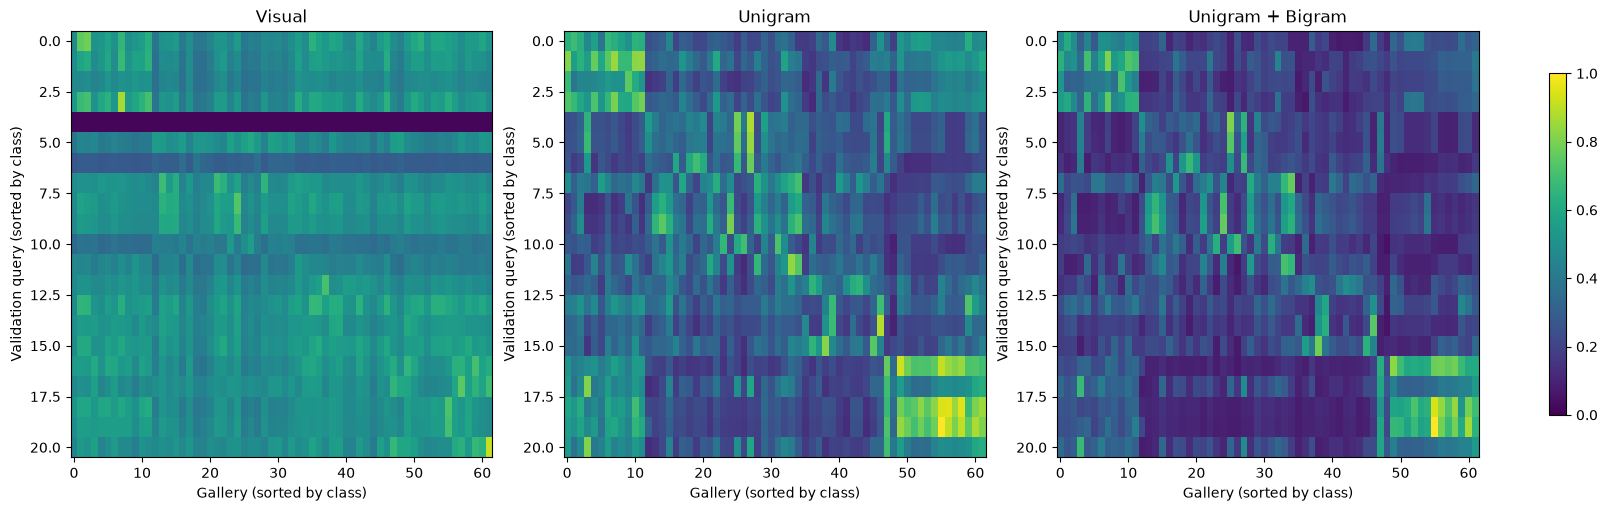

[SAVED] 208_validation_gallery_similarity_heatmaps.png
[SAVED] 639_similarity_matrix_inventory.csv
[SAVED] 640_visual_similarity_calibration.csv
[SAVED] 641_text_zero_vector_audit.csv
[SAVED] 642_similarity_validation.csv
[SAVED] 645_similarity_handoff.json

CELL 5 COMPLETED


In [6]:
# ============================================================
# CELL 5 - LEAKAGE-SAFE SIMILARITY CALCULATION
# ============================================================
#   Visual : S = 1 / (1 + d / scale),  d = Euclidean distance,
#            scale = median non-zero gallery-gallery distance (gallery only)
#   Text   : S = cosine(TF-IDF query, TF-IDF gallery), clipped to [0, 1]
# Queries (validation/test) are compared with the gallery only.
# Test matrices are computed here but sealed: no statistics are displayed.

from scipy.spatial.distance import cdist
from sklearn.metrics.pairwise import cosine_similarity

assert globals().get("EVAL06_FEATURE_PREPARATION_COMPLETED") is True, "Jalankan Cell 4B terlebih dahulu."

EVAL06_SIMILARITY_CALCULATION_COMPLETED = False
eval06_sim_checks = []

print("NOTEBOOK 06 - CELL 5: SIMILARITY CALCULATION")
print("=" * 75)

# ============================================================
# 1. VERIFY THAT CELL 4B MATRICES ARE THE ONES IN MEMORY
# ============================================================

current_hashes = eval06_feature_matrix_hashes()
eval06_check(eval06_sim_checks, "Provenance", "Feature matrices identical to Cell 4B provenance token",
             current_hashes == EVAL06_FEATURE_PROVENANCE["matrix_hashes"])
eval06_check(eval06_sim_checks, "Provenance", "Provenance split fingerprint equals Cell 3 split",
             EVAL06_FEATURE_PROVENANCE["split_fingerprint"] == EVAL06_SPLIT_FINGERPRINT)
eval06_check(eval06_sim_checks, "Provenance", "Visual source is Notebook 03 raw file",
             EVAL06_FEATURE_PROVENANCE["visual_raw_sha256"] == EVAL06_SOURCE_FILE_HASHES["visual/visual_features_raw.npy"])

EVAL06_GALLERY_IDS = list(EVAL06_SPLIT_SAMPLE_IDS["gallery"])
EVAL06_GALLERY_LABELS = EVAL06_SPLIT_LABELS["gallery"]
EVAL06_QUERY_IDS = {s: list(EVAL06_SPLIT_SAMPLE_IDS[s]) for s in EVAL06_SPLIT_NAMES}
n_gallery = len(EVAL06_GALLERY_IDS)
gallery_visual = EVAL06_VISUAL_FEATURES_BY_SPLIT["gallery"]

eval06_check(eval06_sim_checks, "Alignment", "Validation/test queries never appear in gallery",
             not (set(EVAL06_QUERY_IDS["validation"]) | set(EVAL06_QUERY_IDS["test"])) & set(EVAL06_GALLERY_IDS))
eval06_check(eval06_sim_checks, "Alignment", "Validation and test query sets disjoint",
             not set(EVAL06_QUERY_IDS["validation"]) & set(EVAL06_QUERY_IDS["test"]))

# ============================================================
# 2. VISUAL DISTANCE CALIBRATION (gallery only)
# ============================================================

gallery_distance = cdist(gallery_visual, gallery_visual, metric="euclidean")
upper = gallery_distance[np.triu_indices(n_gallery, k=1)]
EVAL06_VISUAL_DISTANCE_SCALE = float(np.median(upper[upper > 0]))
EVAL06_VISUAL_DISTANCE_SCALE_SOURCE = "median_nonzero_gallery_gallery_euclidean_distance"

EVAL06_VISUAL_DISTANCE_BY_SPLIT = {}
EVAL06_VISUAL_SIMILARITY_BY_SPLIT = {}
for s in EVAL06_SPLIT_NAMES:
    distance = cdist(EVAL06_VISUAL_FEATURES_BY_SPLIT[s], gallery_visual, metric="euclidean")
    similarity = 1.0 / (1.0 + distance / EVAL06_VISUAL_DISTANCE_SCALE)
    EVAL06_VISUAL_DISTANCE_BY_SPLIT[s] = distance
    EVAL06_VISUAL_SIMILARITY_BY_SPLIT[s] = similarity
    eval06_check(eval06_sim_checks, "Visual", f"{s}: shape ({len(EVAL06_QUERY_IDS[s])}, {n_gallery}), finite, in (0, 1]",
                 similarity.shape == (len(EVAL06_QUERY_IDS[s]), n_gallery) and np.isfinite(similarity).all()
                 and similarity.min() > 0 and similarity.max() <= 1 + 1e-12)
    probe_q, probe_g = 0, n_gallery - 1
    direct = float(np.sqrt(((EVAL06_VISUAL_FEATURES_BY_SPLIT[s][probe_q] - gallery_visual[probe_g]) ** 2).sum()))
    eval06_check(eval06_sim_checks, "Cross-check", f"{s}: direct Euclidean spot-check",
                 abs(direct - distance[probe_q, probe_g]) < 1e-10)
eval06_check(eval06_sim_checks, "Visual", "Gallery self-similarity matrix symmetric with diagonal 1",
             np.allclose(EVAL06_VISUAL_SIMILARITY_BY_SPLIT["gallery"], EVAL06_VISUAL_SIMILARITY_BY_SPLIT["gallery"].T)
             and np.allclose(np.diag(EVAL06_VISUAL_SIMILARITY_BY_SPLIT["gallery"]), 1.0))

# ============================================================
# 3. TEXT COSINE SIMILARITY
# ============================================================

EVAL06_TEXT_SIMILARITY_BY_CONFIG = {}
zero_rows = []
for config in EVAL06_TEXT_CONFIGURATIONS:
    EVAL06_TEXT_SIMILARITY_BY_CONFIG[config] = {}
    gallery_tfidf = EVAL06_TEXT_FEATURES_BY_CONFIG[config]["gallery"]
    for s in EVAL06_SPLIT_NAMES:
        query_tfidf = EVAL06_TEXT_FEATURES_BY_CONFIG[config][s]
        raw = cosine_similarity(query_tfidf, gallery_tfidf, dense_output=True)
        eval06_check(eval06_sim_checks, "Text", f"{config}/{s}: raw cosine within [-1e-12, 1+1e-12]",
                     np.isfinite(raw).all() and raw.min() >= -1e-12 and raw.max() <= 1 + 1e-12)
        scores = np.clip(raw, 0.0, 1.0)
        EVAL06_TEXT_SIMILARITY_BY_CONFIG[config][s] = scores
        zero = np.diff(query_tfidf.indptr) == 0
        zero_rows.append({"text_configuration": config, "split": s, "zero_tfidf_queries": int(zero.sum()),
                          "zero_rows_have_zero_scores": bool(np.all(scores[zero] == 0)) if zero.any() else True})
    g = EVAL06_TEXT_SIMILARITY_BY_CONFIG[config]["gallery"]
    eval06_check(eval06_sim_checks, "Text", f"{config}: gallery cosine symmetric, diagonal 1",
                 np.allclose(g, g.T) and np.allclose(np.diag(g), 1.0))
EVAL06_TEXT_ZERO_VECTOR_DF = pd.DataFrame(zero_rows)

# ============================================================
# 4. INVENTORY (test statistics sealed)
# ============================================================

inventory = []
for s in EVAL06_SPLIT_NAMES:
    matrices = [("Visual", "HSV64_GLCM72_Hu7", EVAL06_VISUAL_SIMILARITY_BY_SPLIT[s])] + \
               [("Text", c, EVAL06_TEXT_SIMILARITY_BY_CONFIG[c][s]) for c in EVAL06_TEXT_CONFIGURATIONS]
    for modality, config, m in matrices:
        inventory.append({"partition": s, "modality": modality, "configuration": config,
                          "matrix_shape": str(m.shape), "fitted_on": "gallery_only",
                          "score_mean": float(m.mean()) if s != "test" else np.nan,
                          "score_std": float(m.std()) if s != "test" else np.nan})
EVAL06_SIMILARITY_INVENTORY_DF = pd.DataFrame(inventory)
EVAL06_SIMILARITY_CALIBRATION_DF = pd.DataFrame([{
    "method": "Euclidean -> 1 / (1 + d / scale)", "visual_distance_scale": EVAL06_VISUAL_DISTANCE_SCALE,
    "scale_source": EVAL06_VISUAL_DISTANCE_SCALE_SOURCE, "fitted_partition": "gallery_only",
    "gallery_size": n_gallery, "validation_used": False, "test_used": False}])
EVAL06_SIMILARITY_VALIDATION_DF = eval06_checks_frame(eval06_sim_checks)

print("Visual distance scale (gallery median):", round(EVAL06_VISUAL_DISTANCE_SCALE, 6))
display(EVAL06_SIMILARITY_INVENTORY_DF)
print("[INFO] Test similarity statistics are sealed (not displayed, not used for selection).")
display(EVAL06_SIMILARITY_VALIDATION_DF)

np.savez_compressed(EVAL06_ARTIFACTS_DIR / "similarity_matrices.npz",
                    **{f"visual_distance_{s}": EVAL06_VISUAL_DISTANCE_BY_SPLIT[s] for s in EVAL06_SPLIT_NAMES},
                    **{f"visual_similarity_{s}": EVAL06_VISUAL_SIMILARITY_BY_SPLIT[s] for s in EVAL06_SPLIT_NAMES},
                    **{f"text_cosine_{EVAL06_TEXT_CONFIGURATIONS[c]['slug']}_{s}": EVAL06_TEXT_SIMILARITY_BY_CONFIG[c][s]
                       for c in EVAL06_TEXT_CONFIGURATIONS for s in EVAL06_SPLIT_NAMES})
eval06_log_output(EVAL06_ARTIFACTS_DIR / "similarity_matrices.npz", 5, "artifact")

# ============================================================
# 5. FIGURES (gallery and validation only)
# ============================================================

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
for label, m in [("Visual", EVAL06_VISUAL_SIMILARITY_BY_SPLIT["validation"])] + \
        [(f"Text - {c}", EVAL06_TEXT_SIMILARITY_BY_CONFIG[c]["validation"]) for c in EVAL06_TEXT_CONFIGURATIONS]:
    ax.hist(m.ravel(), bins=40, alpha=0.5, label=label, density=True)
ax.set(title="Validation-to-gallery similarity distributions", xlabel="Similarity", ylabel="Density")
ax.legend()
eval06_save_figure(fig, "207_validation_gallery_similarity_distributions.png", 5)

order = np.argsort(EVAL06_GALLERY_LABELS, kind="stable")
qorder = np.argsort(EVAL06_SPLIT_LABELS["validation"], kind="stable")
panels = [("Visual", EVAL06_VISUAL_SIMILARITY_BY_SPLIT["validation"])] + \
         [(c, EVAL06_TEXT_SIMILARITY_BY_CONFIG[c]["validation"]) for c in EVAL06_TEXT_CONFIGURATIONS]
fig, axes = plt.subplots(1, 3, figsize=(16, 5), constrained_layout=True)
for ax, (title, m) in zip(axes, panels):
    im = ax.imshow(m[qorder][:, order], aspect="auto", cmap="viridis", vmin=0, vmax=1)
    ax.set(title=title, xlabel="Gallery (sorted by class)", ylabel="Validation query (sorted by class)")
fig.colorbar(im, ax=axes, shrink=0.8)
eval06_save_figure(fig, "208_validation_gallery_similarity_heatmaps.png", 5)

eval06_save_csv(EVAL06_SIMILARITY_INVENTORY_DF, "639_similarity_matrix_inventory.csv", 5)
eval06_save_csv(EVAL06_SIMILARITY_CALIBRATION_DF, "640_visual_similarity_calibration.csv", 5)
eval06_save_csv(EVAL06_TEXT_ZERO_VECTOR_DF, "641_text_zero_vector_audit.csv", 5)
eval06_save_csv(EVAL06_SIMILARITY_VALIDATION_DF, "642_similarity_validation.csv", 5)
eval06_save_json({"cell": 5, "visual_distance_scale": EVAL06_VISUAL_DISTANCE_SCALE,
                  "visual_formula": EVAL06_VISUAL_SIMILARITY_FORMULA, "text_formula": EVAL06_TEXT_SIMILARITY_FORMULA,
                  "feature_fingerprint": EVAL06_FEATURE_FINGERPRINT, "test_statistics_sealed": True},
                 "645_similarity_handoff.json", 5)

eval06_require(EVAL06_SIMILARITY_VALIDATION_DF, "Cell 5")
EVAL06_SIMILARITY_CALCULATION_COMPLETED = True
print("\nCELL 5 COMPLETED")

## Cell 6 — Validation Retrieval Ranking

NOTEBOOK 06 - CELL 6: VALIDATION RETRIEVAL RANKING
Validation queries: 21 | gallery: 62 | methods: 5
Full ranking rows: 6510


,category,validation_check,passed,severity_if_failed,detail
0,Ranking,Five retrieval configurations ranked,True,BLOCK,
1,Ranking,Every gallery candidate ranked exactly once pe...,True,BLOCK,
2,Ranking,Ranks are 1..N per query,True,BLOCK,
3,Ranking,Scores non-increasing along rank,True,BLOCK,
4,Ranking,No self-matches / no query in gallery,True,BLOCK,
5,Ranking,No test sample used,True,BLOCK,
6,Ranking,"Scores within [0, 1]",True,BLOCK,
7,Formula,Fusion = 0.5*visual + 0.5*text verified,True,BLOCK,
8,Determinism,Re-ranking reproduces identical order,True,BLOCK,


,query_partition,method,text_configuration,alpha,query_sample_id,query_class,rank,gallery_sample_id,gallery_class,similarity_score,relevant
0,validation,Visual Only,n/a,1.0,leaf_8473270c3702f48b,Mangkok,1,leaf_de9e3e4ed5d89dfc,Mangkok,0.781445,True
1,validation,Visual Only,n/a,1.0,leaf_8473270c3702f48b,Mangkok,2,leaf_b0c5f55e42499cae,Mangkok,0.752342,True
2,validation,Visual Only,n/a,1.0,leaf_8473270c3702f48b,Mangkok,3,leaf_8f09fd62c7391c0d,Mangkok,0.659579,True
3,validation,Visual Only,n/a,1.0,leaf_8473270c3702f48b,Mangkok,4,leaf_1d4f34320b1b8b8d,Sirih,0.639540,False
4,validation,Visual Only,n/a,1.0,leaf_8473270c3702f48b,Mangkok,5,leaf_43ae297ca838aebb,Tapak Kuda,0.634511,False


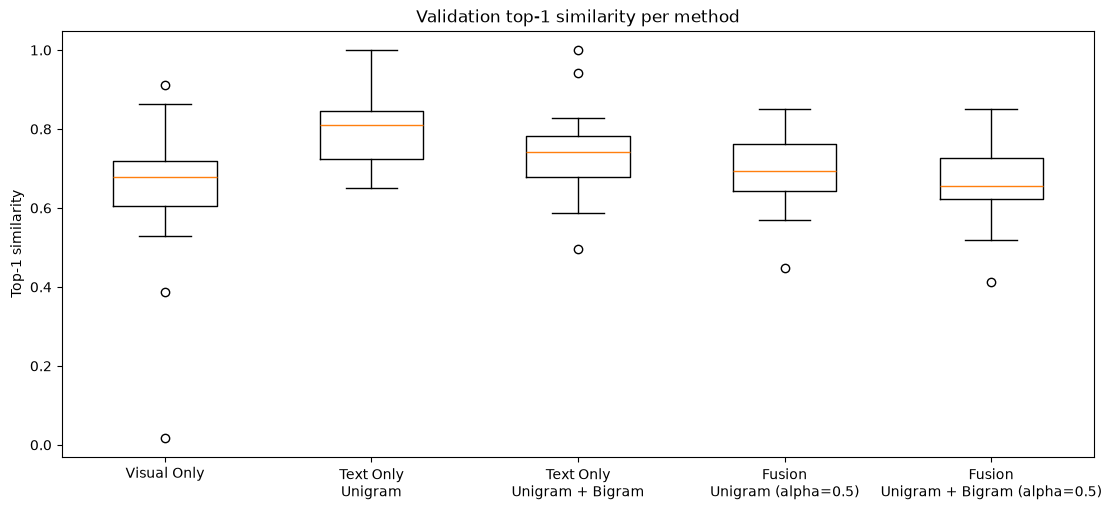

[SAVED] 209_validation_top1_similarity_distribution.png


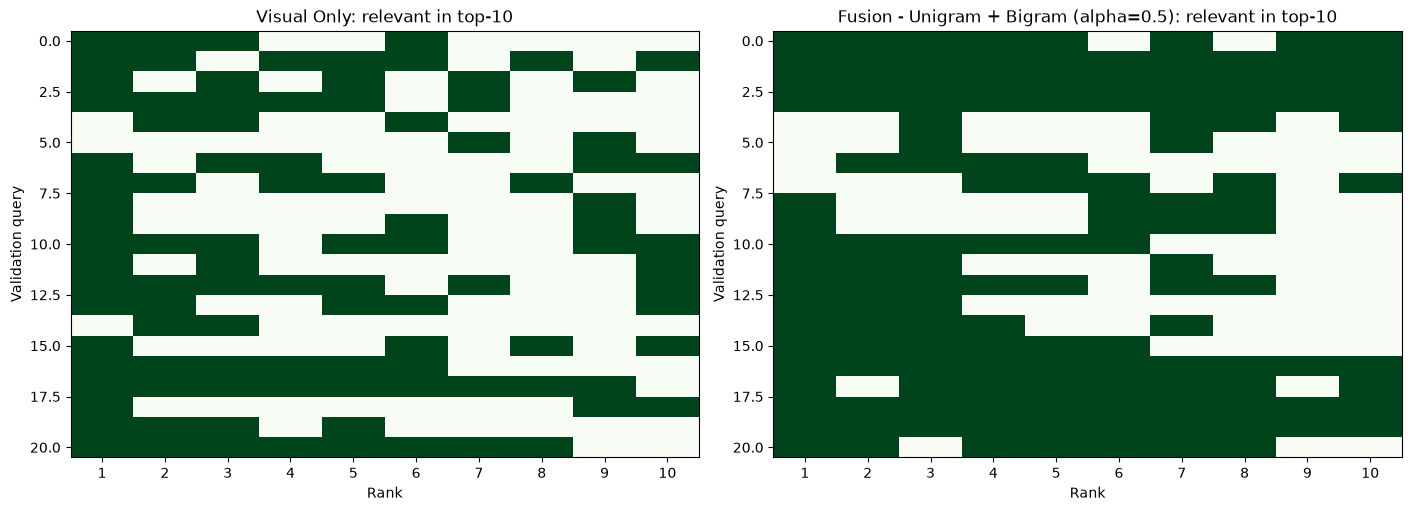

[SAVED] 210_validation_top10_relevance_heatmap.png
[SAVED] 646_validation_full_rankings.csv
[SAVED] 647_validation_topk_rankings.csv
[SAVED] 648_validation_query_ranking_summary.csv
[SAVED] 649_validation_method_inventory.csv
[SAVED] 650_validation_ranking_checks.csv
[SAVED] 651_validation_score_tie_audit.csv

CELL 6 COMPLETED | alpha = 0.5 is provisional; no metric computed yet.


In [7]:
# ============================================================
# CELL 6 - VALIDATION RETRIEVAL RANKING
# ============================================================
# Five configurations at the provisional default alpha = 0.5:
#   Visual Only, Text Only (Unigram / Unigram + Bigram),
#   Weighted Fusion (Unigram / Unigram + Bigram, alpha = 0.5).
# Ranking order: similarity descending, then gallery sample_id ascending.

assert globals().get("EVAL06_SIMILARITY_CALCULATION_COMPLETED") is True, "Jalankan Cell 5 terlebih dahulu."

EVAL06_VALIDATION_RANKING_COMPLETED = False
eval06_rank_checks = []

print("NOTEBOOK 06 - CELL 6: VALIDATION RETRIEVAL RANKING")
print("=" * 75)

EVAL06_GALLERY_IDS_ARRAY = np.asarray(EVAL06_GALLERY_IDS, dtype=str)


def eval06_fused_scores(split, text_config, alpha):
    """S_fusion = alpha * S_visual + (1 - alpha) * S_text (query x gallery)."""
    alpha = float(alpha)
    if not 0.0 <= alpha <= 1.0:
        raise ValueError("alpha must be in [0, 1]")
    visual = EVAL06_VISUAL_SIMILARITY_BY_SPLIT[split]
    text = EVAL06_TEXT_SIMILARITY_BY_CONFIG[text_config][split]
    return alpha * visual + (1.0 - alpha) * text


def eval06_rank_order(score_row):
    """Gallery column indices sorted by score desc, then sample_id asc."""
    return np.lexsort((EVAL06_GALLERY_IDS_ARRAY, -np.asarray(score_row, dtype=np.float64)))


def eval06_rank_matrix(scores):
    return np.vstack([eval06_rank_order(row) for row in scores])


def eval06_rankings_frame(split, method, scores, text_config, alpha, top_n=None, visual=None, text=None):
    query_ids = EVAL06_QUERY_IDS[split]
    query_labels = EVAL06_SPLIT_LABELS[split]
    orders = eval06_rank_matrix(scores)
    n = orders.shape[1] if top_n is None else min(top_n, orders.shape[1])
    rows = []
    for qi, qid in enumerate(query_ids):
        for rank, gi in enumerate(orders[qi, :n], start=1):
            row = {"query_partition": split, "method": method, "text_configuration": text_config,
                   "alpha": float(alpha), "query_sample_id": qid, "query_class": query_labels[qi],
                   "rank": rank, "gallery_sample_id": EVAL06_GALLERY_IDS_ARRAY[gi],
                   "gallery_class": EVAL06_GALLERY_LABELS[gi],
                   "similarity_score": float(scores[qi, gi]),
                   "relevant": bool(EVAL06_GALLERY_LABELS[gi] == query_labels[qi])}
            if visual is not None:
                row["visual_similarity"] = float(visual[qi, gi])
                row["text_similarity"] = float(text[qi, gi])
            rows.append(row)
    return pd.DataFrame(rows)


EVAL06_BASELINE_TEXT_CONFIG = "Unigram + Bigram"   # used only to label the Visual Only row
EVAL06_VALIDATION_METHODS = [
    ("Visual Only", "Unigram", 1.0),
    ("Text Only - Unigram", "Unigram", 0.0),
    ("Text Only - Unigram + Bigram", "Unigram + Bigram", 0.0),
    (f"Fusion - Unigram (alpha={EVAL06_DEFAULT_ALPHA})", "Unigram", EVAL06_DEFAULT_ALPHA),
    (f"Fusion - Unigram + Bigram (alpha={EVAL06_DEFAULT_ALPHA})", "Unigram + Bigram", EVAL06_DEFAULT_ALPHA),
]

frames = []
tie_rows = []
EVAL06_VALIDATION_SCORES = {}
for method, config, alpha in EVAL06_VALIDATION_METHODS:
    scores = eval06_fused_scores("validation", config, alpha)
    EVAL06_VALIDATION_SCORES[method] = scores
    frames.append(eval06_rankings_frame("validation", method, scores, config if 0 < alpha < 1 or alpha == 0 else "n/a", alpha))
    for qi, qid in enumerate(EVAL06_QUERY_IDS["validation"]):
        top = np.sort(scores[qi])[::-1][:10]
        tie_rows.append({"method": method, "query_sample_id": qid,
                         "tied_scores_in_top10": int(len(top) - len(np.unique(np.round(top, 12))))})
EVAL06_VALIDATION_RANKINGS_DF = pd.concat(frames, ignore_index=True)
EVAL06_VALIDATION_TOPK_DF = EVAL06_VALIDATION_RANKINGS_DF.loc[EVAL06_VALIDATION_RANKINGS_DF["rank"] <= max(EVAL06_TOP_K_VALUES)]
EVAL06_VALIDATION_TIE_AUDIT_DF = pd.DataFrame(tie_rows)

summary = (EVAL06_VALIDATION_RANKINGS_DF.loc[EVAL06_VALIDATION_RANKINGS_DF["rank"] == 1]
           [["method", "query_sample_id", "query_class", "gallery_sample_id", "gallery_class", "similarity_score", "relevant"]]
           .rename(columns={"gallery_sample_id": "top1_gallery_id", "gallery_class": "top1_class",
                            "similarity_score": "top1_score", "relevant": "top1_correct"}))
EVAL06_VALIDATION_QUERY_SUMMARY_DF = summary.reset_index(drop=True)

n_q, n_g = len(EVAL06_QUERY_IDS["validation"]), n_gallery
grouped = EVAL06_VALIDATION_RANKINGS_DF.groupby(["method", "query_sample_id"])
eval06_check(eval06_rank_checks, "Ranking", "Five retrieval configurations ranked",
             EVAL06_VALIDATION_RANKINGS_DF["method"].nunique() == 5)
eval06_check(eval06_rank_checks, "Ranking", "Every gallery candidate ranked exactly once per query (no duplicates)",
             len(EVAL06_VALIDATION_RANKINGS_DF) == 5 * n_q * n_g
             and grouped["gallery_sample_id"].nunique().eq(n_g).all())
eval06_check(eval06_rank_checks, "Ranking", "Ranks are 1..N per query", grouped["rank"].apply(
    lambda r: np.array_equal(np.sort(r.to_numpy()), np.arange(1, n_g + 1))).all())
eval06_check(eval06_rank_checks, "Ranking", "Scores non-increasing along rank",
             grouped["similarity_score"].apply(lambda v: bool(np.all(np.diff(v.to_numpy()) <= 1e-15))).all())
eval06_check(eval06_rank_checks, "Ranking", "No self-matches / no query in gallery",
             not EVAL06_VALIDATION_RANKINGS_DF["query_sample_id"].isin(EVAL06_GALLERY_IDS).any())
eval06_check(eval06_rank_checks, "Ranking", "No test sample used", not (
    set(EVAL06_VALIDATION_RANKINGS_DF["query_sample_id"]) | set(EVAL06_VALIDATION_RANKINGS_DF["gallery_sample_id"]))
    & set(EVAL06_QUERY_IDS["test"]))
eval06_check(eval06_rank_checks, "Ranking", "Scores within [0, 1]",
             EVAL06_VALIDATION_RANKINGS_DF["similarity_score"].between(0, 1 + 1e-12).all())
fusion_check = eval06_fused_scores("validation", "Unigram + Bigram", 0.5)
eval06_check(eval06_rank_checks, "Formula", "Fusion = 0.5*visual + 0.5*text verified",
             np.allclose(fusion_check, 0.5 * EVAL06_VISUAL_SIMILARITY_BY_SPLIT["validation"]
                         + 0.5 * EVAL06_TEXT_SIMILARITY_BY_CONFIG["Unigram + Bigram"]["validation"]))
eval06_check(eval06_rank_checks, "Determinism", "Re-ranking reproduces identical order",
             np.array_equal(eval06_rank_matrix(fusion_check), eval06_rank_matrix(fusion_check.copy())))
EVAL06_VALIDATION_RANKING_CHECKS_DF = eval06_checks_frame(eval06_rank_checks)

print("Validation queries:", n_q, "| gallery:", n_g, "| methods:", 5)
print("Full ranking rows:", len(EVAL06_VALIDATION_RANKINGS_DF))
display(EVAL06_VALIDATION_RANKING_CHECKS_DF)
display(EVAL06_VALIDATION_TOPK_DF.query("method == 'Visual Only' and rank <= 5").head(5))

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
eval06_boxplot(ax, [EVAL06_VALIDATION_QUERY_SUMMARY_DF.loc[EVAL06_VALIDATION_QUERY_SUMMARY_DF["method"] == m, "top1_score"]
                    for m, _, _ in EVAL06_VALIDATION_METHODS],
               [m.replace(" - ", "\n") for m, _, _ in EVAL06_VALIDATION_METHODS])
ax.set(title="Validation top-1 similarity per method", ylabel="Top-1 similarity")
eval06_save_figure(fig, "209_validation_top1_similarity_distribution.png", 6)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for ax, method in zip(axes, ["Visual Only", f"Fusion - Unigram + Bigram (alpha={EVAL06_DEFAULT_ALPHA})"]):
    top = EVAL06_VALIDATION_TOPK_DF.loc[EVAL06_VALIDATION_TOPK_DF["method"] == method]
    matrix = top.pivot(index="query_sample_id", columns="rank", values="relevant").loc[EVAL06_QUERY_IDS["validation"]]
    ax.imshow(matrix.to_numpy(dtype=float), aspect="auto", cmap="Greens", vmin=0, vmax=1)
    ax.set(title=f"{method}: relevant in top-10", xlabel="Rank", ylabel="Validation query")
    ax.set_xticks(range(10), range(1, 11))
eval06_save_figure(fig, "210_validation_top10_relevance_heatmap.png", 6)

eval06_save_csv(EVAL06_VALIDATION_RANKINGS_DF, "646_validation_full_rankings.csv", 6)
eval06_save_csv(EVAL06_VALIDATION_TOPK_DF, "647_validation_topk_rankings.csv", 6)
eval06_save_csv(EVAL06_VALIDATION_QUERY_SUMMARY_DF, "648_validation_query_ranking_summary.csv", 6)
eval06_save_csv(pd.DataFrame(EVAL06_VALIDATION_METHODS, columns=["method", "text_configuration", "alpha"]),
                "649_validation_method_inventory.csv", 6)
eval06_save_csv(EVAL06_VALIDATION_RANKING_CHECKS_DF, "650_validation_ranking_checks.csv", 6)
eval06_save_csv(EVAL06_VALIDATION_TIE_AUDIT_DF, "651_validation_score_tie_audit.csv", 6)

eval06_require(EVAL06_VALIDATION_RANKING_CHECKS_DF, "Cell 6")
EVAL06_VALIDATION_RANKING_COMPLETED = True
print("\nCELL 6 COMPLETED | alpha = 0.5 is provisional; no metric computed yet.")

## Cell 7 — Validation Retrieval Metrics

NOTEBOOK 06 - CELL 7: VALIDATION RETRIEVAL METRICS

1. VALIDATION MACRO METRICS
---------------------------------------------------------------------------


,method,k,mean_precision_at_k,mean_recall_at_k,mean_mrr_at_k,map_at_k,mean_ndcg_at_k,queries
0,Visual Only,1,0.8571,0.0682,0.8571,0.8571,0.8571,21
1,Visual Only,3,0.6984,0.1665,0.9048,0.6561,0.7308,21
2,Visual Only,5,0.6000,0.2374,0.9048,0.5522,0.6525,21
3,Visual Only,10,0.4762,0.3784,0.9116,0.3862,0.5477,21
4,Text Only - Unigram,1,0.6667,0.0532,0.6667,0.6667,0.6667,21
5,Text Only - Unigram,3,0.7460,0.1766,0.7619,0.6878,0.7284,21
6,Text Only - Unigram,5,0.6952,0.2748,0.7738,0.6246,0.6988,21
7,Text Only - Unigram,10,0.6381,0.5054,0.7897,0.5401,0.6598,21
8,Text Only - Unigram + Bigram,1,0.7619,0.0615,0.7619,0.7619,0.7619,21
9,Text Only - Unigram + Bigram,3,0.7778,0.1852,0.8254,0.7249,0.7702,21



2. METHOD COMPARISON AT K=5
---------------------------------------------------------------------------


,method,k,mean_precision_at_k,mean_recall_at_k,mean_mrr_at_k,map_at_k,mean_ndcg_at_k,queries
0,Visual Only,5,0.6000,0.2374,0.9048,0.5522,0.6525,21
1,Text Only - Unigram,5,0.6952,0.2748,0.7738,0.6246,0.6988,21
2,Text Only - Unigram + Bigram,5,0.7619,0.3037,0.8492,0.6911,0.7623,21
3,Fusion - Unigram (alpha=0.5),5,0.6952,0.2732,0.8333,0.6476,0.7142,21
4,Fusion - Unigram + Bigram (alpha=0.5),5,0.7429,0.2942,0.8770,0.6933,0.7565,21


,category,validation_check,passed,severity_if_failed,detail
0,Unit test,Precision@3 = 2/3,True,BLOCK,
1,Unit test,Recall@3 = 2/3,True,BLOCK,
2,Unit test,MRR@3 = 1,True,BLOCK,
3,Unit test,AP@3 = (1 + 2/3)/3,True,BLOCK,
4,Unit test,nDCG@3 = (1 + 1/2) / (1 + 1/log2(3) + 1/2),True,BLOCK,
5,Unit test,All-miss@1 gives zeros,True,BLOCK,
6,Unit test,Perfect@2 gives ones,True,BLOCK,
7,Consistency,Per-query metrics match Cell 6 ranking table (...,True,BLOCK,
8,Consistency,Macro = mean of per-query values,True,BLOCK,
9,Consistency,"All metric values within [0, 1]",True,BLOCK,


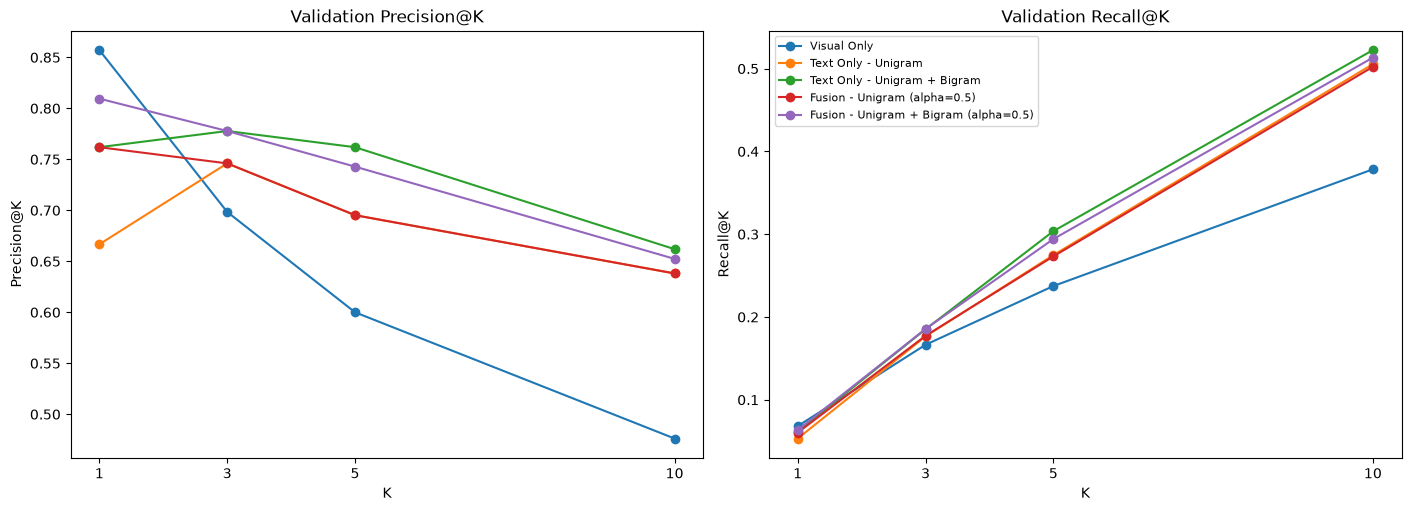

[SAVED] 211_validation_precision_recall_at_k.png


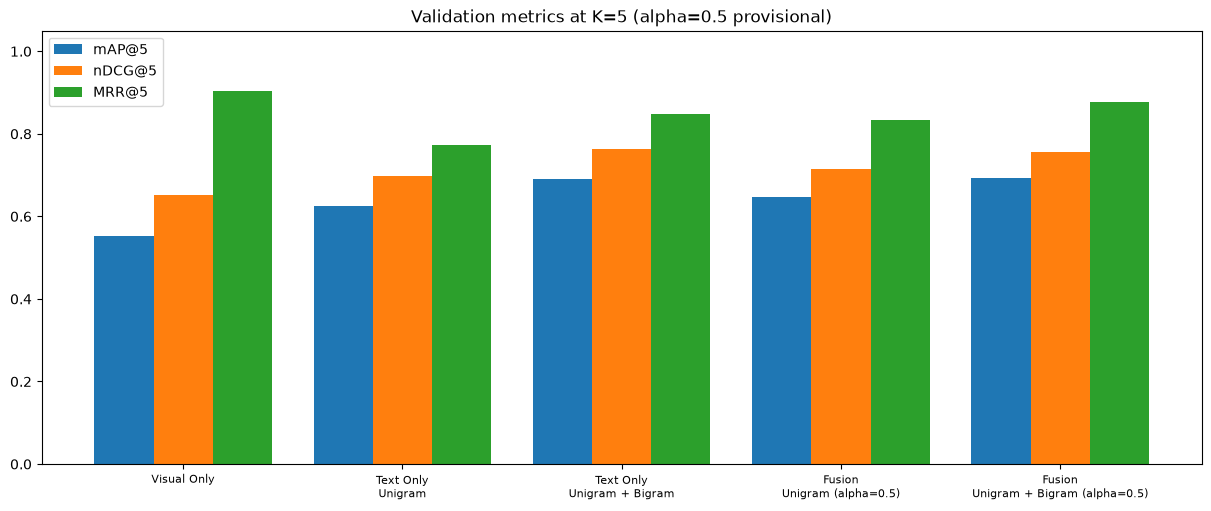

[SAVED] 212_validation_map_ndcg_at_5.png
[SAVED] 653_validation_per_query_metrics.csv
[SAVED] 654_validation_macro_metric_summary.csv
[SAVED] 655_validation_per_class_metrics.csv
[SAVED] 656_validation_relevance_denominators.csv
[SAVED] 657_validation_metric_checks.csv
[SAVED] 658_validation_method_comparison_at_5.csv
[SAVED] 659_validation_metric_protocol.csv

CELL 7 COMPLETED


In [8]:
# ============================================================
# CELL 7 - VALIDATION RETRIEVAL METRICS
# ============================================================
# Relevance: gallery item has the same plant class as the query.
#   Precision@K = hits@K / K
#   Recall@K    = hits@K / R            (R = relevant items in gallery)
#   MRR@K       = 1 / first relevant rank within K (0 if none)
#   AP@K        = sum_{i<=K} P@i * rel_i / min(R, K)
#   nDCG@K      = DCG@K / IDCG@K, binary gain, log2(i + 1) discount
# Macro values are the arithmetic mean over queries.

assert globals().get("EVAL06_VALIDATION_RANKING_COMPLETED") is True, "Jalankan Cell 6 terlebih dahulu."

EVAL06_VALIDATION_METRICS_COMPLETED = False
eval06_metric_checks = []

print("NOTEBOOK 06 - CELL 7: VALIDATION RETRIEVAL METRICS")
print("=" * 75)

EVAL06_METRIC_COLUMNS = ["precision_at_k", "recall_at_k", "mrr_at_k", "ap_at_k", "ndcg_at_k"]
EVAL06_MACRO_COLUMNS = {"precision_at_k": "mean_precision_at_k", "recall_at_k": "mean_recall_at_k",
                        "mrr_at_k": "mean_mrr_at_k", "ap_at_k": "map_at_k", "ndcg_at_k": "mean_ndcg_at_k"}
EVAL06_METRIC_DISPLAY = {"mean_precision_at_k": "Precision@K", "mean_recall_at_k": "Recall@K",
                         "mean_mrr_at_k": "MRR@K", "map_at_k": "mAP@K", "mean_ndcg_at_k": "nDCG@K"}


def eval06_metrics_at_k(ranked_relevance, relevant_count, k):
    rel = np.asarray(ranked_relevance, dtype=np.int64).ravel()
    R, k = int(relevant_count), int(k)
    if R <= 0:
        raise ValueError("Query has no relevant gallery item.")
    if not 1 <= k <= len(rel):
        raise ValueError("K outside ranking length.")
    if not np.isin(rel, (0, 1)).all() or int(rel.sum()) != R:
        raise ValueError("Relevance vector inconsistent with R.")
    top = rel[:k]
    hits = int(top.sum())
    positions = np.arange(1, k + 1, dtype=np.float64)
    first = np.flatnonzero(top)
    dcg = float((top / np.log2(positions + 1)).sum())
    ideal = int(min(R, k))
    idcg = float((1.0 / np.log2(np.arange(1, ideal + 1) + 1)).sum())
    return {
        "precision_at_k": hits / k,
        "recall_at_k": hits / R,
        "mrr_at_k": 1.0 / (first[0] + 1) if first.size else 0.0,
        "ap_at_k": float(((np.cumsum(top) / positions) * top).sum() / min(R, k)),
        "ndcg_at_k": dcg / idcg,
        "hits_at_k": hits,
    }


# ---------------- unit tests (hand-computed) ----------------
unit = eval06_metrics_at_k([1, 0, 1, 0, 0, 1], 3, 3)
eval06_check(eval06_metric_checks, "Unit test", "Precision@3 = 2/3", np.isclose(unit["precision_at_k"], 2 / 3))
eval06_check(eval06_metric_checks, "Unit test", "Recall@3 = 2/3", np.isclose(unit["recall_at_k"], 2 / 3))
eval06_check(eval06_metric_checks, "Unit test", "MRR@3 = 1", np.isclose(unit["mrr_at_k"], 1.0))
eval06_check(eval06_metric_checks, "Unit test", "AP@3 = (1 + 2/3)/3", np.isclose(unit["ap_at_k"], (1 + 2 / 3) / 3))
eval06_check(eval06_metric_checks, "Unit test", "nDCG@3 = (1 + 1/2) / (1 + 1/log2(3) + 1/2)",
             np.isclose(unit["ndcg_at_k"], (1 + 0.5) / (1 + 1 / np.log2(3) + 0.5)))
unit2 = eval06_metrics_at_k([0, 0, 1, 1], 2, 1)
eval06_check(eval06_metric_checks, "Unit test", "All-miss@1 gives zeros",
             all(unit2[m] == 0 for m in EVAL06_METRIC_COLUMNS))
unit3 = eval06_metrics_at_k([1, 1, 0, 0], 2, 2)
eval06_check(eval06_metric_checks, "Unit test", "Perfect@2 gives ones",
             all(np.isclose(unit3[m], 1.0) for m in EVAL06_METRIC_COLUMNS))

EVAL06_GALLERY_CLASS_COUNTS = pd.Series(EVAL06_GALLERY_LABELS).value_counts().to_dict()


def eval06_per_query_metrics(split, scores, method, text_config, alpha):
    labels = EVAL06_SPLIT_LABELS[split]
    orders = eval06_rank_matrix(scores)
    rows = []
    for qi, qid in enumerate(EVAL06_QUERY_IDS[split]):
        relevance = (EVAL06_GALLERY_LABELS[orders[qi]] == labels[qi]).astype(int)
        R = EVAL06_GALLERY_CLASS_COUNTS[labels[qi]]
        for k in EVAL06_TOP_K_VALUES:
            rows.append({"query_partition": split, "method": method, "text_configuration": text_config,
                         "alpha": float(alpha), "query_sample_id": qid, "query_class": labels[qi],
                         "k": k, "relevant_gallery_count": R, **eval06_metrics_at_k(relevance, R, k)})
    return pd.DataFrame(rows)


def eval06_macro(per_query, keys):
    macro = (per_query.groupby(keys + ["k"], sort=False)[EVAL06_METRIC_COLUMNS].mean()
             .rename(columns=EVAL06_MACRO_COLUMNS).reset_index())
    counts = per_query.groupby(keys + ["k"], sort=False)["query_sample_id"].nunique().reset_index(name="queries")
    return macro.merge(counts, on=keys + ["k"])


per_query = [eval06_per_query_metrics("validation", EVAL06_VALIDATION_SCORES[m], m, c, a)
             for m, c, a in EVAL06_VALIDATION_METHODS]
EVAL06_VALIDATION_PER_QUERY_DF = pd.concat(per_query, ignore_index=True)
EVAL06_VALIDATION_MACRO_DF = eval06_macro(EVAL06_VALIDATION_PER_QUERY_DF, ["method"])
EVAL06_VALIDATION_CLASS_DF = eval06_macro(EVAL06_VALIDATION_PER_QUERY_DF, ["method", "query_class"])
EVAL06_VALIDATION_AT5_DF = EVAL06_VALIDATION_MACRO_DF.loc[EVAL06_VALIDATION_MACRO_DF["k"] == EVAL06_PRIMARY_K].reset_index(drop=True)
EVAL06_RELEVANCE_DENOMINATORS_DF = pd.DataFrame({
    "query_sample_id": EVAL06_QUERY_IDS["validation"], "query_class": EVAL06_SPLIT_LABELS["validation"],
    "relevant_gallery_count": [EVAL06_GALLERY_CLASS_COUNTS[c] for c in EVAL06_SPLIT_LABELS["validation"]],
    "gallery_count": n_gallery})

# Cross-checks: metrics recomputed from the saved ranking table (Cell 6).
recheck = []
for (method, qid), group in EVAL06_VALIDATION_RANKINGS_DF.groupby(["method", "query_sample_id"]):
    rel = group.sort_values("rank")["relevant"].to_numpy(dtype=int)
    m5 = eval06_metrics_at_k(rel, int(rel.sum()), 5)
    stored = EVAL06_VALIDATION_PER_QUERY_DF.query("method == @method and query_sample_id == @qid and k == 5").iloc[0]
    recheck.append(all(np.isclose(m5[c], stored[c]) for c in EVAL06_METRIC_COLUMNS))
eval06_check(eval06_metric_checks, "Consistency", "Per-query metrics match Cell 6 ranking table (K=5)", all(recheck))
eval06_check(eval06_metric_checks, "Consistency", "Macro = mean of per-query values",
             np.allclose(EVAL06_VALIDATION_PER_QUERY_DF.groupby(["method", "k"], sort=False)["ap_at_k"].mean().to_numpy(),
                         EVAL06_VALIDATION_MACRO_DF["map_at_k"].to_numpy()))
eval06_check(eval06_metric_checks, "Consistency", "All metric values within [0, 1]",
             EVAL06_VALIDATION_PER_QUERY_DF[EVAL06_METRIC_COLUMNS].stack().between(0, 1 + 1e-12).all())
eval06_check(eval06_metric_checks, "Consistency", "Precision@1 == MRR@1 == AP@1 == nDCG@1",
             EVAL06_VALIDATION_PER_QUERY_DF.query("k == 1")[["precision_at_k", "mrr_at_k", "ap_at_k", "ndcg_at_k"]]
             .nunique(axis=1).eq(1).all())
eval06_check(eval06_metric_checks, "Consistency", "Recall@K non-decreasing in K",
             EVAL06_VALIDATION_PER_QUERY_DF.sort_values("k").groupby(["method", "query_sample_id"])["recall_at_k"]
             .apply(lambda v: bool(np.all(np.diff(v.to_numpy()) >= -1e-15))).all())
EVAL06_VALIDATION_METRIC_CHECKS_DF = eval06_checks_frame(eval06_metric_checks)

print("\n1. VALIDATION MACRO METRICS")
print("-" * 75)
display(EVAL06_VALIDATION_MACRO_DF.round(4))
print("\n2. METHOD COMPARISON AT K=5")
print("-" * 75)
display(EVAL06_VALIDATION_AT5_DF.round(4))
display(EVAL06_VALIDATION_METRIC_CHECKS_DF)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
for method, _, _ in EVAL06_VALIDATION_METHODS:
    sub = EVAL06_VALIDATION_MACRO_DF.loc[EVAL06_VALIDATION_MACRO_DF["method"] == method]
    axes[0].plot(sub["k"], sub["mean_precision_at_k"], marker="o", label=method)
    axes[1].plot(sub["k"], sub["mean_recall_at_k"], marker="o", label=method)
axes[0].set(title="Validation Precision@K", xlabel="K", ylabel="Precision@K", xticks=EVAL06_TOP_K_VALUES)
axes[1].set(title="Validation Recall@K", xlabel="K", ylabel="Recall@K", xticks=EVAL06_TOP_K_VALUES)
axes[1].legend(fontsize=8)
eval06_save_figure(fig, "211_validation_precision_recall_at_k.png", 7)

fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
x = np.arange(len(EVAL06_VALIDATION_AT5_DF))
for k_, col in enumerate(["map_at_k", "mean_ndcg_at_k", "mean_mrr_at_k"]):
    ax.bar(x + (k_ - 1) * 0.27, EVAL06_VALIDATION_AT5_DF[col], width=0.27, label=EVAL06_METRIC_DISPLAY[col].replace("K", "5"))
ax.set_xticks(x, [m.replace(" - ", "\n") for m in EVAL06_VALIDATION_AT5_DF["method"]], fontsize=8)
ax.set(ylim=(0, 1.05), title="Validation metrics at K=5 (alpha=0.5 provisional)")
ax.legend()
eval06_save_figure(fig, "212_validation_map_ndcg_at_5.png", 7)

eval06_save_csv(EVAL06_VALIDATION_PER_QUERY_DF, "653_validation_per_query_metrics.csv", 7)
eval06_save_csv(EVAL06_VALIDATION_MACRO_DF, "654_validation_macro_metric_summary.csv", 7)
eval06_save_csv(EVAL06_VALIDATION_CLASS_DF, "655_validation_per_class_metrics.csv", 7)
eval06_save_csv(EVAL06_RELEVANCE_DENOMINATORS_DF, "656_validation_relevance_denominators.csv", 7)
eval06_save_csv(EVAL06_VALIDATION_METRIC_CHECKS_DF, "657_validation_metric_checks.csv", 7)
eval06_save_csv(EVAL06_VALIDATION_AT5_DF, "658_validation_method_comparison_at_5.csv", 7)
eval06_save_csv(pd.DataFrame([
    ("Relevance", EVAL06_RELEVANCE_POLICY), ("AP", EVAL06_AP_CONVENTION), ("nDCG", EVAL06_NDCG_CONVENTION),
    ("Ranking ties", EVAL06_RANKING_TIE_POLICY), ("Macro", "mean over queries")],
    columns=["item", "definition"]), "659_validation_metric_protocol.csv", 7)

eval06_require(EVAL06_VALIDATION_METRIC_CHECKS_DF, "Cell 7")
EVAL06_VALIDATION_METRICS_COMPLETED = True
print("\nCELL 7 COMPLETED")

## Cell 8 — Alpha Sensitivity (validation)

NOTEBOOK 06 - CELL 8: ALPHA SENSITIVITY (VALIDATION)
Alpha sensitivity at K=5 (validation):


,text_configuration,alpha,mean_precision_at_k,mean_recall_at_k,mean_mrr_at_k,map_at_k,mean_ndcg_at_k
0,Unigram,0.0,0.6952,0.2748,0.7738,0.6246,0.6988
1,Unigram,0.1,0.6952,0.2748,0.7738,0.6246,0.6988
2,Unigram,0.2,0.6762,0.2669,0.7778,0.6140,0.6874
3,Unigram,0.3,0.6952,0.2732,0.8016,0.6324,0.7047
4,Unigram,0.4,0.6952,0.2732,0.8254,0.6375,0.7103
5,Unigram,0.5,0.6952,0.2732,0.8333,0.6476,0.7142
6,Unigram,0.6,0.6952,0.2732,0.8571,0.6654,0.7251
7,Unigram,0.7,0.7048,0.2776,0.8667,0.6727,0.7343
8,Unigram,0.8,0.6952,0.2747,0.8571,0.6708,0.7306
9,Unigram,0.9,0.6952,0.2743,0.9048,0.6625,0.7341


,category,validation_check,passed,severity_if_failed,detail
0,Grid,22 candidates (2 TF-IDF x 11 alpha),True,BLOCK,
1,Grid,Per-query rows = 22 x queries x 4 K,True,BLOCK,
2,Anchors,"alpha = 0, 0.5, 1 reproduce Cell 7 exactly",True,BLOCK,24/24
3,Partition,Only validation queries used,True,BLOCK,
4,Ranking,Top-10 lists have no duplicate gallery IDs,True,BLOCK,


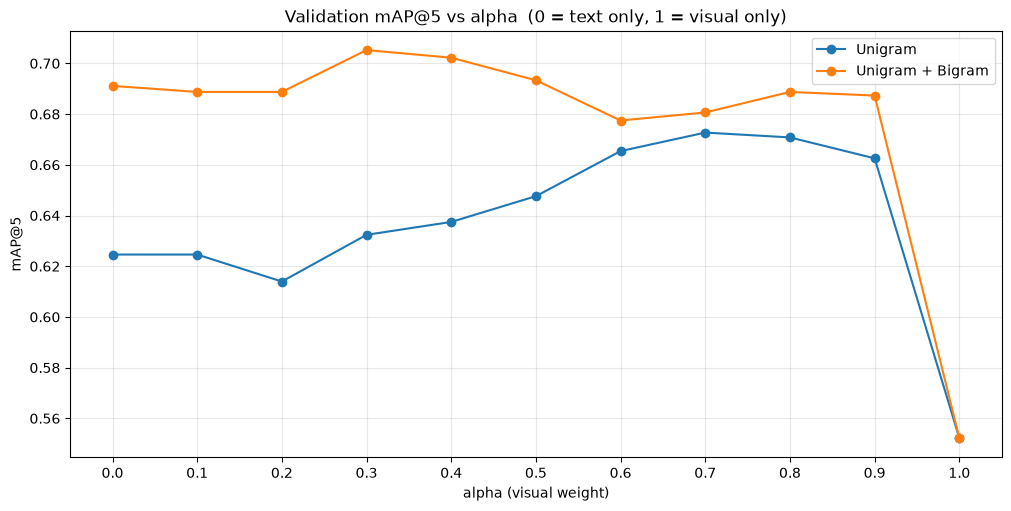

[SAVED] 213_validation_alpha_sensitivity_map_at_5.png


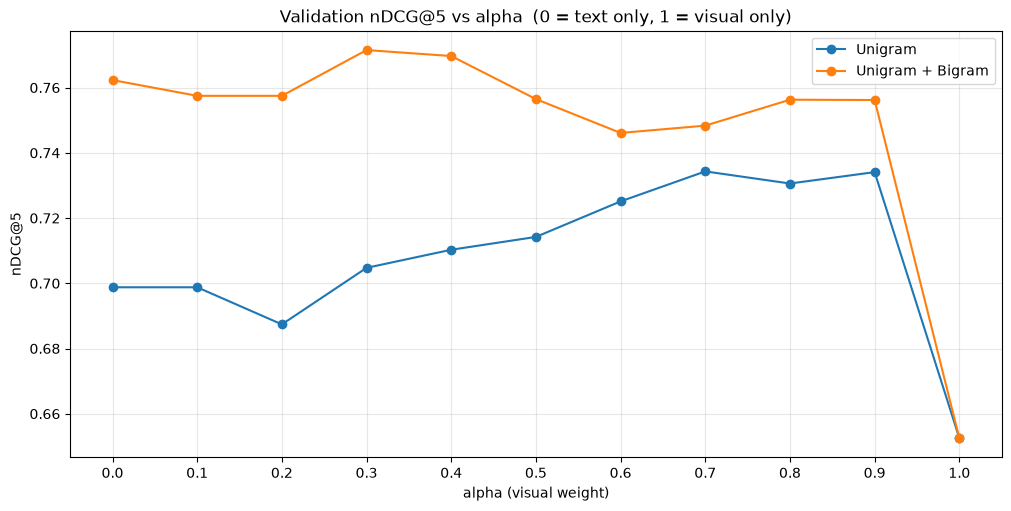

[SAVED] 214_validation_alpha_sensitivity_ndcg_at_5.png
[SAVED] 661_validation_alpha_grid.csv
[SAVED] 662_validation_alpha_per_query_metrics.csv
[SAVED] 663_validation_alpha_macro_metrics.csv
[SAVED] 664_validation_alpha_per_class_metrics.csv
[SAVED] 665_validation_alpha_top10_rankings.csv
[SAVED] 666_validation_alpha_technical_checks.csv
[SAVED] 667_validation_alpha_sensitivity_at_5.csv
[SAVED] 668_validation_alpha_cell7_anchor_checks.csv

CELL 8 COMPLETED | no configuration selected yet; test not used.


In [9]:
# ============================================================
# CELL 8 - FUSION ALPHA SENSITIVITY (VALIDATION ONLY)
# ============================================================
# alpha in {0.0, 0.1, ..., 1.0} for both TF-IDF configurations.
# alpha = 0 -> Text Only, alpha = 1 -> Visual Only.

assert globals().get("EVAL06_VALIDATION_METRICS_COMPLETED") is True, "Jalankan Cell 7 terlebih dahulu."

EVAL06_ALPHA_SENSITIVITY_COMPLETED = False
eval06_alpha_checks = []

print("NOTEBOOK 06 - CELL 8: ALPHA SENSITIVITY (VALIDATION)")
print("=" * 75)

alpha_frames, alpha_top10 = [], []
EVAL06_ALPHA_GRID_DF = pd.DataFrame([(c, i, float(a)) for c in EVAL06_TEXT_CONFIGURATIONS
                                     for i, a in enumerate(EVAL06_ALPHA_GRID)],
                                    columns=["text_configuration", "alpha_index", "alpha"])
for row in EVAL06_ALPHA_GRID_DF.itertuples(index=False):
    scores = eval06_fused_scores("validation", row.text_configuration, row.alpha)
    pq = eval06_per_query_metrics("validation", scores, "Weighted Fusion", row.text_configuration, row.alpha)
    pq["alpha_index"] = row.alpha_index
    alpha_frames.append(pq)
    alpha_top10.append(eval06_rankings_frame("validation", "Weighted Fusion", scores,
                                             row.text_configuration, row.alpha, top_n=10))
EVAL06_ALPHA_PER_QUERY_DF = pd.concat(alpha_frames, ignore_index=True)
EVAL06_ALPHA_TOP10_DF = pd.concat(alpha_top10, ignore_index=True)
EVAL06_ALPHA_MACRO_DF = eval06_macro(EVAL06_ALPHA_PER_QUERY_DF, ["text_configuration", "alpha_index", "alpha"])
EVAL06_ALPHA_CLASS_DF = eval06_macro(EVAL06_ALPHA_PER_QUERY_DF, ["text_configuration", "alpha_index", "alpha", "query_class"])
EVAL06_ALPHA_AT5_DF = EVAL06_ALPHA_MACRO_DF.loc[EVAL06_ALPHA_MACRO_DF["k"] == EVAL06_PRIMARY_K].reset_index(drop=True)

# Anchor checks against Cell 7
anchor_rows = []
anchors = [("Visual Only", c, 1.0) for c in EVAL06_TEXT_CONFIGURATIONS] + \
          [(f"Text Only - {c}", c, 0.0) for c in EVAL06_TEXT_CONFIGURATIONS] + \
          [(f"Fusion - {c} (alpha={EVAL06_DEFAULT_ALPHA})", c, EVAL06_DEFAULT_ALPHA) for c in EVAL06_TEXT_CONFIGURATIONS]
for method, config, alpha in anchors:
    for k in EVAL06_TOP_K_VALUES:
        a = EVAL06_ALPHA_MACRO_DF.loc[(EVAL06_ALPHA_MACRO_DF["text_configuration"] == config)
                                      & np.isclose(EVAL06_ALPHA_MACRO_DF["alpha"], alpha)
                                      & (EVAL06_ALPHA_MACRO_DF["k"] == k)].iloc[0]
        b = EVAL06_VALIDATION_MACRO_DF.loc[(EVAL06_VALIDATION_MACRO_DF["method"] == method)
                                           & (EVAL06_VALIDATION_MACRO_DF["k"] == k)].iloc[0]
        diff = max(abs(a[c] - b[c]) for c in EVAL06_MACRO_COLUMNS.values())
        anchor_rows.append({"cell7_method": method, "text_configuration": config, "alpha": alpha, "k": k,
                            "max_abs_difference": diff, "passed": diff <= 1e-12})
EVAL06_ALPHA_ANCHOR_DF = pd.DataFrame(anchor_rows)

eval06_check(eval06_alpha_checks, "Grid", "22 candidates (2 TF-IDF x 11 alpha)", len(EVAL06_ALPHA_GRID_DF) == 22)
eval06_check(eval06_alpha_checks, "Grid", "Per-query rows = 22 x queries x 4 K",
             len(EVAL06_ALPHA_PER_QUERY_DF) == 22 * len(EVAL06_QUERY_IDS["validation"]) * len(EVAL06_TOP_K_VALUES))
eval06_check(eval06_alpha_checks, "Anchors", "alpha = 0, 0.5, 1 reproduce Cell 7 exactly",
             EVAL06_ALPHA_ANCHOR_DF["passed"].all(), detail=f"{int(EVAL06_ALPHA_ANCHOR_DF['passed'].sum())}/{len(EVAL06_ALPHA_ANCHOR_DF)}")
eval06_check(eval06_alpha_checks, "Partition", "Only validation queries used",
             set(EVAL06_ALPHA_PER_QUERY_DF["query_sample_id"]) == set(EVAL06_QUERY_IDS["validation"]))
eval06_check(eval06_alpha_checks, "Ranking", "Top-10 lists have no duplicate gallery IDs",
             EVAL06_ALPHA_TOP10_DF.groupby(["text_configuration", "alpha", "query_sample_id"])["gallery_sample_id"]
             .apply(lambda v: v.is_unique).all())
EVAL06_ALPHA_CHECKS_DF = eval06_checks_frame(eval06_alpha_checks)

print("Alpha sensitivity at K=5 (validation):")
display(EVAL06_ALPHA_AT5_DF[["text_configuration", "alpha", "mean_precision_at_k", "mean_recall_at_k",
                             "mean_mrr_at_k", "map_at_k", "mean_ndcg_at_k"]].round(4))
display(EVAL06_ALPHA_CHECKS_DF)

for filename, column, label in [("213_validation_alpha_sensitivity_map_at_5.png", "map_at_k", "mAP@5"),
                                ("214_validation_alpha_sensitivity_ndcg_at_5.png", "mean_ndcg_at_k", "nDCG@5")]:
    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
    for config in EVAL06_TEXT_CONFIGURATIONS:
        sub = EVAL06_ALPHA_AT5_DF.loc[EVAL06_ALPHA_AT5_DF["text_configuration"] == config]
        ax.plot(sub["alpha"], sub[column], marker="o", label=config)
    ax.set(title=f"Validation {label} vs alpha  (0 = text only, 1 = visual only)",
           xlabel="alpha (visual weight)", ylabel=label, xticks=EVAL06_ALPHA_GRID)
    ax.grid(alpha=0.3)
    ax.legend()
    eval06_save_figure(fig, filename, 8)

eval06_save_csv(EVAL06_ALPHA_GRID_DF, "661_validation_alpha_grid.csv", 8)
eval06_save_csv(EVAL06_ALPHA_PER_QUERY_DF, "662_validation_alpha_per_query_metrics.csv", 8)
eval06_save_csv(EVAL06_ALPHA_MACRO_DF, "663_validation_alpha_macro_metrics.csv", 8)
eval06_save_csv(EVAL06_ALPHA_CLASS_DF, "664_validation_alpha_per_class_metrics.csv", 8)
eval06_save_csv(EVAL06_ALPHA_TOP10_DF, "665_validation_alpha_top10_rankings.csv", 8)
eval06_save_csv(EVAL06_ALPHA_CHECKS_DF, "666_validation_alpha_technical_checks.csv", 8)
eval06_save_csv(EVAL06_ALPHA_AT5_DF, "667_validation_alpha_sensitivity_at_5.csv", 8)
eval06_save_csv(EVAL06_ALPHA_ANCHOR_DF, "668_validation_alpha_cell7_anchor_checks.csv", 8)

eval06_require(EVAL06_ALPHA_CHECKS_DF, "Cell 8")
EVAL06_ALPHA_SENSITIVITY_COMPLETED = True
print("\nCELL 8 COMPLETED | no configuration selected yet; test not used.")

## Cell 9 — Validation-Only Fusion Selection

NOTEBOOK 06 - CELL 9: VALIDATION-ONLY SELECTION
Selected TF-IDF      : Unigram + Bigram
Selected alpha       : 0.3
Method               : Weighted Late Fusion
Validation mAP@5     : 0.7052
Validation nDCG@5    : 0.7715
Tie pool after metrics: 1
Selection lock SHA-256: 29419a04188b6fc9 ...


,comparison,text_configuration,alpha,map_at_5,ndcg_at_5,mrr_at_5,precision_at_5,recall_at_5
0,Selected (validation rule),Unigram + Bigram,0.3,0.7052,0.7715,0.8532,0.7714,0.3061
1,Default alpha=0.5 (selected TF-IDF),Unigram + Bigram,0.5,0.6933,0.7565,0.8770,0.7429,0.2942
2,Best genuine fusion 0<alpha<1,Unigram + Bigram,0.3,0.7052,0.7715,0.8532,0.7714,0.3061
3,Visual Only (alpha=1),Unigram + Bigram,1.0,0.5522,0.6525,0.9048,0.6000,0.2374
4,Text Only - Unigram + Bigram (alpha=0),Unigram + Bigram,0.0,0.6911,0.7623,0.8492,0.7619,0.3037
5,Text Only - Unigram (alpha=0),Unigram,0.0,0.6246,0.6988,0.7738,0.6952,0.2748


,category,validation_check,passed,severity_if_failed,detail
0,Selection,Selection independent of candidate order,True,BLOCK,
1,Selection,Selected candidate has maximal validation mAP@5,True,BLOCK,
2,Selection,Exactly 22 candidates evaluated,True,BLOCK,
3,Selection,Only validation partition used,True,BLOCK,
4,Selection,Selected configuration is a genuine fusion (0 ...,True,REVIEW,alpha=0.3


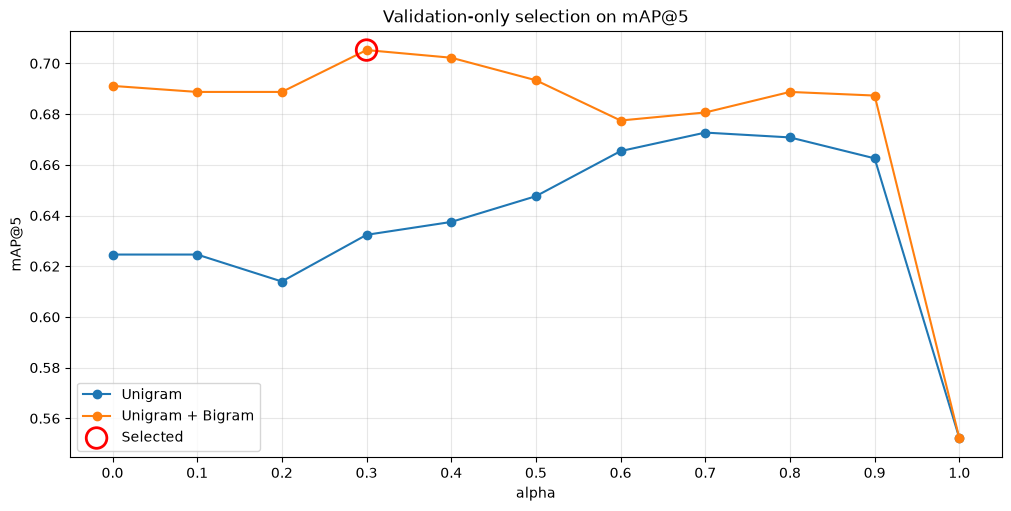

[SAVED] 215_validation_fusion_selection_map5.png


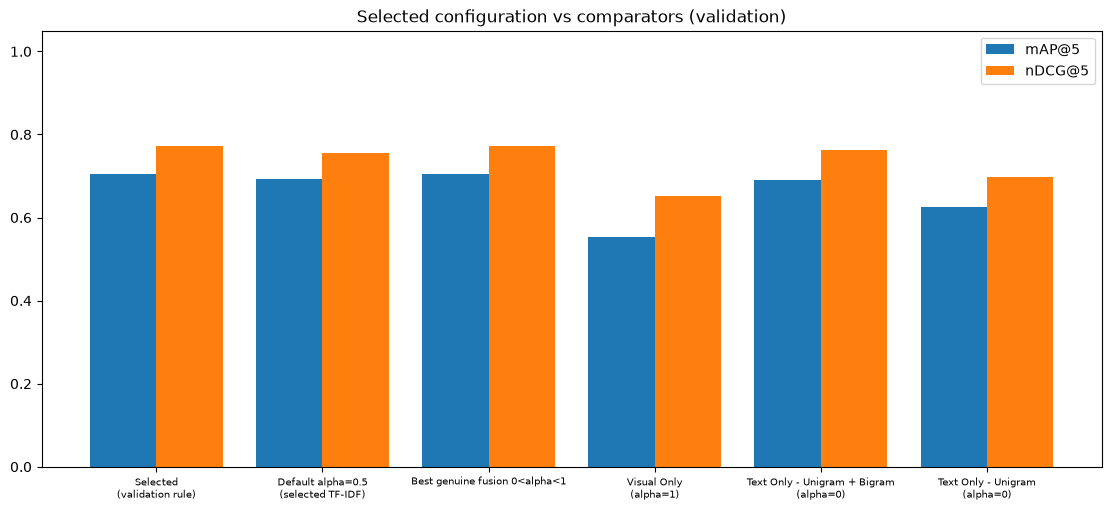

[SAVED] 216_validation_selected_vs_comparators.png
[SAVED] 671_validation_fusion_candidate_scores.csv
[SAVED] 672_selected_fusion_metrics_by_k.csv
[SAVED] 673_selected_fusion_per_query_metrics.csv
[SAVED] 674_selected_fusion_top10_validation.csv
[SAVED] 675_selected_vs_comparators.csv
[SAVED] 676_fusion_selection_validation_checks.csv

CELL 9 COMPLETED | configuration locked from validation only.


In [10]:
# ============================================================
# CELL 9 - VALIDATION-ONLY FUSION SELECTION & SELECTION LOCK
# ============================================================
# Candidates: 22 (2 TF-IDF configurations x 11 alpha values), validation only.
# Rule: max mAP@5 -> max nDCG@5 -> max MRR@5 (tolerance 1e-10)
#       -> alpha closest to 0.5 -> Unigram first -> smaller alpha.
# alpha = 0.3 from earlier experiments is NOT reused: alpha is re-selected
# here from the corrected features.

assert globals().get("EVAL06_ALPHA_SENSITIVITY_COMPLETED") is True, "Jalankan Cell 8 terlebih dahulu."

EVAL06_FUSION_SELECTION_LOCKED = False
eval06_selection_checks = []

print("NOTEBOOK 06 - CELL 9: VALIDATION-ONLY SELECTION")
print("=" * 75)

SEL09_CONFIG_PRIORITY = {"Unigram": 0, "Unigram + Bigram": 1}
candidates = EVAL06_ALPHA_AT5_DF.copy()


def sel09_select(frame):
    pool = frame.copy()
    for column in ["map_at_k", "mean_ndcg_at_k", "mean_mrr_at_k"]:
        best = float(pool[column].max())
        pool = pool.loc[np.isclose(pool[column].to_numpy(float), best, atol=EVAL06_SELECTION_TOLERANCE, rtol=0)]
    pool = pool.assign(alpha_distance_to_half=(pool["alpha"] - 0.5).abs(),
                       config_priority=pool["text_configuration"].map(SEL09_CONFIG_PRIORITY))
    pool = pool.sort_values(["alpha_distance_to_half", "config_priority", "alpha", "alpha_index"], kind="stable")
    return pool.iloc[0], len(pool)


chosen, tie_pool_size = sel09_select(candidates)
EVAL06_SELECTED_TEXT_CONFIG = str(chosen["text_configuration"])
EVAL06_SELECTED_ALPHA = float(round(chosen["alpha"], 10))
EVAL06_SELECTED_ALPHA_INDEX = int(chosen["alpha_index"])
EVAL06_SELECTED_IS_GENUINE_FUSION = bool(0 < EVAL06_SELECTED_ALPHA < 1)
EVAL06_SELECTED_METHOD = ("Weighted Late Fusion" if EVAL06_SELECTED_IS_GENUINE_FUSION
                          else ("Text Only" if EVAL06_SELECTED_ALPHA == 0 else "Visual Only"))
EVAL06_SELECTED_LABEL = f"Weighted Fusion - {EVAL06_SELECTED_TEXT_CONFIG} (alpha={EVAL06_SELECTED_ALPHA:.1f})"

# Order-independence check: selection must not depend on row order.
shuffled_choice, _ = sel09_select(candidates.sample(frac=1.0, random_state=7))
eval06_check(eval06_selection_checks, "Selection", "Selection independent of candidate order",
             (shuffled_choice["text_configuration"], float(shuffled_choice["alpha"]))
             == (EVAL06_SELECTED_TEXT_CONFIG, EVAL06_SELECTED_ALPHA))
eval06_check(eval06_selection_checks, "Selection", "Selected candidate has maximal validation mAP@5",
             np.isclose(chosen["map_at_k"], candidates["map_at_k"].max(), atol=EVAL06_SELECTION_TOLERANCE, rtol=0))
eval06_check(eval06_selection_checks, "Selection", "Exactly 22 candidates evaluated", len(candidates) == 22)
eval06_check(eval06_selection_checks, "Selection", "Only validation partition used",
             (EVAL06_ALPHA_PER_QUERY_DF["query_partition"] == "validation").all())
eval06_check(eval06_selection_checks, "Selection", "Selected configuration is a genuine fusion (0 < alpha < 1)",
             EVAL06_SELECTED_IS_GENUINE_FUSION, detail=f"alpha={EVAL06_SELECTED_ALPHA}", severity="REVIEW")


def at5(config, alpha):
    return candidates.loc[(candidates["text_configuration"] == config) & np.isclose(candidates["alpha"], alpha)].iloc[0]


genuine = candidates.loc[(candidates["alpha"] > 0) & (candidates["alpha"] < 1)]
best_genuine, _ = sel09_select(genuine)
comparison = [
    ("Selected (validation rule)", chosen),
    (f"Default alpha={EVAL06_DEFAULT_ALPHA} (selected TF-IDF)", at5(EVAL06_SELECTED_TEXT_CONFIG, EVAL06_DEFAULT_ALPHA)),
    ("Best genuine fusion 0<alpha<1", best_genuine),
    ("Visual Only (alpha=1)", at5(EVAL06_SELECTED_TEXT_CONFIG, 1.0)),
    (f"Text Only - {EVAL06_SELECTED_TEXT_CONFIG} (alpha=0)", at5(EVAL06_SELECTED_TEXT_CONFIG, 0.0)),
]
for config in EVAL06_TEXT_CONFIGURATIONS:
    if config != EVAL06_SELECTED_TEXT_CONFIG:
        comparison.append((f"Text Only - {config} (alpha=0)", at5(config, 0.0)))
EVAL06_SELECTION_COMPARISON_DF = pd.DataFrame([{
    "comparison": name, "text_configuration": r["text_configuration"], "alpha": float(r["alpha"]),
    "map_at_5": float(r["map_at_k"]), "ndcg_at_5": float(r["mean_ndcg_at_k"]), "mrr_at_5": float(r["mean_mrr_at_k"]),
    "precision_at_5": float(r["mean_precision_at_k"]), "recall_at_5": float(r["mean_recall_at_k"])}
    for name, r in comparison])

EVAL06_SELECTED_METRICS_BY_K_DF = EVAL06_ALPHA_MACRO_DF.loc[
    (EVAL06_ALPHA_MACRO_DF["text_configuration"] == EVAL06_SELECTED_TEXT_CONFIG)
    & np.isclose(EVAL06_ALPHA_MACRO_DF["alpha"], EVAL06_SELECTED_ALPHA)].reset_index(drop=True)
EVAL06_SELECTED_PER_QUERY_DF = EVAL06_ALPHA_PER_QUERY_DF.loc[
    (EVAL06_ALPHA_PER_QUERY_DF["text_configuration"] == EVAL06_SELECTED_TEXT_CONFIG)
    & np.isclose(EVAL06_ALPHA_PER_QUERY_DF["alpha"], EVAL06_SELECTED_ALPHA)].reset_index(drop=True)
EVAL06_SELECTED_TOP10_DF = EVAL06_ALPHA_TOP10_DF.loc[
    (EVAL06_ALPHA_TOP10_DF["text_configuration"] == EVAL06_SELECTED_TEXT_CONFIG)
    & np.isclose(EVAL06_ALPHA_TOP10_DF["alpha"], EVAL06_SELECTED_ALPHA)].reset_index(drop=True)

# ------------------------------------------------------------
# Selection lock (deterministic content: no timestamps / paths)
# ------------------------------------------------------------
evidence_cols = ["text_configuration", "alpha_index", "alpha", "map_at_k", "mean_ndcg_at_k", "mean_mrr_at_k"]
EVAL06_SELECTION_EVIDENCE_SHA256 = eval06_sha256_bytes(eval06_canonical_json(
    candidates[evidence_cols].round(12).to_dict("records")).encode())
EVAL06_SELECTION_LOCK = {
    "selection_partition": "validation",
    "primary_metric": EVAL06_PRIMARY_SELECTION_METRIC,
    "tie_break_rules": EVAL06_TIE_BREAK_RULES,
    "selection_tolerance": EVAL06_SELECTION_TOLERANCE,
    "candidate_count": int(len(candidates)),
    "selected_text_configuration": EVAL06_SELECTED_TEXT_CONFIG,
    "selected_alpha": EVAL06_SELECTED_ALPHA,
    "selected_alpha_index": EVAL06_SELECTED_ALPHA_INDEX,
    "selected_method_type": EVAL06_SELECTED_METHOD,
    "selected_validation_map_at_5": round(float(chosen["map_at_k"]), 12),
    "selected_validation_ndcg_at_5": round(float(chosen["mean_ndcg_at_k"]), 12),
    "selected_validation_mrr_at_5": round(float(chosen["mean_mrr_at_k"]), 12),
    "tie_pool_size_after_metrics": int(tie_pool_size),
    "evidence_sha256": EVAL06_SELECTION_EVIDENCE_SHA256,
    "feature_fingerprint": EVAL06_FEATURE_FINGERPRINT,
    "split_fingerprint": EVAL06_SPLIT_FINGERPRINT,
    "visual_distance_scale": round(EVAL06_VISUAL_DISTANCE_SCALE, 12),
    "selected_using_test": False,
    "legacy_alpha_reused": False,
}
EVAL06_SELECTION_LOCK_PATH = EVAL06_METRICS_DIR / "678_validation_fusion_selection_lock.json"
EVAL06_SELECTION_LOCK_PATH.write_text(json.dumps(EVAL06_SELECTION_LOCK, indent=2, sort_keys=True,
                                                 ensure_ascii=False), encoding="utf-8")
eval06_log_output(EVAL06_SELECTION_LOCK_PATH, 9, "json")
EVAL06_SELECTION_LOCK_SHA256 = eval06_sha256_file(EVAL06_SELECTION_LOCK_PATH)
EVAL06_RUN_MANIFEST["stage_fingerprints"]["selection_lock"] = EVAL06_SELECTION_LOCK_SHA256
eval06_update_registry(selection_lock_sha256=EVAL06_SELECTION_LOCK_SHA256,
                       selected_text_configuration=EVAL06_SELECTED_TEXT_CONFIG,
                       selected_alpha=EVAL06_SELECTED_ALPHA,
                       validation_map_at_5=round(float(chosen["map_at_k"]), 6))
EVAL06_SELECTION_CHECKS_DF = eval06_checks_frame(eval06_selection_checks)

print("Selected TF-IDF      :", EVAL06_SELECTED_TEXT_CONFIG)
print("Selected alpha       :", EVAL06_SELECTED_ALPHA)
print("Method               :", EVAL06_SELECTED_METHOD)
print(f"Validation mAP@5     : {chosen['map_at_k']:.4f}")
print(f"Validation nDCG@5    : {chosen['mean_ndcg_at_k']:.4f}")
print("Tie pool after metrics:", tie_pool_size)
print("Selection lock SHA-256:", EVAL06_SELECTION_LOCK_SHA256[:16], "...")
display(EVAL06_SELECTION_COMPARISON_DF.round(4))
display(EVAL06_SELECTION_CHECKS_DF)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
for config in EVAL06_TEXT_CONFIGURATIONS:
    sub = candidates.loc[candidates["text_configuration"] == config]
    ax.plot(sub["alpha"], sub["map_at_k"], marker="o", label=config)
ax.scatter([EVAL06_SELECTED_ALPHA], [chosen["map_at_k"]], s=220, facecolors="none", edgecolors="red",
           linewidths=2, label="Selected", zorder=5)
ax.set(title="Validation-only selection on mAP@5", xlabel="alpha", ylabel="mAP@5", xticks=EVAL06_ALPHA_GRID)
ax.legend()
ax.grid(alpha=0.3)
eval06_save_figure(fig, "215_validation_fusion_selection_map5.png", 9)

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
x = np.arange(len(EVAL06_SELECTION_COMPARISON_DF))
ax.bar(x - 0.2, EVAL06_SELECTION_COMPARISON_DF["map_at_5"], width=0.4, label="mAP@5")
ax.bar(x + 0.2, EVAL06_SELECTION_COMPARISON_DF["ndcg_at_5"], width=0.4, label="nDCG@5")
ax.set_xticks(x, [c.replace(" (", "\n(") for c in EVAL06_SELECTION_COMPARISON_DF["comparison"]], fontsize=7)
ax.set(ylim=(0, 1.05), title="Selected configuration vs comparators (validation)")
ax.legend()
eval06_save_figure(fig, "216_validation_selected_vs_comparators.png", 9)

eval06_save_csv(candidates, "671_validation_fusion_candidate_scores.csv", 9)
eval06_save_csv(EVAL06_SELECTED_METRICS_BY_K_DF, "672_selected_fusion_metrics_by_k.csv", 9)
eval06_save_csv(EVAL06_SELECTED_PER_QUERY_DF, "673_selected_fusion_per_query_metrics.csv", 9)
eval06_save_csv(EVAL06_SELECTED_TOP10_DF, "674_selected_fusion_top10_validation.csv", 9)
eval06_save_csv(EVAL06_SELECTION_COMPARISON_DF, "675_selected_vs_comparators.csv", 9)
eval06_save_csv(EVAL06_SELECTION_CHECKS_DF, "676_fusion_selection_validation_checks.csv", 9)

eval06_require(EVAL06_SELECTION_CHECKS_DF, "Cell 9")
EVAL06_FUSION_SELECTION_LOCKED = True
print("\nCELL 9 COMPLETED | configuration locked from validation only.")

## Cell 10 — Selection Freeze & Integrity Gate

In [11]:
# ============================================================
# CELL 10 - SELECTION FREEZE & PRE-TEST INTEGRITY GATE
# ============================================================
# BLOCK  = technical/structural failure -> notebook stops.
# REVIEW = methodological issue -> recorded, test stays PROVISIONAL.

assert globals().get("EVAL06_FUSION_SELECTION_LOCKED") is True, "Jalankan Cell 9 terlebih dahulu."

EVAL06_PRETEST_GATE_COMPLETED = False
eval06_gate_checks = []

print("NOTEBOOK 06 - CELL 10: SELECTION FREEZE & PRE-TEST INTEGRITY GATE")
print("=" * 75)

# 1. Lock integrity --------------------------------------------------------
lock_on_disk = json.loads(EVAL06_SELECTION_LOCK_PATH.read_text(encoding="utf-8"))
eval06_check(eval06_gate_checks, "Selection lock", "Lock file equals in-memory lock",
             lock_on_disk == json.loads(json.dumps(EVAL06_SELECTION_LOCK)))
eval06_check(eval06_gate_checks, "Selection lock", "Lock SHA-256 unchanged since Cell 9",
             eval06_sha256_file(EVAL06_SELECTION_LOCK_PATH) == EVAL06_SELECTION_LOCK_SHA256)

recomputed_macro = eval06_macro(EVAL06_ALPHA_PER_QUERY_DF, ["text_configuration", "alpha_index", "alpha"])
recomputed_at5 = recomputed_macro.loc[recomputed_macro["k"] == EVAL06_PRIMARY_K].reset_index(drop=True)
recomputed_evidence = eval06_sha256_bytes(eval06_canonical_json(
    recomputed_at5[evidence_cols].round(12).to_dict("records")).encode())
eval06_check(eval06_gate_checks, "Selection lock", "Validation evidence hash reproduces lock",
             recomputed_evidence == EVAL06_SELECTION_LOCK["evidence_sha256"])
rechosen, _ = sel09_select(recomputed_at5)
eval06_check(eval06_gate_checks, "Selection lock", "Re-running selection rule gives the same configuration",
             (rechosen["text_configuration"], float(rechosen["alpha"])) == (EVAL06_SELECTED_TEXT_CONFIG, EVAL06_SELECTED_ALPHA))
eval06_check(eval06_gate_checks, "Selection lock", "Lock declares validation-only selection",
             lock_on_disk["selection_partition"] == "validation" and lock_on_disk["selected_using_test"] is False)

# 2. Dataset structure -----------------------------------------------------
eval06_check(eval06_gate_checks, "Dataset", "104 unique IDs, three disjoint partitions",
             EVAL06_SPLIT_ASSIGNMENTS_DF["sample_id"].is_unique and
             sum(len(v) for v in EVAL06_SPLIT_SAMPLE_IDS.values()) == 104)
eval06_check(eval06_gate_checks, "Dataset", "Split fingerprint unchanged since Cell 3",
             eval06_sha256_bytes(eval06_canonical_json({s: EVAL06_SPLIT_SAMPLE_IDS[s] for s in EVAL06_SPLIT_NAMES}).encode())
             == EVAL06_SPLIT_FINGERPRINT)
for s in EVAL06_SPLIT_NAMES:
    eval06_check(eval06_gate_checks, "Dataset", f"{s}: all five classes represented",
                 len(set(EVAL06_SPLIT_LABELS[s])) == 5, detail=f"n={len(EVAL06_SPLIT_LABELS[s])}")

# 3. Gallery-only fitting --------------------------------------------------
eval06_check(eval06_gate_checks, "Gallery-only fit", "Feature matrices unchanged since Cell 4B",
             eval06_feature_matrix_hashes() == EVAL06_FEATURE_PROVENANCE["matrix_hashes"])
eval06_check(eval06_gate_checks, "Gallery-only fit", "Visual normalizer fitted on gallery rows only",
             EVAL06_VISUAL_NORMALIZER["n_reference_samples"] == len(EVAL06_SPLIT_INDICES["gallery"]))
for config, vectorizer in EVAL06_TFIDF_VECTORIZERS.items():
    refit = TfidfVectorizer(ngram_range=EVAL06_TEXT_CONFIGURATIONS[config]["ngram_range"], **EVAL06_TFIDF_PARAMS) \
        .fit(EVAL06_FEATURE_TEXT_DOCUMENTS["gallery"])
    eval06_check(eval06_gate_checks, "Gallery-only fit", f"{config}: vectorizer equals a fresh gallery-only fit",
                 refit.vocabulary_ == vectorizer.vocabulary_ and np.allclose(refit.idf_, vectorizer.idf_))

# 4. Methodological review items ------------------------------------------
eval06_check(eval06_gate_checks, "Raw images", "Image pixel audit recomputed from processed images",
             EVAL06_IMAGE_HASH_SOURCE == "processed_images_recomputed", detail=EVAL06_IMAGE_HASH_SOURCE, severity="REVIEW")
eval06_check(eval06_gate_checks, "Raw images", "No exact image duplicate crosses splits or classes",
             EVAL06_CROSS_SPLIT_EXACT_IMAGES_DF.empty and EVAL06_CROSS_CLASS_IMAGE_COLLISIONS == 0)
eval06_check(eval06_gate_checks, "Raw images", "No unresolved near-duplicate candidates across splits",
             EVAL06_CROSS_SPLIT_NEAR_DUPLICATES == 0, detail=f"candidate_pairs={EVAL06_CROSS_SPLIT_NEAR_DUPLICATES}",
             severity="REVIEW")
eval06_check(eval06_gate_checks, "Raw text", "No own-class names in descriptions",
             EVAL06_LABEL_MENTION_COUNT == 0, detail=f"flagged={EVAL06_LABEL_MENTION_COUNT}", severity="REVIEW")
eval06_check(eval06_gate_checks, "Raw text", "No identical descriptions across partitions",
             EVAL06_CROSS_SPLIT_TEXT_GROUPS == 0, detail=f"groups={EVAL06_CROSS_SPLIT_TEXT_GROUPS}", severity="REVIEW")
eval06_check(eval06_gate_checks, "Raw text", "No class-level single-description template",
             EVAL06_CLASS_TEMPLATE_COUNT == 0, severity="REVIEW")
eval06_check(eval06_gate_checks, "Provenance", "Independent specimen/capture identity declared",
             EVAL06_GROUP_COLUMN is not None, detail=f"group_column={EVAL06_GROUP_COLUMN}", severity="REVIEW")
eval06_check(eval06_gate_checks, "Provenance", "Visual features = verified Notebook 03 vectors",
             EVAL06_FEATURE_SOURCE_VALIDATION_DF["passed"].all(),
             detail="manifest SHA-256 + exact concatenation + normalizer reproduction")
eval06_check(eval06_gate_checks, "Test history", "Test partition never inspected before",
             not EVAL06_TEST_PREVIOUSLY_INSPECTED,
             detail=f"legacy_test_files={len(EVAL06_LEGACY_TEST_FILES)}, registered_test_runs={len(EVAL06_PREVIOUS_TEST_RUNS)}",
             severity="REVIEW")

EVAL06_PRETEST_GATE_DF = eval06_checks_frame(eval06_gate_checks)
EVAL06_PRETEST_STRUCTURAL_OK = bool(EVAL06_PRETEST_GATE_DF.loc[
    EVAL06_PRETEST_GATE_DF["severity_if_failed"] == "BLOCK", "passed"].all())
EVAL06_PRETEST_UNRESOLVED_DF = EVAL06_PRETEST_GATE_DF.loc[~EVAL06_PRETEST_GATE_DF["passed"]].reset_index(drop=True)

display(EVAL06_PRETEST_GATE_DF)
print("Structural integrity:", EVAL06_PRETEST_STRUCTURAL_OK)
print("Open REVIEW items   :", len(EVAL06_PRETEST_UNRESOLVED_DF))

eval06_save_csv(EVAL06_PRETEST_GATE_DF, "679_pretest_gate_checks.csv", 10)
eval06_save_csv(EVAL06_PRETEST_UNRESOLVED_DF, "680_pretest_gate_unresolved_issues.csv", 10)
eval06_save_csv(EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF.loc[EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF["cross_split"]],
                "684_pretest_cross_split_near_duplicates.csv", 10)
eval06_save_csv(EVAL06_SPLIT_CLASS_COUNTS_DF.reset_index(), "685_pretest_split_class_counts.csv", 10)
eval06_save_json({"cell": 10, "structural_ok": EVAL06_PRETEST_STRUCTURAL_OK,
                  "open_review_items": EVAL06_PRETEST_UNRESOLVED_DF["validation_check"].tolist(),
                  "selection_lock_sha256": EVAL06_SELECTION_LOCK_SHA256,
                  "test_scores_accessed": False}, "686_pretest_integrity_handoff.json", 10)

eval06_require(EVAL06_PRETEST_GATE_DF, "Cell 10")
EVAL06_PRETEST_GATE_COMPLETED = True
print("\nCELL 10 COMPLETED | no test similarity/ranking/metric inspected.")

NOTEBOOK 06 - CELL 10: SELECTION FREEZE & PRE-TEST INTEGRITY GATE


,category,validation_check,passed,severity_if_failed,detail
0,Selection lock,Lock file equals in-memory lock,True,BLOCK,
1,Selection lock,Lock SHA-256 unchanged since Cell 9,True,BLOCK,
2,Selection lock,Validation evidence hash reproduces lock,True,BLOCK,
3,Selection lock,Re-running selection rule gives the same confi...,True,BLOCK,
4,Selection lock,Lock declares validation-only selection,True,BLOCK,
5,Dataset,"104 unique IDs, three disjoint partitions",True,BLOCK,
6,Dataset,Split fingerprint unchanged since Cell 3,True,BLOCK,
7,Dataset,gallery: all five classes represented,True,BLOCK,n=62
8,Dataset,validation: all five classes represented,True,BLOCK,n=21
9,Dataset,test: all five classes represented,True,BLOCK,n=21


Structural integrity: True
Open REVIEW items   : 4
[SAVED] 679_pretest_gate_checks.csv
[SAVED] 680_pretest_gate_unresolved_issues.csv
[SAVED] 684_pretest_cross_split_near_duplicates.csv
[SAVED] 685_pretest_split_class_counts.csv
[SAVED] 686_pretest_integrity_handoff.json

CELL 10 COMPLETED | no test similarity/ranking/metric inspected.


## Cell 11 — Leakage Review (evidence pack & template review manual)

NOTEBOOK 06 - CELL 11: LEAKAGE REVIEW & EVIDENCE PACK

1. FINDINGS
---------------------------------------------------------------------------


,issue_id,severity,finding_count,evidence_file,recommended_action,open
0,IMG_EXACT_SPLIT,BLOCK,0,623/690,Group exact duplicates and rebuild the split.,False
1,IMG_CLASS_CONFLICT,BLOCK,0,690,Resolve conflicting labels on identical images.,False
2,IMG_PIXEL_AUDIT_UNAVAILABLE,REVIEW,0,608,Run the notebook where dataset/processed/image...,False
3,IMG_NEAR_SPLIT,REVIEW,44,691,Inspect each cross-split pair; mark CONFIRMED_...,True
4,TEXT_CLASS_NAME,REVIEW,0,688,Remove or mask class names in descriptions.,False
5,TEXT_REPEAT_SPLIT,REVIEW,4,689,Review identical descriptions shared across pa...,True
6,TEXT_CLASS_TEMPLATE,REVIEW,0,692,Document class-level description templates.,False
7,SPECIMEN_PROVENANCE,REVIEW,1,693,Verify specimen/capture identity (which photos...,True
8,VISUAL_EXTRACTOR,REVIEW,0,630/634,Resolved technically in Cell 4 (NB03 manifest ...,False
9,TEST_PREVIOUSLY_INSPECTED,REVIEW,1,registry,Cannot be undone; must be disclosed. Test can ...,True



2. MANUAL REVIEW FILES (persistent)
---------------------------------------------------------------------------
Issue decisions : D:\Project\Multimodal_Leaf_Retrieval\results\reviews\retrieval_evaluation\695_review_decisions.csv (rows=4, added=4)
Pair decisions  : D:\Project\Multimodal_Leaf_Retrieval\results\reviews\retrieval_evaluation\699_near_duplicate_pair_decisions.csv (rows=44, added=44)
Seeded with human notes from legacy files: False
Cross-split near-duplicate pairs to review: 44


,sample_id_i,sample_id_j,class_i,class_j,split_i,split_j,dhash_hamming_distance
0,leaf_c29e2560b188fb2c,leaf_a838808299383884,Salam,Salam,gallery,validation,0
1,leaf_c29e2560b188fb2c,leaf_68b0c81b496519cd,Salam,Salam,gallery,validation,1
2,leaf_45414f432e49469a,leaf_b8ebef3e9731e352,Salam,Salam,test,gallery,1
3,leaf_45414f432e49469a,leaf_ac463b36b6e61052,Salam,Salam,test,gallery,1
4,leaf_a838808299383884,leaf_ac463b36b6e61052,Salam,Salam,validation,gallery,1
5,leaf_a838808299383884,leaf_df16548c53396aeb,Salam,Sambang Darah,validation,gallery,1
6,leaf_f72f88757c4de8ba,leaf_8d727458048a81c7,Tapak Kuda,Tapak Kuda,test,gallery,1
7,leaf_c29e2560b188fb2c,leaf_45414f432e49469a,Salam,Salam,gallery,test,2
8,leaf_45414f432e49469a,leaf_a838808299383884,Salam,Salam,test,validation,2
9,leaf_68b0c81b496519cd,leaf_ac463b36b6e61052,Salam,Salam,validation,gallery,2


,check,passed
0,Every open issue has a review row,True
1,Every cross-split pair has a decision row,True
2,No duplicate pair keys in 699,True
3,No duplicate issue IDs in 695,True
4,Selection lock unchanged,True


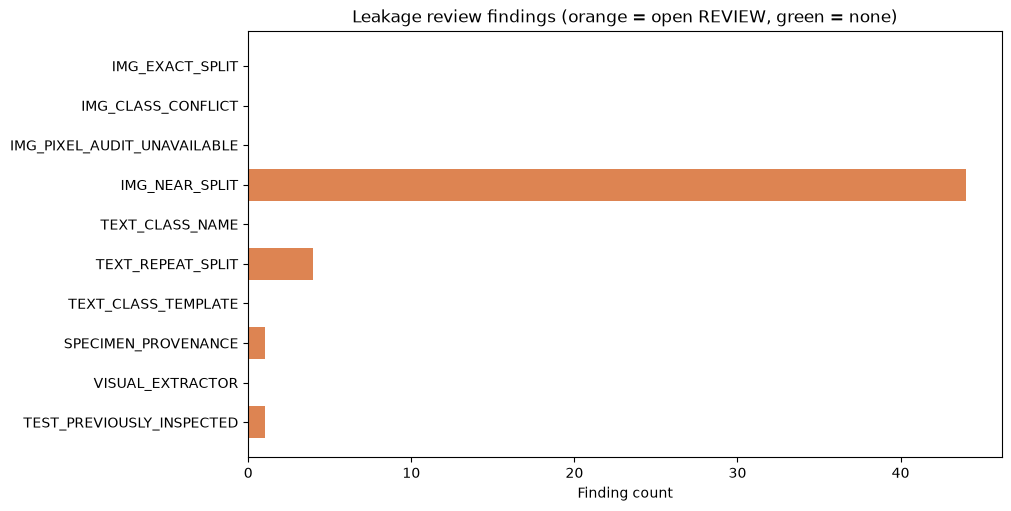

[SAVED] 218_leakage_review_findings.png
[SAVED] 687_review_findings_summary.csv
[SAVED] 688_review_text_label_clues.csv
[SAVED] 689_review_repeated_text_groups.csv
[SAVED] 690_review_exact_image_duplicates.csv
[SAVED] 691_review_near_duplicate_candidates.csv
[SAVED] 692_review_class_text_statistics.csv
[SAVED] 693_review_group_provenance.csv
[SAVED] 695_review_decisions_snapshot.csv
[SAVED] 696_review_integrity_checks.csv
[SAVED] 697_leakage_review_handoff.json

CELL 11 COMPLETED | decisions must be entered by a human reviewer.


In [12]:
# ============================================================
# CELL 11 - LEAKAGE REVIEW & EVIDENCE PACK
# ============================================================
# Builds the evidence pack and the MANUAL review templates.
# Manual files live OUTSIDE the run folders so that human decisions
# persist across runs:   results/reviews/retrieval_evaluation/
#   695_review_decisions.csv            (one row per open issue)
#   699_near_duplicate_pair_decisions.csv (one row per cross-split pair)
# Existing human entries are never overwritten; new rows are appended.
# The notebook never fills in a decision by itself.

assert globals().get("EVAL06_PRETEST_GATE_COMPLETED") is True, "Jalankan Cell 10 terlebih dahulu."

EVAL06_LEAKAGE_REVIEW_COMPLETED = False
print("NOTEBOOK 06 - CELL 11: LEAKAGE REVIEW & EVIDENCE PACK")
print("=" * 75)

EVAL06_REVIEW_DECISIONS_PATH = EVAL06_REVIEW_DIR / "695_review_decisions.csv"
EVAL06_PAIR_DECISIONS_PATH = EVAL06_REVIEW_DIR / "699_near_duplicate_pair_decisions.csv"
EVAL06_SIGNOFF_PATH = EVAL06_REVIEW_DIR / "705_final_pretest_signoff.csv"

image_audit_complete = EVAL06_IMAGE_HASH_SOURCE == "processed_images_recomputed"
findings = [
    ("IMG_EXACT_SPLIT", "BLOCK", len(EVAL06_CROSS_SPLIT_EXACT_IMAGES_DF), "623/690",
     "Group exact duplicates and rebuild the split."),
    ("IMG_CLASS_CONFLICT", "BLOCK", EVAL06_CROSS_CLASS_IMAGE_COLLISIONS, "690",
     "Resolve conflicting labels on identical images."),
    ("IMG_PIXEL_AUDIT_UNAVAILABLE", "REVIEW", int(not image_audit_complete), "608",
     "Run the notebook where dataset/processed/images is available."),
    ("IMG_NEAR_SPLIT", "REVIEW", EVAL06_CROSS_SPLIT_NEAR_DUPLICATES, "691",
     "Inspect each cross-split pair; mark CONFIRMED_SAME / CONFIRMED_DISTINCT in 699."),
    ("TEXT_CLASS_NAME", "REVIEW", EVAL06_LABEL_MENTION_COUNT, "688",
     "Remove or mask class names in descriptions."),
    ("TEXT_REPEAT_SPLIT", "REVIEW", EVAL06_CROSS_SPLIT_TEXT_GROUPS, "689",
     "Review identical descriptions shared across partitions."),
    ("TEXT_CLASS_TEMPLATE", "REVIEW", EVAL06_CLASS_TEMPLATE_COUNT, "692",
     "Document class-level description templates."),
    ("SPECIMEN_PROVENANCE", "REVIEW", int(EVAL06_GROUP_COLUMN is None), "693",
     "Verify specimen/capture identity (which photos come from the same leaf/plant)."),
    ("VISUAL_EXTRACTOR", "REVIEW", 0, "630/634",
     "Resolved technically in Cell 4 (NB03 manifest SHA-256, exact concatenation, normalizer reproduction)."),
    ("TEST_PREVIOUSLY_INSPECTED", "REVIEW", int(EVAL06_TEST_PREVIOUSLY_INSPECTED), "registry",
     "Cannot be undone; must be disclosed. Test can never be an independent estimate for this split."),
]
EVAL06_REVIEW_FINDINGS_DF = pd.DataFrame(findings, columns=["issue_id", "severity", "finding_count",
                                                            "evidence_file", "recommended_action"])
EVAL06_REVIEW_FINDINGS_DF["open"] = EVAL06_REVIEW_FINDINGS_DF["finding_count"] > 0

# ------------------------------------------------------------
# Evidence tables
# ------------------------------------------------------------
EVAL06_REVIEW_TEXT_CLUES_DF = EVAL06_TEXT_AUDIT_DF.loc[
    EVAL06_TEXT_AUDIT_DF["own_class_name_mentioned"] | EVAL06_TEXT_AUDIT_DF["any_class_alias_mentioned"],
    ["sample_id", "class_label", "normalized_text"]]
EVAL06_REVIEW_REPEATED_TEXT_DF = EVAL06_SPLIT_REPEATED_TEXT_DF.copy()
EVAL06_REVIEW_EXACT_IMAGES_DF = EVAL06_DUPLICATE_FINDINGS_DF.loc[
    EVAL06_DUPLICATE_FINDINGS_DF["duplicate_type"] != "exact_normalized_text"]
EVAL06_REVIEW_NEAR_DUPLICATES_DF = EVAL06_SPLIT_NEAR_DUPLICATE_REVIEW_DF.copy()
EVAL06_REVIEW_NEAR_DUPLICATES_DF["pair_key"] = [
    "||".join(sorted((a, b))) for a, b in zip(EVAL06_REVIEW_NEAR_DUPLICATES_DF["sample_id_i"],
                                              EVAL06_REVIEW_NEAR_DUPLICATES_DF["sample_id_j"])]
EVAL06_REVIEW_NEAR_DUPLICATES_DF = EVAL06_REVIEW_NEAR_DUPLICATES_DF.sort_values(
    ["cross_split", "dhash_hamming_distance"], ascending=[False, True]).reset_index(drop=True)
EVAL06_REVIEW_CLASS_TEXT_DF = EVAL06_CLASS_TEXT_AUDIT_DF.copy()
EVAL06_REVIEW_GROUP_PROVENANCE_DF = EVAL06_SPLIT_ASSIGNMENTS_DF.merge(
    EVAL06_AUDIT_DATA_DF[["sample_id", "nama_file", "tampilan_daun", "processed_image_path"]], on="sample_id")
EVAL06_REVIEW_GROUP_PROVENANCE_DF["declared_specimen_id"] = (
    EVAL06_AUDIT_DATA_DF[EVAL06_GROUP_COLUMN].tolist() if EVAL06_GROUP_COLUMN else "")

# ------------------------------------------------------------
# Manual review templates (persistent, never overwritten)
# ------------------------------------------------------------
EVAL06_REVIEW_COLUMNS = ["issue_id", "review_status", "reviewer_notes", "supporting_evidence"]
EVAL06_PAIR_COLUMNS = ["pair_key", "sample_id_i", "sample_id_j", "split_i", "split_j",
                       "dhash_hamming_distance", "review_status", "reviewer_notes", "supporting_evidence"]


def eval06_load_or_seed(path, key, columns, required_keys, seed_rows, legacy_name):
    """Keep existing human rows; append missing keys; seed notes from legacy file once."""
    seeded_from_legacy = False
    if path.is_file():
        table = pd.read_csv(path, dtype=str, keep_default_na=False, encoding="utf-8-sig")
    else:
        table = pd.DataFrame(columns=columns)
        legacy = EVAL06_LEGACY_METRICS_DIR / legacy_name
        if legacy.is_file():
            old = pd.read_csv(legacy, dtype=str, keep_default_na=False, encoding="utf-8-sig")
            if key in old.columns:
                keep = [c for c in columns if c in old.columns]
                old = old.loc[old[key].isin(required_keys), keep]
                human = old.get("reviewer_notes", pd.Series("", index=old.index)).map(eval06_clean_str).ne("") | \
                    old.get("review_status", pd.Series("", index=old.index)).str.upper().ne("PENDING")
                table = old.loc[human].reindex(columns=columns, fill_value="")
                seeded_from_legacy = bool(len(table))
    for column in columns:
        if column not in table.columns:
            table[column] = ""
    missing = [k for k in required_keys if k not in set(table[key])]
    if missing:
        table = pd.concat([table[columns], pd.DataFrame([seed_rows[k] for k in missing])[columns]], ignore_index=True)
    table[columns].to_csv(path, index=False, encoding="utf-8-sig")
    return table[columns], seeded_from_legacy, len(missing)


open_issue_ids = EVAL06_REVIEW_FINDINGS_DF.loc[EVAL06_REVIEW_FINDINGS_DF["open"], "issue_id"].tolist()
review_seed = {i: {"issue_id": i, "review_status": "PENDING", "reviewer_notes": "", "supporting_evidence": ""}
               for i in open_issue_ids}
EVAL06_REVIEW_DECISIONS_DF, review_from_legacy, review_added = eval06_load_or_seed(
    EVAL06_REVIEW_DECISIONS_PATH, "issue_id", EVAL06_REVIEW_COLUMNS, open_issue_ids, review_seed,
    "695_review_decision_template.csv")

cross_pairs = EVAL06_REVIEW_NEAR_DUPLICATES_DF.loc[EVAL06_REVIEW_NEAR_DUPLICATES_DF["cross_split"]]
pair_seed = {r.pair_key: {"pair_key": r.pair_key, "sample_id_i": r.sample_id_i, "sample_id_j": r.sample_id_j,
                          "split_i": r.split_i, "split_j": r.split_j,
                          "dhash_hamming_distance": r.dhash_hamming_distance,
                          "review_status": "PENDING", "reviewer_notes": "", "supporting_evidence": ""}
             for r in cross_pairs.itertuples(index=False)}
EVAL06_PAIR_DECISIONS_DF, pairs_from_legacy, pairs_added = eval06_load_or_seed(
    EVAL06_PAIR_DECISIONS_PATH, "pair_key", EVAL06_PAIR_COLUMNS, list(pair_seed), pair_seed,
    "699_near_duplicate_pair_decisions.csv")

EVAL06_REVIEW_CHECKS_DF = pd.DataFrame([
    {"check": "Every open issue has a review row",
     "passed": set(open_issue_ids) <= set(EVAL06_REVIEW_DECISIONS_DF["issue_id"])},
    {"check": "Every cross-split pair has a decision row",
     "passed": set(pair_seed) <= set(EVAL06_PAIR_DECISIONS_DF["pair_key"])},
    {"check": "No duplicate pair keys in 699", "passed": EVAL06_PAIR_DECISIONS_DF["pair_key"].is_unique},
    {"check": "No duplicate issue IDs in 695", "passed": EVAL06_REVIEW_DECISIONS_DF["issue_id"].is_unique},
    {"check": "Selection lock unchanged", "passed": eval06_sha256_file(EVAL06_SELECTION_LOCK_PATH) == EVAL06_SELECTION_LOCK_SHA256},
])

print("\n1. FINDINGS")
print("-" * 75)
display(EVAL06_REVIEW_FINDINGS_DF)
print("\n2. MANUAL REVIEW FILES (persistent)")
print("-" * 75)
print("Issue decisions :", EVAL06_REVIEW_DECISIONS_PATH, f"(rows={len(EVAL06_REVIEW_DECISIONS_DF)}, added={review_added})")
print("Pair decisions  :", EVAL06_PAIR_DECISIONS_PATH, f"(rows={len(EVAL06_PAIR_DECISIONS_DF)}, added={pairs_added})")
print("Seeded with human notes from legacy files:", review_from_legacy or pairs_from_legacy)
print("Cross-split near-duplicate pairs to review:", len(cross_pairs))
display(cross_pairs[["sample_id_i", "sample_id_j", "class_i", "class_j", "split_i", "split_j",
                     "dhash_hamming_distance"]].head(15))
display(EVAL06_REVIEW_CHECKS_DF)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
colors = ["#C44E52" if (o and s == "BLOCK") else "#DD8452" if o else "#55A868"
          for o, s in zip(EVAL06_REVIEW_FINDINGS_DF["open"], EVAL06_REVIEW_FINDINGS_DF["severity"])]
ax.barh(EVAL06_REVIEW_FINDINGS_DF["issue_id"], EVAL06_REVIEW_FINDINGS_DF["finding_count"], color=colors)
ax.invert_yaxis()
ax.set(title="Leakage review findings (orange = open REVIEW, green = none)", xlabel="Finding count")
eval06_save_figure(fig, "218_leakage_review_findings.png", 11)

eval06_save_csv(EVAL06_REVIEW_FINDINGS_DF, "687_review_findings_summary.csv", 11)
eval06_save_csv(EVAL06_REVIEW_TEXT_CLUES_DF, "688_review_text_label_clues.csv", 11)
eval06_save_csv(EVAL06_REVIEW_REPEATED_TEXT_DF, "689_review_repeated_text_groups.csv", 11)
eval06_save_csv(EVAL06_REVIEW_EXACT_IMAGES_DF, "690_review_exact_image_duplicates.csv", 11)
eval06_save_csv(EVAL06_REVIEW_NEAR_DUPLICATES_DF, "691_review_near_duplicate_candidates.csv", 11)
eval06_save_csv(EVAL06_REVIEW_CLASS_TEXT_DF, "692_review_class_text_statistics.csv", 11)
eval06_save_csv(EVAL06_REVIEW_GROUP_PROVENANCE_DF, "693_review_group_provenance.csv", 11)
eval06_save_csv(EVAL06_REVIEW_DECISIONS_DF, "695_review_decisions_snapshot.csv", 11)
eval06_save_csv(EVAL06_REVIEW_CHECKS_DF, "696_review_integrity_checks.csv", 11)
eval06_save_json({"cell": 11, "open_issues": open_issue_ids, "review_dir": str(EVAL06_REVIEW_DIR),
                  "cross_split_pairs": int(len(cross_pairs)), "decisions_auto_filled": False},
                 "697_leakage_review_handoff.json", 11)

assert EVAL06_REVIEW_CHECKS_DF["passed"].all(), EVAL06_REVIEW_CHECKS_DF.to_string(index=False)
EVAL06_LEAKAGE_REVIEW_COMPLETED = True
print("\nCELL 11 COMPLETED | decisions must be entered by a human reviewer.")

## Cell 12 — Leakage Resolution

NOTEBOOK 06 - CELL 12: LEAKAGE RESOLUTION

1. RESOLUTION MATRIX
---------------------------------------------------------------------------


,issue_id,finding_count,review_status,resolution_state,required_action
0,IMG_EXACT_SPLIT,0,PENDING,NOT_APPLICABLE,NONE
1,IMG_CLASS_CONFLICT,0,PENDING,NOT_APPLICABLE,NONE
2,IMG_PIXEL_AUDIT_UNAVAILABLE,0,PENDING,NOT_APPLICABLE,NONE
3,IMG_NEAR_SPLIT,44,PENDING,PENDING_PAIR_REVIEWS,COMPLETE_699
4,TEXT_CLASS_NAME,0,PENDING,NOT_APPLICABLE,NONE
5,TEXT_REPEAT_SPLIT,4,PENDING,PENDING_REVIEW,COMPLETE_695
6,TEXT_CLASS_TEMPLATE,0,PENDING,NOT_APPLICABLE,NONE
7,SPECIMEN_PROVENANCE,1,PENDING,PENDING_REVIEW,COMPLETE_695
8,VISUAL_EXTRACTOR,0,PENDING,NOT_APPLICABLE,NONE
9,TEST_PREVIOUSLY_INSPECTED,1,PENDING,PENDING_REVIEW,COMPLETE_695


Open substantive issues : 4
Open pair reviews       : 44 / 44
Data repair required    : False
Rerun with images needed: False


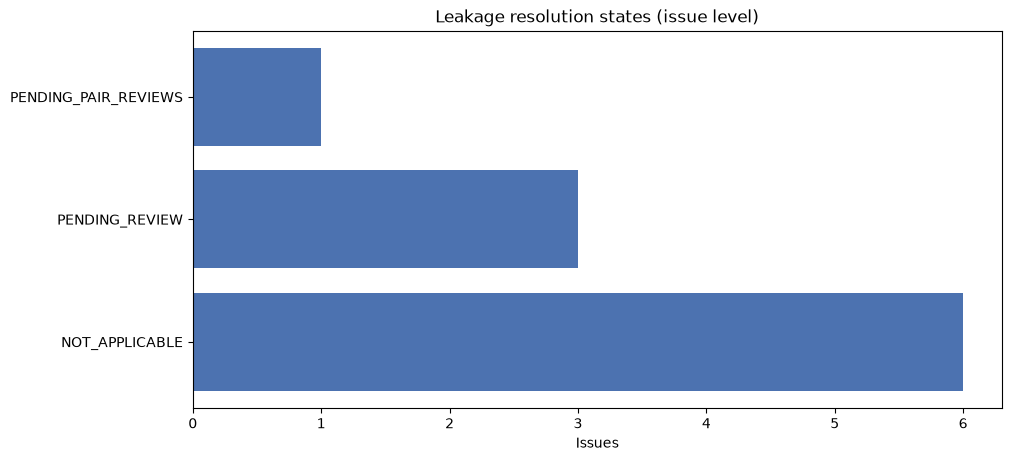

[SAVED] 219_leakage_resolution_status.png
[SAVED] 698_leakage_resolution_matrix.csv
[SAVED] 700_near_duplicate_pair_resolution.csv
[SAVED] 701_finalized_retrieval_protocol.csv
[SAVED] 704_resolution_protocol_handoff.json

CELL 12 COMPLETED


In [13]:
# ============================================================
# CELL 12 - LEAKAGE RESOLUTION & PROTOCOL FINALIZATION
# ============================================================
# Reads the human decisions from results/reviews/retrieval_evaluation/.
# Allowed issue statuses: PENDING, VERIFIED_NO_LEAKAGE, ACKNOWLEDGED_LIMITATION, NEEDS_REPAIR
# Allowed pair statuses : PENDING, INCONCLUSIVE, CONFIRMED_DISTINCT, CONFIRMED_SAME
# A non-PENDING decision only counts with notes (>= 20 chars) AND evidence.
# Bug fixed: blank/NaN cells are no longer read as the text "nan"
# (which previously counted as "evidence declared").

assert globals().get("EVAL06_LEAKAGE_REVIEW_COMPLETED") is True, "Jalankan Cell 11 terlebih dahulu."

EVAL06_LEAKAGE_RESOLUTION_COMPLETED = False
print("NOTEBOOK 06 - CELL 12: LEAKAGE RESOLUTION")
print("=" * 75)

ISSUE_STATUSES = {"PENDING", "VERIFIED_NO_LEAKAGE", "ACKNOWLEDGED_LIMITATION", "NEEDS_REPAIR"}
PAIR_STATUSES = {"PENDING", "INCONCLUSIVE", "CONFIRMED_DISTINCT", "CONFIRMED_SAME"}
NON_WAIVABLE = {"IMG_EXACT_SPLIT", "IMG_CLASS_CONFLICT", "IMG_PIXEL_AUDIT_UNAVAILABLE"}
LIMITATION_ONLY = {"TEST_PREVIOUSLY_INSPECTED"}
LIMITATION_ELIGIBLE = {"TEXT_CLASS_NAME", "TEXT_REPEAT_SPLIT", "TEXT_CLASS_TEMPLATE",
                       "SPECIMEN_PROVENANCE", "TEST_PREVIOUSLY_INSPECTED"}

decisions = pd.read_csv(EVAL06_REVIEW_DECISIONS_PATH, dtype=str, keep_default_na=False, encoding="utf-8-sig")
pair_reviews = pd.read_csv(EVAL06_PAIR_DECISIONS_PATH, dtype=str, keep_default_na=False, encoding="utf-8-sig")
if decisions["issue_id"].duplicated().any() or pair_reviews["pair_key"].duplicated().any():
    raise ValueError("Duplicate keys in manual review files 695/699.")
decision_map = decisions.set_index("issue_id")
pair_map = pair_reviews.set_index("pair_key")


def eval06_decision(table, key, statuses):
    if key not in table.index:
        return "PENDING", "", "", True
    r = table.loc[key]
    status = eval06_clean_str(r.get("review_status", "")).upper() or "PENDING"
    notes = eval06_clean_str(r.get("reviewer_notes", ""))
    evidence = eval06_clean_str(r.get("supporting_evidence", ""))
    return status, notes, evidence, status in statuses


# ------------------------------------------------------------
# 1. Pair-level near-duplicate decisions
# ------------------------------------------------------------
pair_rows = []
for r in cross_pairs.itertuples(index=False):
    status, notes, evidence, known = eval06_decision(pair_map, r.pair_key, PAIR_STATUSES)
    adequate = len(notes) >= 20 and bool(evidence)
    if not known:
        state = "INVALID_PAIR_STATUS"
    elif status == "CONFIRMED_SAME":
        state = "REPAIR_REQUIRED"
    elif status == "CONFIRMED_DISTINCT" and adequate:
        state = "EVIDENCE_SUBMITTED"
    elif status == "CONFIRMED_DISTINCT":
        state = "INSUFFICIENT_EVIDENCE"
    else:
        state = "AWAITING_PAIR_REVIEW"
    pair_rows.append({"pair_key": r.pair_key, "sample_id_i": r.sample_id_i, "sample_id_j": r.sample_id_j,
                      "split_i": r.split_i, "split_j": r.split_j, "dhash_hamming_distance": r.dhash_hamming_distance,
                      "review_status": status, "resolution_state": state,
                      "reviewer_notes": notes, "supporting_evidence": evidence})
EVAL06_PAIR_RESOLUTION_DF = pd.DataFrame(pair_rows, columns=[
    "pair_key", "sample_id_i", "sample_id_j", "split_i", "split_j", "dhash_hamming_distance",
    "review_status", "resolution_state", "reviewer_notes", "supporting_evidence"])
EVAL06_OPEN_PAIR_REVIEWS = int((EVAL06_PAIR_RESOLUTION_DF["resolution_state"] != "EVIDENCE_SUBMITTED").sum())
EVAL06_PAIRS_REQUIRING_REPAIR = int((EVAL06_PAIR_RESOLUTION_DF["resolution_state"] == "REPAIR_REQUIRED").sum())

# ------------------------------------------------------------
# 2. Issue-level resolution matrix
# ------------------------------------------------------------
resolution_rows = []
for f in EVAL06_REVIEW_FINDINGS_DF.to_dict("records"):
    issue = f["issue_id"]
    status, notes, evidence, known = eval06_decision(decision_map, issue, ISSUE_STATUSES)
    complete = len(notes) >= 20 and bool(evidence)
    if not f["open"]:
        state, action = "NOT_APPLICABLE", "NONE"
    elif issue == "IMG_PIXEL_AUDIT_UNAVAILABLE":
        state, action = "REQUIRES_RERUN_WITH_IMAGES", "RERUN_WHERE_PROCESSED_IMAGES_EXIST"
    elif issue in NON_WAIVABLE:
        state, action = "REQUIRES_UPSTREAM_REPAIR", "REPAIR_DATA_AND_RERUN"
    elif not known:
        state, action = "INVALID_REVIEW_STATUS", "CORRECT_695"
    elif status == "NEEDS_REPAIR":
        state, action = "REQUIRES_UPSTREAM_REPAIR", "REBUILD_AND_RERUN"
    elif issue == "IMG_NEAR_SPLIT" and EVAL06_PAIRS_REQUIRING_REPAIR:
        state, action = "REQUIRES_UPSTREAM_REPAIR", "REGROUP_CONFIRMED_SAME_PAIRS"
    elif issue == "IMG_NEAR_SPLIT" and EVAL06_OPEN_PAIR_REVIEWS:
        state, action = "PENDING_PAIR_REVIEWS", "COMPLETE_699"
    elif status == "PENDING":
        state, action = "PENDING_REVIEW", "COMPLETE_695"
    elif not complete:
        state, action = "INSUFFICIENT_EVIDENCE", "ADD_NOTES_AND_EVIDENCE"
    elif status == "ACKNOWLEDGED_LIMITATION":
        if issue in LIMITATION_ELIGIBLE:
            state, action = "LIMITATION_DOCUMENTED", "QUALIFY_CLAIMS"
        else:
            state, action = "INVALID_LIMITATION_WAIVER", "REVIEW_AS_DISTINCT_OR_REPAIR"
    elif issue in LIMITATION_ONLY:
        state, action = "INVALID_STATUS_FOR_ISSUE", "USE_ACKNOWLEDGED_LIMITATION"
    else:
        state, action = "EVIDENCE_SUBMITTED", "HUMAN_ATTESTED_NOT_NOTEBOOK_VERIFIED"
    resolution_rows.append({"issue_id": issue, "severity": f["severity"], "finding_count": f["finding_count"],
                            "review_status": status, "resolution_state": state, "required_action": action,
                            "notes_complete": len(notes) >= 20, "evidence_declared": bool(evidence),
                            "reviewer_notes": notes, "supporting_evidence": evidence})
EVAL06_RESOLUTION_MATRIX_DF = pd.DataFrame(resolution_rows)

ACCEPTED_STATES = {"NOT_APPLICABLE", "EVIDENCE_SUBMITTED", "LIMITATION_DOCUMENTED"}
EVAL06_OPEN_SUBSTANTIVE_ISSUES = int((~EVAL06_RESOLUTION_MATRIX_DF["resolution_state"].isin(ACCEPTED_STATES)).sum())
EVAL06_REPAIR_REQUIRED = bool(EVAL06_RESOLUTION_MATRIX_DF["resolution_state"].eq("REQUIRES_UPSTREAM_REPAIR").any())
EVAL06_RERUN_WITH_IMAGES_REQUIRED = bool(EVAL06_RESOLUTION_MATRIX_DF["resolution_state"].eq("REQUIRES_RERUN_WITH_IMAGES").any())
EVAL06_LIMITATIONS_DOCUMENTED = EVAL06_RESOLUTION_MATRIX_DF.loc[
    EVAL06_RESOLUTION_MATRIX_DF["resolution_state"] == "LIMITATION_DOCUMENTED", "issue_id"].tolist()

EVAL06_PROTOCOL_DECISIONS_DF = pd.DataFrame([
    ("Data partition", "Gallery/validation/test split frozen (seed 42, group-aware)",
     "Rebuild all downstream outputs if confirmed duplicates require regrouping"),
    ("Visual features", "Notebook 03 143-D vectors, NB03 normalizer fitted on gallery", "No alternative extractor"),
    ("Text features", "cleaned_description, TF-IDF fitted on gallery", "Full-dataset NB02 TF-IDF not used"),
    ("Selection", f"{EVAL06_SELECTED_TEXT_CONFIG}, alpha={EVAL06_SELECTED_ALPHA} (validation mAP@5)",
     "Test may not change alpha / TF-IDF / features"),
    ("Test reporting", "Status label depends on Cell 13 gate", "Previously inspected test is never 'independent'"),
], columns=["protocol_area", "decision", "constraint"])

print("\n1. RESOLUTION MATRIX")
print("-" * 75)
display(EVAL06_RESOLUTION_MATRIX_DF[["issue_id", "finding_count", "review_status", "resolution_state", "required_action"]])
print("Open substantive issues :", EVAL06_OPEN_SUBSTANTIVE_ISSUES)
print("Open pair reviews       :", EVAL06_OPEN_PAIR_REVIEWS, "/", len(EVAL06_PAIR_RESOLUTION_DF))
print("Data repair required    :", EVAL06_REPAIR_REQUIRED)
print("Rerun with images needed:", EVAL06_RERUN_WITH_IMAGES_REQUIRED)

fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
state_counts = EVAL06_RESOLUTION_MATRIX_DF["resolution_state"].value_counts()
ax.barh(state_counts.index, state_counts.values, color="#4C72B0")
ax.set(title="Leakage resolution states (issue level)", xlabel="Issues")
eval06_save_figure(fig, "219_leakage_resolution_status.png", 12)

eval06_save_csv(EVAL06_RESOLUTION_MATRIX_DF, "698_leakage_resolution_matrix.csv", 12)
eval06_save_csv(EVAL06_PAIR_RESOLUTION_DF, "700_near_duplicate_pair_resolution.csv", 12)
eval06_save_csv(EVAL06_PROTOCOL_DECISIONS_DF, "701_finalized_retrieval_protocol.csv", 12)
eval06_save_json({"cell": 12, "open_substantive_issues": EVAL06_OPEN_SUBSTANTIVE_ISSUES,
                  "open_pair_reviews": EVAL06_OPEN_PAIR_REVIEWS, "repair_required": EVAL06_REPAIR_REQUIRED,
                  "rerun_with_images_required": EVAL06_RERUN_WITH_IMAGES_REQUIRED,
                  "limitations_documented": EVAL06_LIMITATIONS_DOCUMENTED,
                  "selection_lock_sha256": EVAL06_SELECTION_LOCK_SHA256}, "704_resolution_protocol_handoff.json", 12)

EVAL06_LEAKAGE_RESOLUTION_COMPLETED = True
print("\nCELL 12 COMPLETED")

## Cell 13 — Final Pre-Test Readiness & status test
Untuk persetujuan formal, reviewer mengisi `results/reviews/retrieval_evaluation/705_final_pretest_signoff.csv` secara manual, lalu menjalankan ulang notebook.

NOTEBOOK 06 - CELL 13: FINAL PRE-TEST READINESS
[CREATED] Sign-off template: D:\Project\Multimodal_Leaf_Retrieval\results\reviews\retrieval_evaluation\705_final_pretest_signoff.csv


,category,validation_check,passed,severity_if_failed,detail
0,Lock,Selected configuration unchanged,True,BLOCK,
1,Lock,Lock file SHA-256 unchanged,True,BLOCK,
2,Data,Cell 10 structural integrity passed,True,BLOCK,
3,Review,No data repair required,True,REVIEW,
4,Review,All substantive findings have accepted disposi...,False,REVIEW,open=4
5,Review,All cross-split near-duplicate pairs reviewed ...,False,REVIEW,open=44
6,Signoff,Sign-off refers to the current selection lock,True,REVIEW,
7,Signoff,"Reviewer name, ISO date and notes recorded",False,REVIEW,
8,Signoff,All attestations = YES,False,REVIEW,
9,Signoff,Decision APPROVE with exact authorization phrase,False,REVIEW,decision=PENDING


,0
gate_status,HOLD_UNRESOLVED_REVIEW
test_evaluation_status,PROVISIONAL_AUDIT_UNRESOLVED
recorded_reviewer_decision,PENDING
human_approval_valid,False
test_previously_inspected,True
selected_text_configuration,Unigram + Bigram
selected_alpha,0.3
open_substantive_issues,4
open_pair_reviews,44
sample_count,104


TEST STATUS: PROVISIONAL_AUDIT_UNRESOLVED
Independent test estimate: False


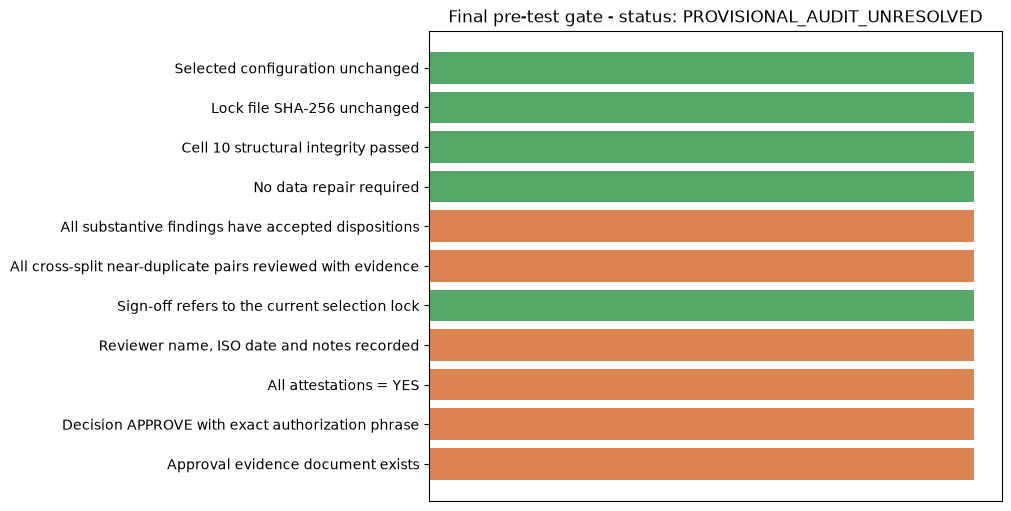

[SAVED] 220_final_pretest_gate_checks.png
[SAVED] 705_final_pretest_signoff_snapshot.csv
[SAVED] 706_final_pretest_gate_checks.csv
[SAVED] 707_final_pretest_evidence_manifest.csv
[SAVED] 708_final_pretest_readiness_summary.csv
[SAVED] 709_final_pretest_approval_handoff.json

CELL 13 COMPLETED


In [14]:
# ============================================================
# CELL 13 - FINAL PRE-TEST READINESS & TEST STATUS
# ============================================================
# Human sign-off file (persistent, never auto-filled):
#   results/reviews/retrieval_evaluation/705_final_pretest_signoff.csv
# Approval requires: decision APPROVE, reviewer name, ISO date, notes,
# the CURRENT selection-lock SHA-256, all attestations = YES, the exact
# phrase I_APPROVE_LOCKED_VALIDATION_PROTOCOL_FOR_TEST and an existing
# evidence document. Even then, because the test partition was inspected
# in earlier runs, the strongest attainable label is
# SIGNED_OFF_TEST_PREVIOUSLY_INSPECTED (never "independent").

assert globals().get("EVAL06_LEAKAGE_RESOLUTION_COMPLETED") is True, "Jalankan Cell 12 terlebih dahulu."

EVAL06_FINAL_PRETEST_COMPLETED = False
eval06_final_checks = []
print("NOTEBOOK 06 - CELL 13: FINAL PRE-TEST READINESS")
print("=" * 75)

SIGNOFF_COLUMNS = ["approval_decision", "reviewer_name", "review_date", "review_notes", "selection_lock_sha256",
                   "specimen_provenance_verified", "cross_split_duplicate_review_completed",
                   "text_leakage_limitations_disclosed", "test_prior_inspection_disclosed",
                   "authorization_phrase", "approval_evidence_path"]
ATTESTATIONS = ["specimen_provenance_verified", "cross_split_duplicate_review_completed",
                "text_leakage_limitations_disclosed", "test_prior_inspection_disclosed"]
AUTH_PHRASE = "I_APPROVE_LOCKED_VALIDATION_PROTOCOL_FOR_TEST"

blank_signoff = {"approval_decision": "PENDING", "reviewer_name": "", "review_date": "", "review_notes": "",
                 "selection_lock_sha256": EVAL06_SELECTION_LOCK_SHA256, **{a: "NO" for a in ATTESTATIONS},
                 "authorization_phrase": "", "approval_evidence_path": ""}
if EVAL06_SIGNOFF_PATH.is_file():
    signoff = pd.read_csv(EVAL06_SIGNOFF_PATH, dtype=str, keep_default_na=False, encoding="utf-8-sig")
    for column in SIGNOFF_COLUMNS:
        if column not in signoff.columns:
            signoff[column] = blank_signoff[column]
    record = signoff.iloc[0].to_dict()
    untouched = (eval06_clean_str(record["approval_decision"]).upper() in ("", "PENDING")
                 and not any(eval06_clean_str(record[c]) for c in ("reviewer_name", "review_date", "review_notes",
                                                                    "authorization_phrase", "approval_evidence_path")))
    if untouched and record["selection_lock_sha256"] != EVAL06_SELECTION_LOCK_SHA256:
        record["selection_lock_sha256"] = EVAL06_SELECTION_LOCK_SHA256   # refresh empty template only
        pd.DataFrame([record])[SIGNOFF_COLUMNS].to_csv(EVAL06_SIGNOFF_PATH, index=False, encoding="utf-8-sig")
        print("[INFO] Empty sign-off template refreshed with the current selection-lock hash.")
else:
    record = dict(blank_signoff)
    pd.DataFrame([record])[SIGNOFF_COLUMNS].to_csv(EVAL06_SIGNOFF_PATH, index=False, encoding="utf-8-sig")
    print("[CREATED] Sign-off template:", EVAL06_SIGNOFF_PATH)

decision = eval06_clean_str(record["approval_decision"]).upper() or "PENDING"
if decision not in {"PENDING", "APPROVE", "REJECT", "REQUEST_REPAIR"}:
    raise ValueError("approval_decision harus PENDING / APPROVE / REJECT / REQUEST_REPAIR.")
try:
    review_date_ok = bool(datetime.strptime(eval06_clean_str(record["review_date"]), "%Y-%m-%d"))
except ValueError:
    review_date_ok = False
evidence_value = eval06_clean_str(record["approval_evidence_path"])
evidence_path = (EVAL06_PROJECT_ROOT / evidence_value) if evidence_value and not Path(evidence_value).is_absolute() \
    else Path(evidence_value) if evidence_value else None

eval06_check(eval06_final_checks, "Lock", "Selected configuration unchanged",
             EVAL06_SELECTION_LOCK["selected_text_configuration"] == EVAL06_SELECTED_TEXT_CONFIG
             and EVAL06_SELECTION_LOCK["selected_alpha"] == EVAL06_SELECTED_ALPHA)
eval06_check(eval06_final_checks, "Lock", "Lock file SHA-256 unchanged",
             eval06_sha256_file(EVAL06_SELECTION_LOCK_PATH) == EVAL06_SELECTION_LOCK_SHA256)
eval06_check(eval06_final_checks, "Data", "Cell 10 structural integrity passed", EVAL06_PRETEST_STRUCTURAL_OK)
eval06_check(eval06_final_checks, "Review", "No data repair required", not EVAL06_REPAIR_REQUIRED, severity="REVIEW")
eval06_check(eval06_final_checks, "Review", "All substantive findings have accepted dispositions",
             EVAL06_OPEN_SUBSTANTIVE_ISSUES == 0, detail=f"open={EVAL06_OPEN_SUBSTANTIVE_ISSUES}", severity="REVIEW")
eval06_check(eval06_final_checks, "Review", "All cross-split near-duplicate pairs reviewed with evidence",
             EVAL06_OPEN_PAIR_REVIEWS == 0, detail=f"open={EVAL06_OPEN_PAIR_REVIEWS}", severity="REVIEW")
eval06_check(eval06_final_checks, "Signoff", "Sign-off refers to the current selection lock",
             record["selection_lock_sha256"] == EVAL06_SELECTION_LOCK_SHA256, severity="REVIEW")
eval06_check(eval06_final_checks, "Signoff", "Reviewer name, ISO date and notes recorded",
             bool(eval06_clean_str(record["reviewer_name"])) and review_date_ok
             and len(eval06_clean_str(record["review_notes"])) >= 20, severity="REVIEW")
eval06_check(eval06_final_checks, "Signoff", "All attestations = YES",
             all(eval06_clean_str(record[a]).upper() == "YES" for a in ATTESTATIONS), severity="REVIEW")
eval06_check(eval06_final_checks, "Signoff", "Decision APPROVE with exact authorization phrase",
             decision == "APPROVE" and eval06_clean_str(record["authorization_phrase"]) == AUTH_PHRASE,
             detail=f"decision={decision}", severity="REVIEW")
eval06_check(eval06_final_checks, "Signoff", "Approval evidence document exists",
             evidence_path is not None and evidence_path.is_file(), severity="REVIEW")
EVAL06_FINAL_PRETEST_CHECKS_DF = eval06_checks_frame(eval06_final_checks)
eval06_require(EVAL06_FINAL_PRETEST_CHECKS_DF, "Cell 13")

EVAL06_HUMAN_APPROVAL_VALID = bool(EVAL06_FINAL_PRETEST_CHECKS_DF["passed"].all())
if EVAL06_HUMAN_APPROVAL_VALID and not EVAL06_TEST_PREVIOUSLY_INSPECTED:
    EVAL06_TEST_EVALUATION_STATUS = EVAL06_STATUS_INDEPENDENT
elif EVAL06_HUMAN_APPROVAL_VALID:
    EVAL06_TEST_EVALUATION_STATUS = EVAL06_STATUS_SIGNED_NOT_INDEPENDENT
else:
    EVAL06_TEST_EVALUATION_STATUS = EVAL06_STATUS_PROVISIONAL
EVAL06_TEST_IS_INDEPENDENT_ESTIMATE = EVAL06_TEST_EVALUATION_STATUS == EVAL06_STATUS_INDEPENDENT
EVAL06_TEST_FILE_SUFFIX = {EVAL06_STATUS_INDEPENDENT: "",
                           EVAL06_STATUS_SIGNED_NOT_INDEPENDENT: "_SIGNED_NOT_INDEPENDENT",
                           EVAL06_STATUS_PROVISIONAL: "_PROVISIONAL"}[EVAL06_TEST_EVALUATION_STATUS]
EVAL06_GATE_STATUS = ("REPAIR_REQUIRED" if EVAL06_REPAIR_REQUIRED else
                      "HUMAN_SIGNOFF_RECORDED" if EVAL06_HUMAN_APPROVAL_VALID else "HOLD_UNRESOLVED_REVIEW")

EVAL06_FINAL_PRETEST_SUMMARY_DF = pd.DataFrame([{
    "gate_status": EVAL06_GATE_STATUS, "test_evaluation_status": EVAL06_TEST_EVALUATION_STATUS,
    "recorded_reviewer_decision": decision, "human_approval_valid": EVAL06_HUMAN_APPROVAL_VALID,
    "test_previously_inspected": EVAL06_TEST_PREVIOUSLY_INSPECTED,
    "selected_text_configuration": EVAL06_SELECTED_TEXT_CONFIG, "selected_alpha": EVAL06_SELECTED_ALPHA,
    "open_substantive_issues": EVAL06_OPEN_SUBSTANTIVE_ISSUES, "open_pair_reviews": EVAL06_OPEN_PAIR_REVIEWS,
    "sample_count": EVAL06_N_SAMPLES, **{f"{s}_count": len(EVAL06_SPLIT_SAMPLE_IDS[s]) for s in EVAL06_SPLIT_NAMES}}])
EVAL06_EVIDENCE_MANIFEST_DF = pd.DataFrame([
    {"evidence": "Selection lock", "path": str(EVAL06_SELECTION_LOCK_PATH), "sha256": EVAL06_SELECTION_LOCK_SHA256},
    {"evidence": "Issue decisions 695", "path": str(EVAL06_REVIEW_DECISIONS_PATH), "sha256": eval06_sha256_file(EVAL06_REVIEW_DECISIONS_PATH)},
    {"evidence": "Pair decisions 699", "path": str(EVAL06_PAIR_DECISIONS_PATH), "sha256": eval06_sha256_file(EVAL06_PAIR_DECISIONS_PATH)},
    {"evidence": "Sign-off 705", "path": str(EVAL06_SIGNOFF_PATH), "sha256": eval06_sha256_file(EVAL06_SIGNOFF_PATH)},
])

display(EVAL06_FINAL_PRETEST_CHECKS_DF)
display(EVAL06_FINAL_PRETEST_SUMMARY_DF.T)
print("TEST STATUS:", EVAL06_TEST_EVALUATION_STATUS)
print("Independent test estimate:", EVAL06_TEST_IS_INDEPENDENT_ESTIMATE)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
colors = ["#55A868" if p else ("#C44E52" if s == "BLOCK" else "#DD8452")
          for p, s in zip(EVAL06_FINAL_PRETEST_CHECKS_DF["passed"], EVAL06_FINAL_PRETEST_CHECKS_DF["severity_if_failed"])]
ax.barh(EVAL06_FINAL_PRETEST_CHECKS_DF["validation_check"], 1, color=colors)
ax.invert_yaxis()
ax.set(xticks=[], title=f"Final pre-test gate - status: {EVAL06_TEST_EVALUATION_STATUS}")
eval06_save_figure(fig, "220_final_pretest_gate_checks.png", 13)

eval06_save_csv(pd.DataFrame([record])[SIGNOFF_COLUMNS], "705_final_pretest_signoff_snapshot.csv", 13)
eval06_save_csv(EVAL06_FINAL_PRETEST_CHECKS_DF, "706_final_pretest_gate_checks.csv", 13)
eval06_save_csv(EVAL06_EVIDENCE_MANIFEST_DF, "707_final_pretest_evidence_manifest.csv", 13)
eval06_save_csv(EVAL06_FINAL_PRETEST_SUMMARY_DF, "708_final_pretest_readiness_summary.csv", 13)
eval06_save_json({"cell": 13, "gate_status": EVAL06_GATE_STATUS, "test_evaluation_status": EVAL06_TEST_EVALUATION_STATUS,
                  "independent_estimate": EVAL06_TEST_IS_INDEPENDENT_ESTIMATE,
                  "approval_type": "recorded_human_signoff" if EVAL06_HUMAN_APPROVAL_VALID else "none",
                  "approval_fabricated_by_notebook": False,
                  "selection_lock_sha256": EVAL06_SELECTION_LOCK_SHA256}, "709_final_pretest_approval_handoff.json", 13)

EVAL06_FINAL_PRETEST_COMPLETED = True
print("\nCELL 13 COMPLETED")

## Cell 14 — Frozen Test Retrieval Ranking
Satu implementasi (menggantikan dua versi Cell 14 lama).

In [15]:
# ============================================================
# CELL 14 - FROZEN TEST RETRIEVAL RANKING  (single implementation)
# ============================================================
# Replaces BOTH former Cell 14 versions (approval-gate version and
# provisional version). The configuration comes exclusively from the
# selection lock. Results are written into this run's own folder, so a
# changed fingerprint never conflicts with older runs (fixes the former
# "RuntimeError: Ranking test lama memakai input berbeda").
# Baselines (Visual Only, Text Only) are ranked for REPORTING only.

assert globals().get("EVAL06_FINAL_PRETEST_COMPLETED") is True, "Jalankan Cell 13 terlebih dahulu."

EVAL06_TEST_RANKING_COMPLETED = False
eval06_test_rank_checks = []
SFX = EVAL06_TEST_FILE_SUFFIX
print("NOTEBOOK 06 - CELL 14: FROZEN TEST RETRIEVAL RANKING")
print("=" * 75)

lock = json.loads(EVAL06_SELECTION_LOCK_PATH.read_text(encoding="utf-8"))
if eval06_sha256_file(EVAL06_SELECTION_LOCK_PATH) != EVAL06_SELECTION_LOCK_SHA256:
    raise RuntimeError("Selection lock changed after Cell 9.")
TEST_CONFIG = lock["selected_text_configuration"]
TEST_ALPHA = float(lock["selected_alpha"])
if (TEST_CONFIG, TEST_ALPHA) != (EVAL06_SELECTED_TEXT_CONFIG, EVAL06_SELECTED_ALPHA) or lock["selected_using_test"]:
    raise RuntimeError("Selection lock inconsistent with Cell 9.")

test_ids = EVAL06_QUERY_IDS["test"]
visual_test = EVAL06_VISUAL_SIMILARITY_BY_SPLIT["test"]
text_test = EVAL06_TEXT_SIMILARITY_BY_CONFIG[TEST_CONFIG]["test"]
fusion_test = eval06_fused_scores("test", TEST_CONFIG, TEST_ALPHA)

EVAL06_TEST_METHODS = [
    (EVAL06_SELECTED_LABEL, TEST_CONFIG, TEST_ALPHA, "selected_frozen"),
    ("Visual Only", TEST_CONFIG, 1.0, "baseline_reporting_only"),
    (f"Text Only - {TEST_CONFIG}", TEST_CONFIG, 0.0, "baseline_reporting_only"),
]

digest = hashlib.sha256()
for item in (EVAL06_SELECTION_LOCK_SHA256, TEST_CONFIG, repr(TEST_ALPHA), "\n".join(test_ids), "\n".join(EVAL06_GALLERY_IDS)):
    digest.update(str(item).encode() + b"\0")
for matrix in (visual_test, text_test):
    digest.update(np.ascontiguousarray(matrix).tobytes())
EVAL06_TEST_RANKING_FINGERPRINT = digest.hexdigest()

same_before = EVAL06_PREVIOUS_TEST_RUNS.loc[
    EVAL06_PREVIOUS_TEST_RUNS["test_ranking_fingerprint"] == EVAL06_TEST_RANKING_FINGERPRINT, "run_id"].tolist()
different_before = EVAL06_PREVIOUS_TEST_RUNS.loc[
    EVAL06_PREVIOUS_TEST_RUNS["test_ranking_fingerprint"] != EVAL06_TEST_RANKING_FINGERPRINT, "run_id"].tolist()

frames = []
for method, config, alpha, role in EVAL06_TEST_METHODS:
    scores = eval06_fused_scores("test", config, alpha)
    frame = eval06_rankings_frame("test", method, scores, config, alpha, visual=visual_test,
                                  text=EVAL06_TEXT_SIMILARITY_BY_CONFIG[config]["test"])
    frame["role"] = role
    frame["status"] = EVAL06_TEST_EVALUATION_STATUS
    frames.append(frame)
EVAL06_TEST_RANKINGS_DF = pd.concat(frames, ignore_index=True)
EVAL06_FROZEN_TEST_RANKING_ALL_DF = EVAL06_TEST_RANKINGS_DF.loc[EVAL06_TEST_RANKINGS_DF["role"] == "selected_frozen"].reset_index(drop=True)
EVAL06_FROZEN_TEST_TOP10_DF = EVAL06_TEST_RANKINGS_DF.loc[EVAL06_TEST_RANKINGS_DF["rank"] <= 10].reset_index(drop=True)

nq, ng = len(test_ids), len(EVAL06_GALLERY_IDS)
grp = EVAL06_TEST_RANKINGS_DF.groupby(["method", "query_sample_id"])
eval06_check(eval06_test_rank_checks, "Ranking", "Rows = 3 methods x queries x gallery",
             len(EVAL06_TEST_RANKINGS_DF) == 3 * nq * ng)
eval06_check(eval06_test_rank_checks, "Ranking", "No duplicate candidates within any ranking",
             grp["gallery_sample_id"].nunique().eq(ng).all())
eval06_check(eval06_test_rank_checks, "Ranking", "No self-match; test queries absent from gallery",
             not set(test_ids) & set(EVAL06_GALLERY_IDS))
eval06_check(eval06_test_rank_checks, "Ranking", "Scores non-increasing with rank",
             grp["similarity_score"].apply(lambda v: bool(np.all(np.diff(v.to_numpy()) <= 1e-15))).all())
eval06_check(eval06_test_rank_checks, "Formula", "Selected scores = alpha*visual + (1-alpha)*text",
             np.allclose(EVAL06_FROZEN_TEST_RANKING_ALL_DF["similarity_score"],
                         TEST_ALPHA * EVAL06_FROZEN_TEST_RANKING_ALL_DF["visual_similarity"]
                         + (1 - TEST_ALPHA) * EVAL06_FROZEN_TEST_RANKING_ALL_DF["text_similarity"], atol=1e-12))
eval06_check(eval06_test_rank_checks, "Lock", "alpha used == alpha in selection lock",
             EVAL06_FROZEN_TEST_RANKING_ALL_DF["alpha"].eq(TEST_ALPHA).all())
eval06_check(eval06_test_rank_checks, "Lock", "Feature matrices unchanged since Cell 4B",
             eval06_feature_matrix_hashes() == EVAL06_FEATURE_PROVENANCE["matrix_hashes"])
EVAL06_TEST_RANKING_CHECKS_DF = eval06_checks_frame(eval06_test_rank_checks)
eval06_require(EVAL06_TEST_RANKING_CHECKS_DF, "Cell 14")

# Test access log (append-only, shared across runs)
EVAL06_TEST_ACCESS_LOG_PATH = EVAL06_METRICS_BASE / "test_access_log.csv"
access_row = pd.DataFrame([{
    "run_id": EVAL06_RUN_ID, "accessed_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "test_ranking_fingerprint": EVAL06_TEST_RANKING_FINGERPRINT, "selection_lock_sha256": EVAL06_SELECTION_LOCK_SHA256,
    "selected_text_configuration": TEST_CONFIG, "selected_alpha": TEST_ALPHA,
    "status": EVAL06_TEST_EVALUATION_STATUS, "identical_previous_runs": "|".join(same_before)}])
access_row.to_csv(EVAL06_TEST_ACCESS_LOG_PATH, mode="a", index=False, encoding="utf-8",
                  header=not EVAL06_TEST_ACCESS_LOG_PATH.is_file())
eval06_update_registry(test_status=EVAL06_TEST_EVALUATION_STATUS, test_ranking_fingerprint=EVAL06_TEST_RANKING_FINGERPRINT)
EVAL06_RUN_MANIFEST["stage_fingerprints"]["test_ranking"] = EVAL06_TEST_RANKING_FINGERPRINT

print("Frozen configuration:", TEST_CONFIG, "| alpha =", TEST_ALPHA)
print("Status              :", EVAL06_TEST_EVALUATION_STATUS)
print("Test queries / gallery:", nq, "/", ng)
print("Test fingerprint    :", EVAL06_TEST_RANKING_FINGERPRINT[:16])
print("Previous runs with identical test input :", len(same_before))
print("Previous runs with different test input :", len(different_before), "(kept untouched in their own folders)")
display(EVAL06_TEST_RANKING_CHECKS_DF)

eval06_save_csv(pd.DataFrame([{"status": EVAL06_TEST_EVALUATION_STATUS, "gate_status": EVAL06_GATE_STATUS,
                               "human_approval_valid": EVAL06_HUMAN_APPROVAL_VALID,
                               "test_previously_inspected": EVAL06_TEST_PREVIOUSLY_INSPECTED,
                               "independent_estimate": EVAL06_TEST_IS_INDEPENDENT_ESTIMATE}]),
                "710_frozen_test_ranking_gate.csv", 14)
eval06_save_csv(EVAL06_FROZEN_TEST_RANKING_ALL_DF, f"711_frozen_test_full_rankings{SFX}.csv", 14)
eval06_save_csv(EVAL06_FROZEN_TEST_TOP10_DF, f"712_test_top10_rankings_all_methods{SFX}.csv", 14)
eval06_save_csv(EVAL06_TEST_RANKINGS_DF.loc[EVAL06_TEST_RANKINGS_DF["role"] != "selected_frozen"],
                f"713_test_baseline_full_rankings{SFX}.csv", 14)
eval06_save_csv(EVAL06_TEST_RANKING_CHECKS_DF, "715_frozen_test_ranking_checks.csv", 14)
eval06_save_json({"cell": 14, "status": EVAL06_TEST_EVALUATION_STATUS, "selected_text_configuration": TEST_CONFIG,
                  "selected_alpha": TEST_ALPHA, "selection_lock_sha256": EVAL06_SELECTION_LOCK_SHA256,
                  "input_fingerprint_sha256": EVAL06_TEST_RANKING_FINGERPRINT,
                  "identical_previous_runs": same_before, "different_previous_runs": different_before,
                  "legacy_test_files_present": EVAL06_LEGACY_TEST_FILES,
                  "test_used_for_tuning": False}, f"716_frozen_test_ranking_handoff{SFX}.json", 14)

EVAL06_TEST_RANKING_COMPLETED = True
print("\nCELL 14 COMPLETED")

NOTEBOOK 06 - CELL 14: FROZEN TEST RETRIEVAL RANKING
Frozen configuration: Unigram + Bigram | alpha = 0.3
Status              : PROVISIONAL_AUDIT_UNRESOLVED
Test queries / gallery: 21 / 62
Test fingerprint    : d9cfd4068f74fe26
Previous runs with identical test input : 0
Previous runs with different test input : 0 (kept untouched in their own folders)


,category,validation_check,passed,severity_if_failed,detail
0,Ranking,Rows = 3 methods x queries x gallery,True,BLOCK,
1,Ranking,No duplicate candidates within any ranking,True,BLOCK,
2,Ranking,No self-match; test queries absent from gallery,True,BLOCK,
3,Ranking,Scores non-increasing with rank,True,BLOCK,
4,Formula,Selected scores = alpha*visual + (1-alpha)*text,True,BLOCK,
5,Lock,alpha used == alpha in selection lock,True,BLOCK,
6,Lock,Feature matrices unchanged since Cell 4B,True,BLOCK,


[SAVED] 710_frozen_test_ranking_gate.csv
[SAVED] 711_frozen_test_full_rankings_PROVISIONAL.csv
[SAVED] 712_test_top10_rankings_all_methods_PROVISIONAL.csv
[SAVED] 713_test_baseline_full_rankings_PROVISIONAL.csv
[SAVED] 715_frozen_test_ranking_checks.csv
[SAVED] 716_frozen_test_ranking_handoff_PROVISIONAL.json

CELL 14 COMPLETED


## Cell 15 — Test Retrieval Metrics

NOTEBOOK 06 - CELL 15: TEST RETRIEVAL METRICS
STATUS: PROVISIONAL_AUDIT_UNRESOLVED
Frozen: Weighted Fusion - Unigram + Bigram (alpha=0.3)


,method,role,k,mean_precision_at_k,mean_recall_at_k,mean_mrr_at_k,map_at_k,mean_ndcg_at_k,queries,status
0,Weighted Fusion - Unigram + Bigram (alpha=0.3),selected_frozen,1,1.0000,0.0808,1.0000,1.0000,1.0000,21,PROVISIONAL_AUDIT_UNRESOLVED
1,Weighted Fusion - Unigram + Bigram (alpha=0.3),selected_frozen,3,0.8413,0.2006,1.0000,0.8307,0.8736,21,PROVISIONAL_AUDIT_UNRESOLVED
2,Weighted Fusion - Unigram + Bigram (alpha=0.3),selected_frozen,5,0.8286,0.3294,1.0000,0.7941,0.8573,21,PROVISIONAL_AUDIT_UNRESOLVED
3,Weighted Fusion - Unigram + Bigram (alpha=0.3),selected_frozen,10,0.6857,0.5386,1.0000,0.6358,0.7490,21,PROVISIONAL_AUDIT_UNRESOLVED
4,Visual Only,baseline_reporting_only,1,0.9048,0.0725,0.9048,0.9048,0.9048,21,PROVISIONAL_AUDIT_UNRESOLVED
5,Visual Only,baseline_reporting_only,3,0.7460,0.1794,0.9444,0.7169,0.7843,21,PROVISIONAL_AUDIT_UNRESOLVED
6,Visual Only,baseline_reporting_only,5,0.6286,0.2538,0.9444,0.5878,0.6940,21,PROVISIONAL_AUDIT_UNRESOLVED
7,Visual Only,baseline_reporting_only,10,0.4619,0.3692,0.9444,0.3894,0.5551,21,PROVISIONAL_AUDIT_UNRESOLVED
8,Text Only - Unigram + Bigram,baseline_reporting_only,1,0.9048,0.0729,0.9048,0.9048,0.9048,21,PROVISIONAL_AUDIT_UNRESOLVED
9,Text Only - Unigram + Bigram,baseline_reporting_only,3,0.8413,0.2006,0.9524,0.8148,0.8571,21,PROVISIONAL_AUDIT_UNRESOLVED


,category,validation_check,passed,severity_if_failed,detail
0,Consistency,Per-query metrics reproduce from Cell 14 rankings,True,BLOCK,
1,Consistency,Macro = mean of per-query metrics,True,BLOCK,
2,Consistency,"Metric values in [0, 1]",True,BLOCK,
3,Consistency,21 test queries per method,True,BLOCK,
4,No tuning,Validation selection unchanged after test metrics,True,BLOCK,
5,No tuning,Selection lock file unchanged,True,BLOCK,


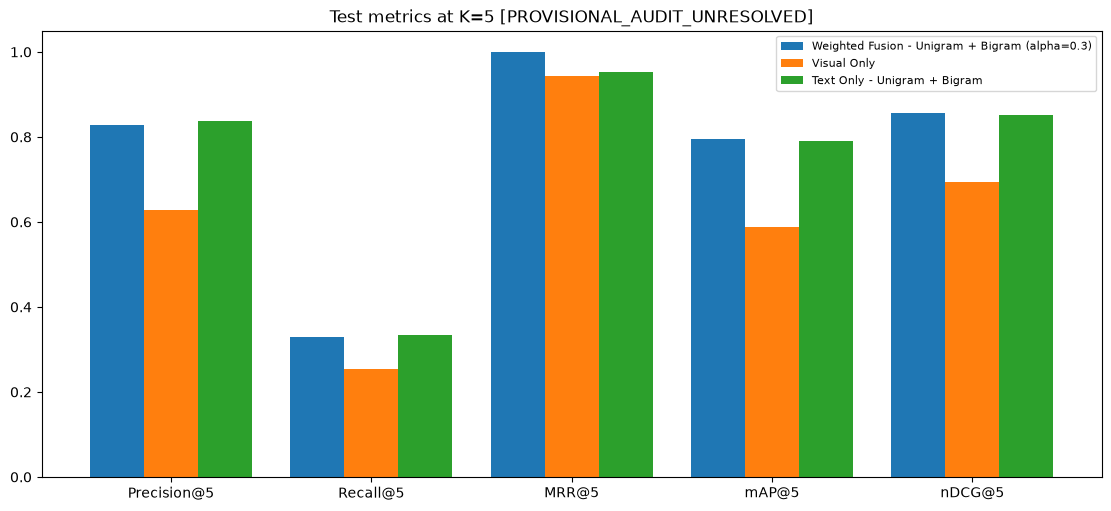

[SAVED] 222_test_metrics_PROVISIONAL.png
[SAVED] 717_test_per_query_metrics_PROVISIONAL.csv
[SAVED] 718_test_macro_metrics_PROVISIONAL.csv
[SAVED] 719_test_class_metrics_PROVISIONAL.csv
[SAVED] 720_test_metric_checks.csv
[SAVED] 721_test_metric_handoff_PROVISIONAL.json

CELL 15 COMPLETED


In [16]:
# ============================================================
# CELL 15 - TEST RETRIEVAL METRICS (status-labelled)
# ============================================================

assert globals().get("EVAL06_TEST_RANKING_COMPLETED") is True, "Jalankan Cell 14 terlebih dahulu."

EVAL06_TEST_METRICS_COMPLETED = False
eval06_test_metric_checks = []
print("NOTEBOOK 06 - CELL 15: TEST RETRIEVAL METRICS")
print("=" * 75)

frames = []
for method, config, alpha, role in EVAL06_TEST_METHODS:
    pq = eval06_per_query_metrics("test", eval06_fused_scores("test", config, alpha), method, config, alpha)
    pq["role"] = role
    frames.append(pq)
EVAL06_TEST_PER_QUERY_DF = pd.concat(frames, ignore_index=True)
EVAL06_TEST_PER_QUERY_DF["status"] = EVAL06_TEST_EVALUATION_STATUS
EVAL06_TEST_MACRO_ALL_DF = eval06_macro(EVAL06_TEST_PER_QUERY_DF, ["method", "role"])
EVAL06_TEST_MACRO_ALL_DF["status"] = EVAL06_TEST_EVALUATION_STATUS
EVAL06_TEST_CLASS_DF = eval06_macro(EVAL06_TEST_PER_QUERY_DF, ["method", "role", "query_class"])
EVAL06_TEST_MACRO_DF = EVAL06_TEST_MACRO_ALL_DF.loc[EVAL06_TEST_MACRO_ALL_DF["role"] == "selected_frozen"].reset_index(drop=True)
EVAL06_TEST_SELECTED_PER_QUERY_DF = EVAL06_TEST_PER_QUERY_DF.loc[EVAL06_TEST_PER_QUERY_DF["role"] == "selected_frozen"]

# Recompute metrics directly from the saved ranking rows (Cell 14).
ok = []
for qid, group in EVAL06_FROZEN_TEST_RANKING_ALL_DF.groupby("query_sample_id"):
    rel = group.sort_values("rank")["relevant"].to_numpy(dtype=int)
    for k in EVAL06_TOP_K_VALUES:
        m = eval06_metrics_at_k(rel, int(rel.sum()), k)
        stored = EVAL06_TEST_SELECTED_PER_QUERY_DF.loc[(EVAL06_TEST_SELECTED_PER_QUERY_DF["query_sample_id"] == qid)
                                                       & (EVAL06_TEST_SELECTED_PER_QUERY_DF["k"] == k)].iloc[0]
        ok.append(all(np.isclose(m[c], stored[c]) for c in EVAL06_METRIC_COLUMNS))
eval06_check(eval06_test_metric_checks, "Consistency", "Per-query metrics reproduce from Cell 14 rankings", all(ok))
eval06_check(eval06_test_metric_checks, "Consistency", "Macro = mean of per-query metrics",
             np.allclose(EVAL06_TEST_PER_QUERY_DF.groupby(["method", "role", "k"], sort=False)[EVAL06_METRIC_COLUMNS].mean().to_numpy(),
                         EVAL06_TEST_MACRO_ALL_DF[list(EVAL06_MACRO_COLUMNS.values())].to_numpy()))
eval06_check(eval06_test_metric_checks, "Consistency", "Metric values in [0, 1]",
             EVAL06_TEST_PER_QUERY_DF[EVAL06_METRIC_COLUMNS].stack().between(0, 1 + 1e-12).all())
eval06_check(eval06_test_metric_checks, "Consistency", "21 test queries per method",
             EVAL06_TEST_PER_QUERY_DF.groupby("method")["query_sample_id"].nunique().eq(len(EVAL06_QUERY_IDS["test"])).all())
rechosen, _ = sel09_select(EVAL06_ALPHA_AT5_DF)
eval06_check(eval06_test_metric_checks, "No tuning", "Validation selection unchanged after test metrics",
             (rechosen["text_configuration"], float(rechosen["alpha"])) == (EVAL06_SELECTED_TEXT_CONFIG, EVAL06_SELECTED_ALPHA))
eval06_check(eval06_test_metric_checks, "No tuning", "Selection lock file unchanged",
             eval06_sha256_file(EVAL06_SELECTION_LOCK_PATH) == EVAL06_SELECTION_LOCK_SHA256)
EVAL06_TEST_METRIC_CHECKS_DF = eval06_checks_frame(eval06_test_metric_checks)
eval06_require(EVAL06_TEST_METRIC_CHECKS_DF, "Cell 15")

test_map5 = float(EVAL06_TEST_MACRO_DF.loc[EVAL06_TEST_MACRO_DF["k"] == 5, "map_at_k"].iloc[0])
eval06_update_registry(test_map_at_5=round(test_map5, 6))

print(f"STATUS: {EVAL06_TEST_EVALUATION_STATUS}")
print("Frozen:", EVAL06_SELECTED_LABEL)
display(EVAL06_TEST_MACRO_ALL_DF.round(4))
display(EVAL06_TEST_METRIC_CHECKS_DF)

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
at5 = EVAL06_TEST_MACRO_ALL_DF.loc[EVAL06_TEST_MACRO_ALL_DF["k"] == 5].set_index("method")
x = np.arange(5)
for j, method in enumerate(at5.index):
    ax.bar(x + (j - 1) * 0.27, at5.loc[method, list(EVAL06_METRIC_DISPLAY)], width=0.27, label=method)
ax.set_xticks(x, [v.replace("K", "5") for v in EVAL06_METRIC_DISPLAY.values()])
ax.set(ylim=(0, 1.05), title=f"Test metrics at K=5 [{EVAL06_TEST_EVALUATION_STATUS}]")
ax.legend(fontsize=8)
eval06_save_figure(fig, f"222_test_metrics{SFX}.png", 15)

eval06_save_csv(EVAL06_TEST_PER_QUERY_DF, f"717_test_per_query_metrics{SFX}.csv", 15)
eval06_save_csv(EVAL06_TEST_MACRO_ALL_DF, f"718_test_macro_metrics{SFX}.csv", 15)
eval06_save_csv(EVAL06_TEST_CLASS_DF, f"719_test_class_metrics{SFX}.csv", 15)
eval06_save_csv(EVAL06_TEST_METRIC_CHECKS_DF, "720_test_metric_checks.csv", 15)
eval06_save_json({"cell": 15, "status": EVAL06_TEST_EVALUATION_STATUS, "selected": EVAL06_SELECTED_LABEL,
                  "test_map_at_5": test_map5, "independent_estimate": EVAL06_TEST_IS_INDEPENDENT_ESTIMATE,
                  "baselines_reporting_only": True}, f"721_test_metric_handoff{SFX}.json", 15)

EVAL06_TEST_METRICS_COMPLETED = True
print("\nCELL 15 COMPLETED")

## Cell 16 — Retrieval Error Analysis

NOTEBOOK 06 - CELL 16: RETRIEVAL ERROR ANALYSIS
Configuration: Weighted Fusion - Unigram + Bigram (alpha=0.3) | test status: PROVISIONAL_AUDIT_UNRESOLVED


,partition,queries,top1_accuracy,top1_is_identical_description,top1_is_flagged_near_duplicate,queries_with_identical_text_in_gallery
0,test,21,1.000000,3,2,3
1,validation,21,0.761905,1,0,1


,partition,true_class,n_queries,top1_correct,top5_hit,mean_precision_at_5,top1_identical_description,top1_flagged_near_duplicate,top1_accuracy,top5_hit_rate
0,test,Mangkok,4,4,4,1.00,0,0,1.0,1.0
1,test,Salam,4,4,4,0.55,0,2,1.0,1.0
2,test,Sambang Darah,4,4,4,0.70,0,0,1.0,1.0
3,test,Sirih,4,4,4,0.85,0,0,1.0,1.0
4,test,Tapak Kuda,5,5,5,1.00,3,0,1.0,1.0
5,validation,Mangkok,4,4,4,1.00,0,0,1.0,1.0
6,validation,Salam,4,0,4,0.40,0,0,0.0,1.0
7,validation,Sambang Darah,4,4,4,0.65,0,0,1.0,1.0
8,validation,Sirih,4,4,4,0.85,0,0,1.0,1.0
9,validation,Tapak Kuda,5,4,5,0.92,1,0,0.8,1.0


Top-1 errors:


,partition,query_sample_id,true_class,top1_predicted_class,top1_similarity,first_relevant_rank,top5_classes
4,validation,leaf_8809ccde35d4b945,Salam,Sambang Darah,0.570223,3,Sambang Darah | Sambang Darah | Salam | Mangko...
5,validation,leaf_68b0c81b496519cd,Salam,Sambang Darah,0.687959,3,Sambang Darah | Sambang Darah | Salam | Tapak ...
6,validation,leaf_a838808299383884,Salam,Sambang Darah,0.581773,2,Sambang Darah | Salam | Salam | Salam | Salam
7,validation,leaf_d12754f94f5ff7fc,Salam,Sambang Darah,0.697347,4,Sambang Darah | Sambang Darah | Sambang Darah ...
17,validation,leaf_2976a10d6fff3cd5,Tapak Kuda,Mangkok,0.643541,2,Mangkok | Tapak Kuda | Tapak Kuda | Tapak Kuda...



Top-1 confusion matrix - validation


top1_predicted_class,Mangkok,Salam,Sambang Darah,Sirih,Tapak Kuda
true_class,,,,,
Mangkok,4,0,0,0,0
Salam,0,0,4,0,0
Sambang Darah,0,0,4,0,0
Sirih,0,0,0,4,0
Tapak Kuda,1,0,0,0,4



Top-1 confusion matrix - test


top1_predicted_class,Mangkok,Salam,Sambang Darah,Sirih,Tapak Kuda
true_class,,,,,
Mangkok,4,0,0,0,0
Salam,0,4,0,0,0
Sambang Darah,0,0,4,0,0
Sirih,0,0,0,4,0
Tapak Kuda,0,0,0,0,5


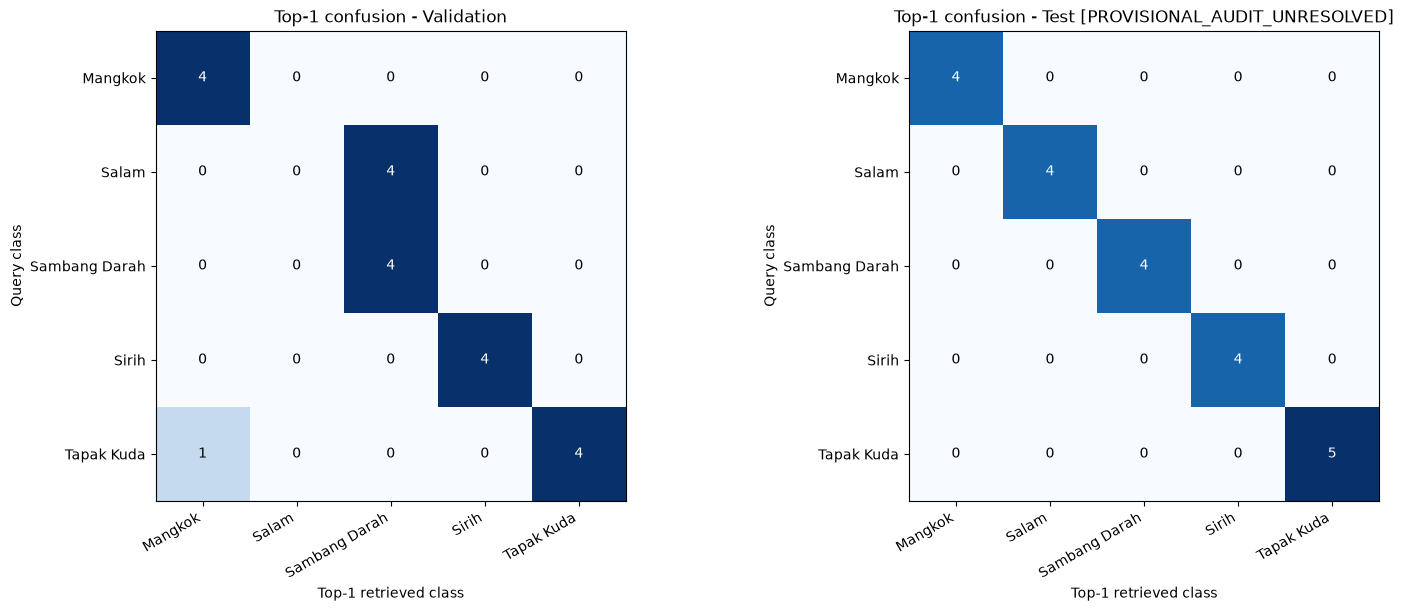

[SAVED] 223_top1_confusion_validation_test_PROVISIONAL.png


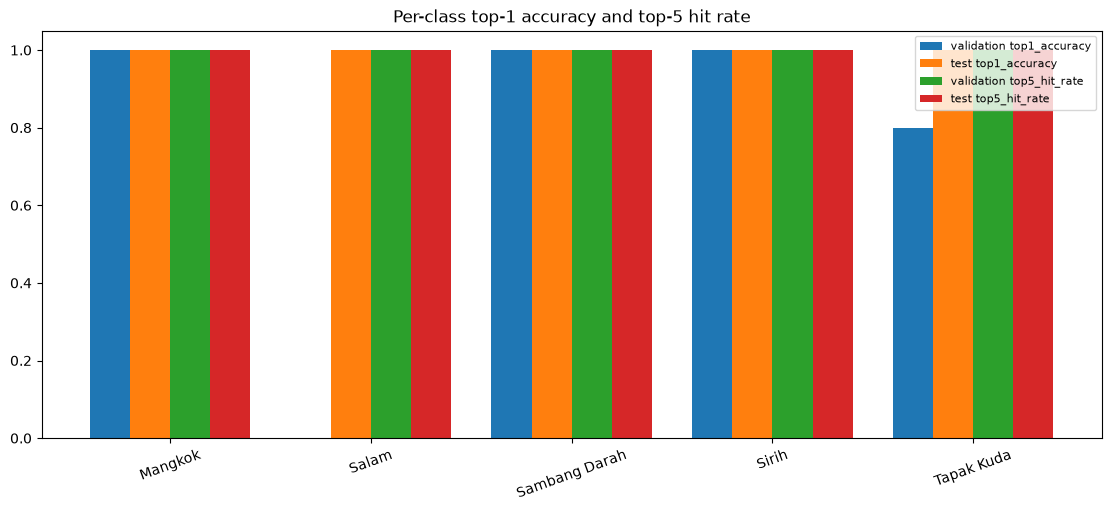

[SAVED] 224_top1_top5_hit_rates_PROVISIONAL.png
[SAVED] 722_query_error_analysis_PROVISIONAL.csv
[SAVED] 723_top1_errors_PROVISIONAL.csv
[SAVED] 724_top5_misses_PROVISIONAL.csv
[SAVED] 725_test_top1_confusion_matrix_PROVISIONAL.csv
[SAVED] 725b_validation_top1_confusion_matrix.csv
[SAVED] 726_class_error_summary_PROVISIONAL.csv
[SAVED] 727_error_analysis_checks.csv
[SAVED] 728_leakage_sensitivity_top1_PROVISIONAL.csv

CELL 16 COMPLETED


In [17]:
# ============================================================
# CELL 16 - RETRIEVAL ERROR ANALYSIS (selected frozen configuration)
# ============================================================
# Validation and test (test is status-labelled). Includes a leakage
# sensitivity view: is the top-1 item an identical description or a
# flagged near-duplicate image of the query?

assert globals().get("EVAL06_TEST_METRICS_COMPLETED") is True, "Jalankan Cell 15 terlebih dahulu."

EVAL06_ERROR_ANALYSIS_COMPLETED = False
eval06_error_checks = []
print("NOTEBOOK 06 - CELL 16: RETRIEVAL ERROR ANALYSIS")
print("=" * 75)

text_hash = EVAL06_TEXT_AUDIT_DF.set_index("sample_id")["text_sha256"].to_dict()
near_pairs = {frozenset((a, b)) for a, b in zip(EVAL06_NEAR_DUPLICATE_DF["sample_id_i"], EVAL06_NEAR_DUPLICATE_DF["sample_id_j"])}


def eval06_error_table(split):
    scores = eval06_fused_scores(split, EVAL06_SELECTED_TEXT_CONFIG, EVAL06_SELECTED_ALPHA)
    orders = eval06_rank_matrix(scores)
    rows = []
    for qi, qid in enumerate(EVAL06_QUERY_IDS[split]):
        true = EVAL06_SPLIT_LABELS[split][qi]
        ranked_ids = EVAL06_GALLERY_IDS_ARRAY[orders[qi]]
        ranked_cls = EVAL06_GALLERY_LABELS[orders[qi]]
        rel = ranked_cls == true
        top1 = ranked_ids[0]
        rows.append({
            "partition": split, "query_sample_id": qid, "true_class": true,
            "top1_gallery_id": top1, "top1_predicted_class": ranked_cls[0],
            "top1_similarity": float(scores[qi, orders[qi][0]]),
            "top1_visual_similarity": float(EVAL06_VISUAL_SIMILARITY_BY_SPLIT[split][qi, orders[qi][0]]),
            "top1_text_similarity": float(EVAL06_TEXT_SIMILARITY_BY_CONFIG[EVAL06_SELECTED_TEXT_CONFIG][split][qi, orders[qi][0]]),
            "top1_correct": bool(rel[0]), "top5_has_relevant": bool(rel[:5].any()),
            "top5_relevant_count": int(rel[:5].sum()), "top5_precision": float(rel[:5].mean()),
            "first_relevant_rank": int(np.flatnonzero(rel)[0] + 1),
            "top5_classes": " | ".join(ranked_cls[:5]),
            "top1_identical_description": text_hash[qid] == text_hash[top1],
            "top1_flagged_near_duplicate": frozenset((qid, top1)) in near_pairs,
            "query_has_identical_description_in_gallery": any(text_hash[qid] == text_hash[g] for g in EVAL06_GALLERY_IDS),
        })
    return pd.DataFrame(rows)


EVAL06_ERROR_ANALYSIS_DF = pd.concat([eval06_error_table("validation"), eval06_error_table("test")], ignore_index=True)
EVAL06_ERROR_ANALYSIS_DF["status"] = np.where(EVAL06_ERROR_ANALYSIS_DF["partition"] == "test",
                                              EVAL06_TEST_EVALUATION_STATUS, "VALIDATION")
EVAL06_TOP1_ERRORS_DF = EVAL06_ERROR_ANALYSIS_DF.loc[~EVAL06_ERROR_ANALYSIS_DF["top1_correct"]]
EVAL06_TOP5_MISSES_DF = EVAL06_ERROR_ANALYSIS_DF.loc[~EVAL06_ERROR_ANALYSIS_DF["top5_has_relevant"]]

EVAL06_CONFUSION = {}
for split in ("validation", "test"):
    sub = EVAL06_ERROR_ANALYSIS_DF.loc[EVAL06_ERROR_ANALYSIS_DF["partition"] == split]
    EVAL06_CONFUSION[split] = pd.crosstab(pd.Categorical(sub["true_class"], categories=EVAL06_CLASSES),
                                          pd.Categorical(sub["top1_predicted_class"], categories=EVAL06_CLASSES),
                                          rownames=["true_class"], colnames=["top1_predicted_class"], dropna=False)
EVAL06_CLASS_ERROR_SUMMARY_DF = (EVAL06_ERROR_ANALYSIS_DF.groupby(["partition", "true_class"])
    .agg(n_queries=("query_sample_id", "size"), top1_correct=("top1_correct", "sum"),
         top5_hit=("top5_has_relevant", "sum"), mean_precision_at_5=("top5_precision", "mean"),
         top1_identical_description=("top1_identical_description", "sum"),
         top1_flagged_near_duplicate=("top1_flagged_near_duplicate", "sum"))
    .reset_index())
EVAL06_CLASS_ERROR_SUMMARY_DF["top1_accuracy"] = EVAL06_CLASS_ERROR_SUMMARY_DF["top1_correct"] / EVAL06_CLASS_ERROR_SUMMARY_DF["n_queries"]
EVAL06_CLASS_ERROR_SUMMARY_DF["top5_hit_rate"] = EVAL06_CLASS_ERROR_SUMMARY_DF["top5_hit"] / EVAL06_CLASS_ERROR_SUMMARY_DF["n_queries"]

EVAL06_LEAKAGE_SENSITIVITY_DF = (EVAL06_ERROR_ANALYSIS_DF.groupby("partition")
    .agg(queries=("query_sample_id", "size"), top1_accuracy=("top1_correct", "mean"),
         top1_is_identical_description=("top1_identical_description", "sum"),
         top1_is_flagged_near_duplicate=("top1_flagged_near_duplicate", "sum"),
         queries_with_identical_text_in_gallery=("query_has_identical_description_in_gallery", "sum"))
    .reset_index())

# Cross-check with Cell 15 / Cell 9 (P@1 == top-1 accuracy)
test_p1 = float(EVAL06_TEST_MACRO_DF.loc[EVAL06_TEST_MACRO_DF["k"] == 1, "mean_precision_at_k"].iloc[0])
val_p1 = float(EVAL06_SELECTED_METRICS_BY_K_DF.loc[EVAL06_SELECTED_METRICS_BY_K_DF["k"] == 1, "mean_precision_at_k"].iloc[0])
eval06_check(eval06_error_checks, "Consistency", "Test top-1 accuracy equals test Precision@1 (Cell 15)",
             np.isclose(EVAL06_ERROR_ANALYSIS_DF.query("partition == 'test'")["top1_correct"].mean(), test_p1))
eval06_check(eval06_error_checks, "Consistency", "Validation top-1 accuracy equals Precision@1 (Cell 9)",
             np.isclose(EVAL06_ERROR_ANALYSIS_DF.query("partition == 'validation'")["top1_correct"].mean(), val_p1))
eval06_check(eval06_error_checks, "Consistency", "Confusion matrices sum to query counts",
             all(EVAL06_CONFUSION[s].to_numpy().sum() == len(EVAL06_QUERY_IDS[s]) for s in ("validation", "test")))
eval06_check(eval06_error_checks, "Consistency", "Confusion diagonal equals top-1 correct count",
             all(np.trace(EVAL06_CONFUSION[s].to_numpy()) == EVAL06_ERROR_ANALYSIS_DF.query("partition == @s")["top1_correct"].sum()
                 for s in ("validation", "test")))
EVAL06_ERROR_CHECKS_DF = eval06_checks_frame(eval06_error_checks)
eval06_require(EVAL06_ERROR_CHECKS_DF, "Cell 16")

print("Configuration:", EVAL06_SELECTED_LABEL, "| test status:", EVAL06_TEST_EVALUATION_STATUS)
display(EVAL06_LEAKAGE_SENSITIVITY_DF)
display(EVAL06_CLASS_ERROR_SUMMARY_DF.round(3))
print("Top-1 errors:")
display(EVAL06_TOP1_ERRORS_DF[["partition", "query_sample_id", "true_class", "top1_predicted_class",
                               "top1_similarity", "first_relevant_rank", "top5_classes"]])
for s in ("validation", "test"):
    print(f"\nTop-1 confusion matrix - {s}")
    display(EVAL06_CONFUSION[s])

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
for ax, s in zip(axes, ("validation", "test")):
    m = EVAL06_CONFUSION[s].to_numpy()
    im = ax.imshow(m, cmap="Blues")
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, int(m[i, j]), ha="center", va="center", color="white" if m[i, j] > m.max() / 2 else "black")
    ax.set_xticks(range(5), EVAL06_CLASSES, rotation=30, ha="right")
    ax.set_yticks(range(5), EVAL06_CLASSES)
    title = "Validation" if s == "validation" else f"Test [{EVAL06_TEST_EVALUATION_STATUS}]"
    ax.set(title=f"Top-1 confusion - {title}", xlabel="Top-1 retrieved class", ylabel="Query class")
eval06_save_figure(fig, f"223_top1_confusion_validation_test{SFX}.png", 16)

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
x = np.arange(5)
for j, (s, col) in enumerate([("validation", "top1_accuracy"), ("test", "top1_accuracy"),
                              ("validation", "top5_hit_rate"), ("test", "top5_hit_rate")]):
    sub = EVAL06_CLASS_ERROR_SUMMARY_DF.loc[EVAL06_CLASS_ERROR_SUMMARY_DF["partition"] == s].set_index("true_class").loc[EVAL06_CLASSES]
    ax.bar(x + (j - 1.5) * 0.2, sub[col], width=0.2, label=f"{s} {col}")
ax.set_xticks(x, EVAL06_CLASSES, rotation=20)
ax.set(ylim=(0, 1.05), title="Per-class top-1 accuracy and top-5 hit rate")
ax.legend(fontsize=8)
eval06_save_figure(fig, f"224_top1_top5_hit_rates{SFX}.png", 16)

eval06_save_csv(EVAL06_ERROR_ANALYSIS_DF, f"722_query_error_analysis{SFX}.csv", 16)
eval06_save_csv(EVAL06_TOP1_ERRORS_DF, f"723_top1_errors{SFX}.csv", 16)
eval06_save_csv(EVAL06_TOP5_MISSES_DF, f"724_top5_misses{SFX}.csv", 16)
eval06_save_csv(EVAL06_CONFUSION["test"].reset_index(), f"725_test_top1_confusion_matrix{SFX}.csv", 16)
eval06_save_csv(EVAL06_CONFUSION["validation"].reset_index(), "725b_validation_top1_confusion_matrix.csv", 16)
eval06_save_csv(EVAL06_CLASS_ERROR_SUMMARY_DF, f"726_class_error_summary{SFX}.csv", 16)
eval06_save_csv(EVAL06_ERROR_CHECKS_DF, "727_error_analysis_checks.csv", 16)
eval06_save_csv(EVAL06_LEAKAGE_SENSITIVITY_DF, f"728_leakage_sensitivity_top1{SFX}.csv", 16)

EVAL06_ERROR_ANALYSIS_COMPLETED = True
print("\nCELL 16 COMPLETED")

## Cell 17 — Retrieval Visualization

NOTEBOOK 06 - CELL 17: RETRIEVAL VISUALIZATION


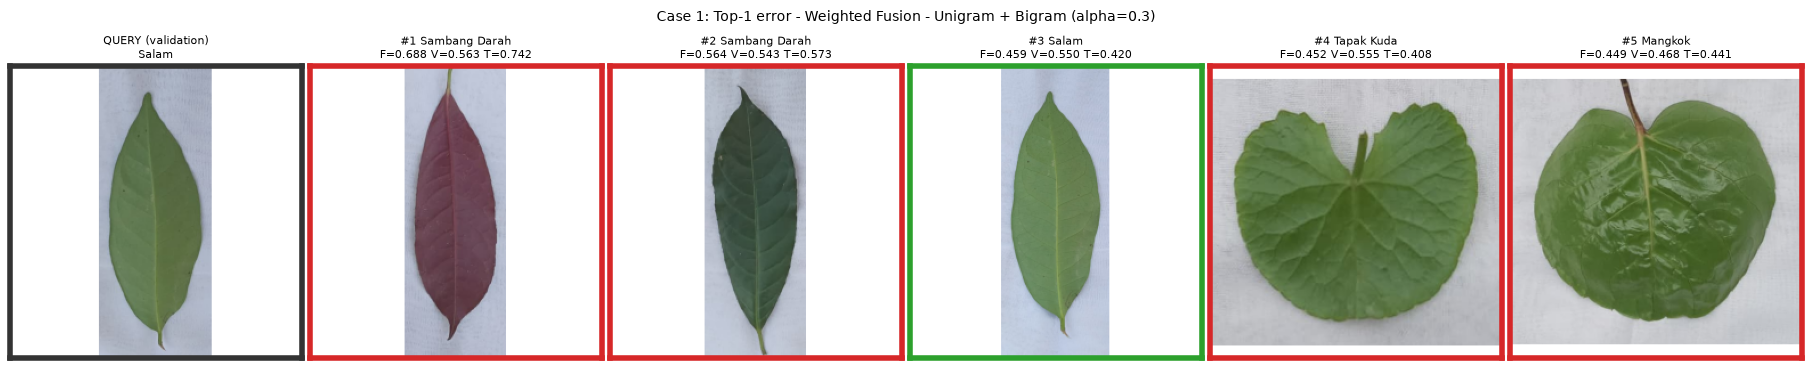

[SAVED] 225_case_01_validation_leaf_68b0c81b496519cd.png


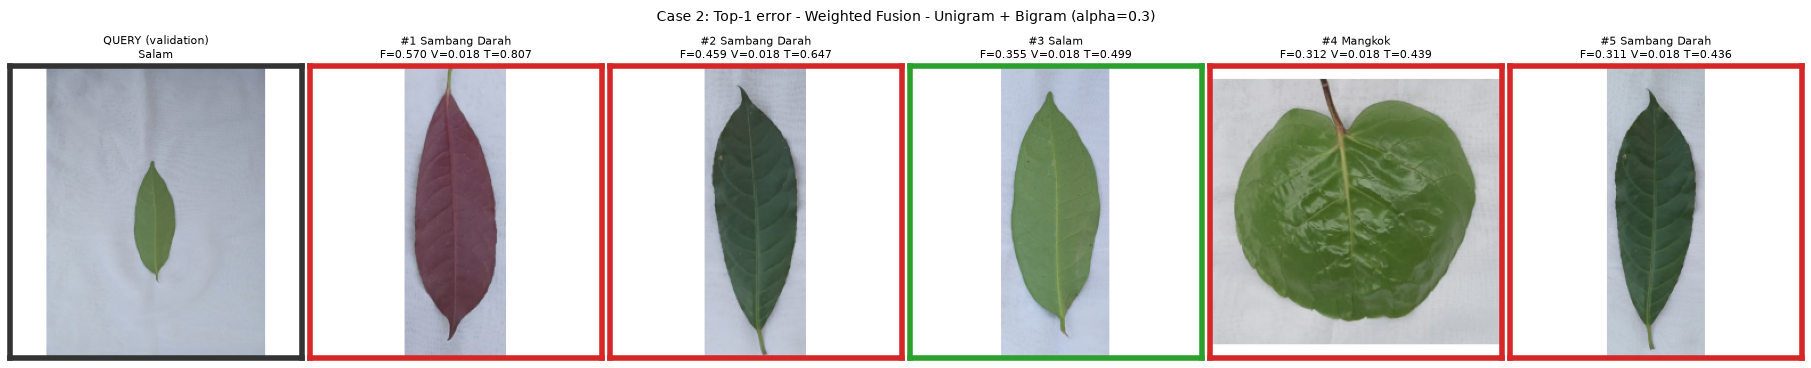

[SAVED] 225_case_02_validation_leaf_8809ccde35d4b945.png


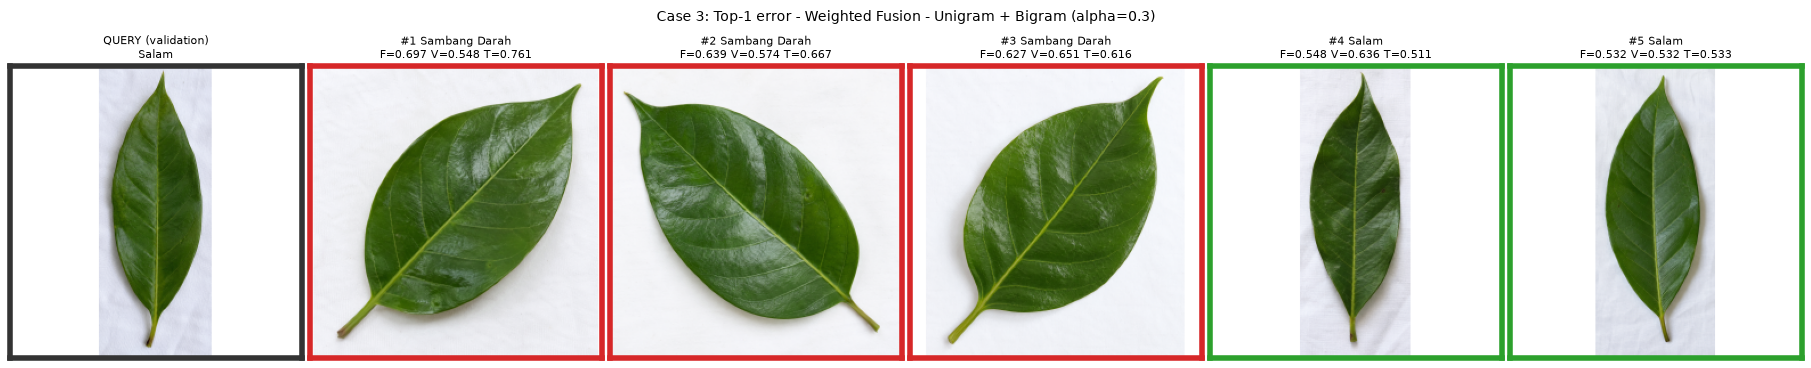

[SAVED] 225_case_03_validation_leaf_d12754f94f5ff7fc.png


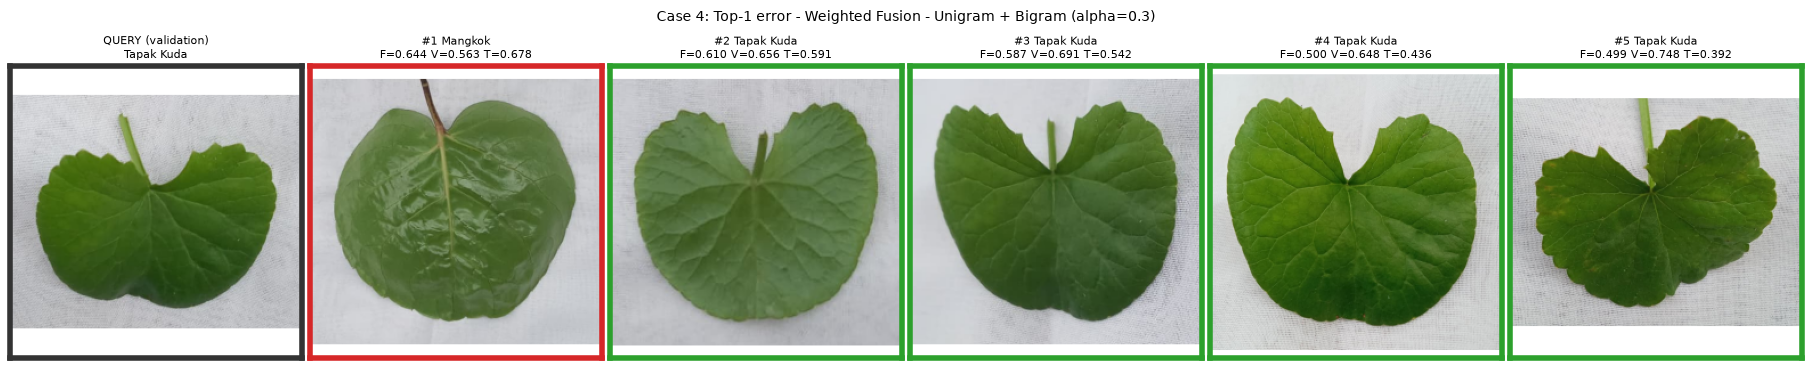

[SAVED] 225_case_04_validation_leaf_2976a10d6fff3cd5.png


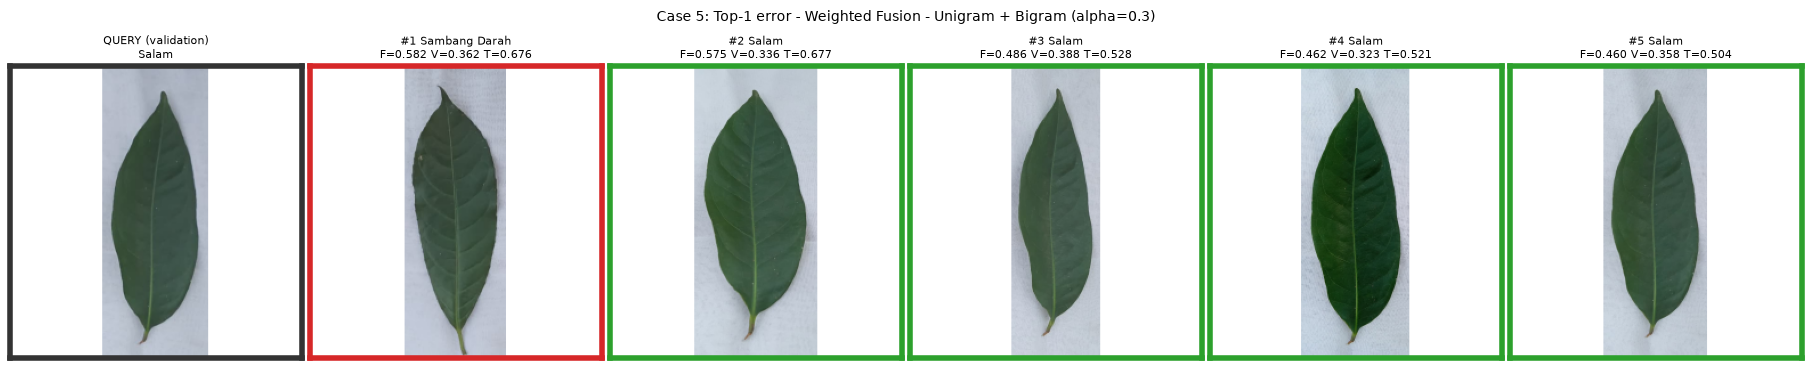

[SAVED] 225_case_05_validation_leaf_a838808299383884.png


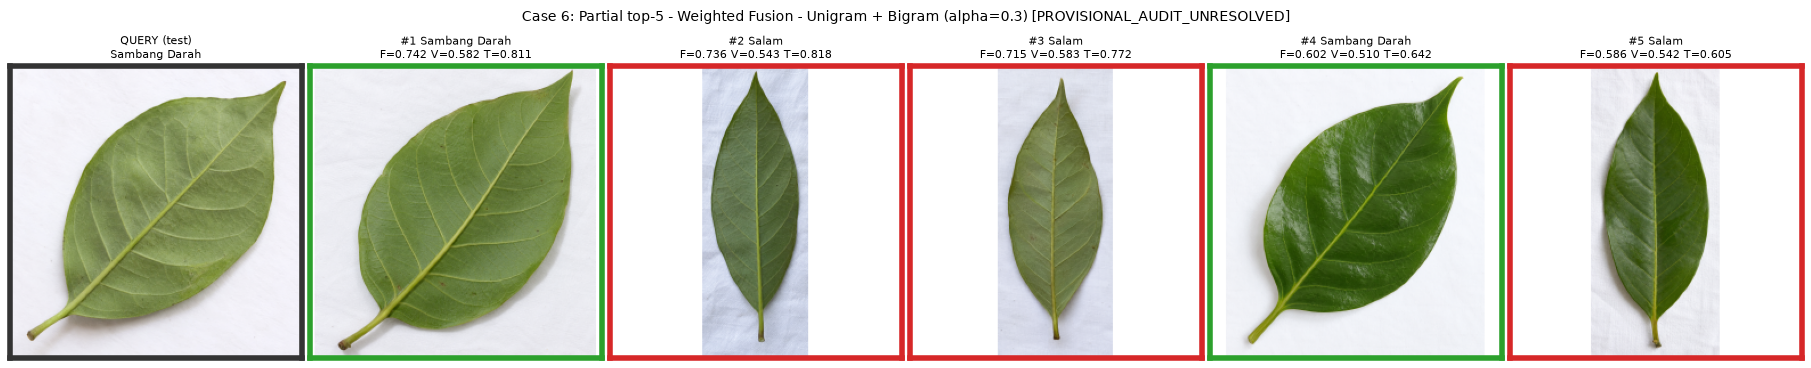

[SAVED] 225_case_06_test_leaf_1a45e1e109be76ee_PROVISIONAL.png


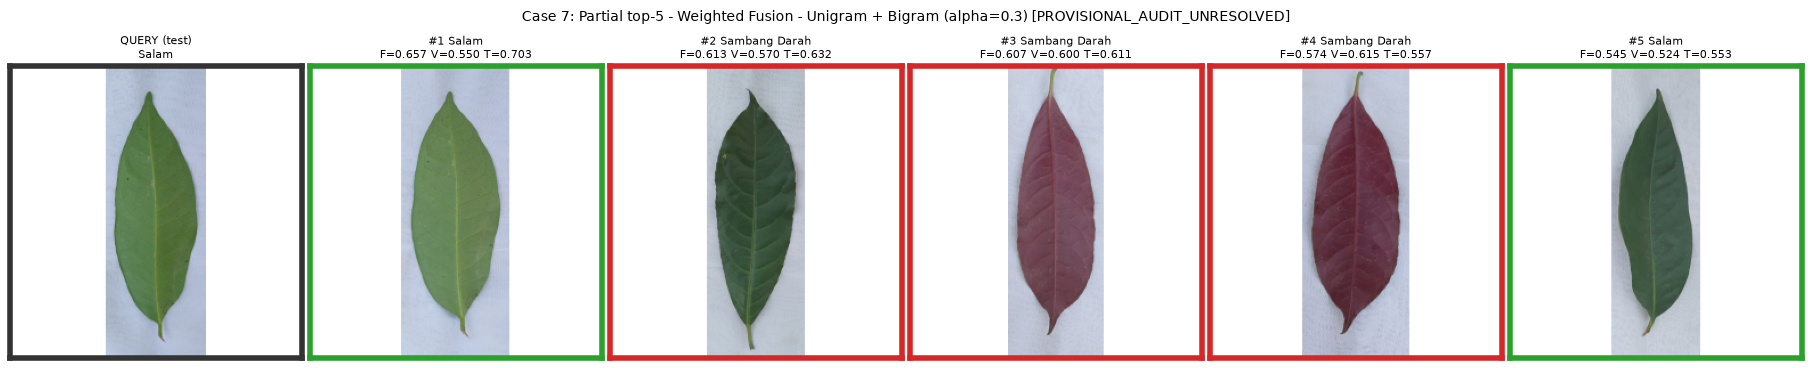

[SAVED] 225_case_07_test_leaf_1ebaf9512209a61f_PROVISIONAL.png


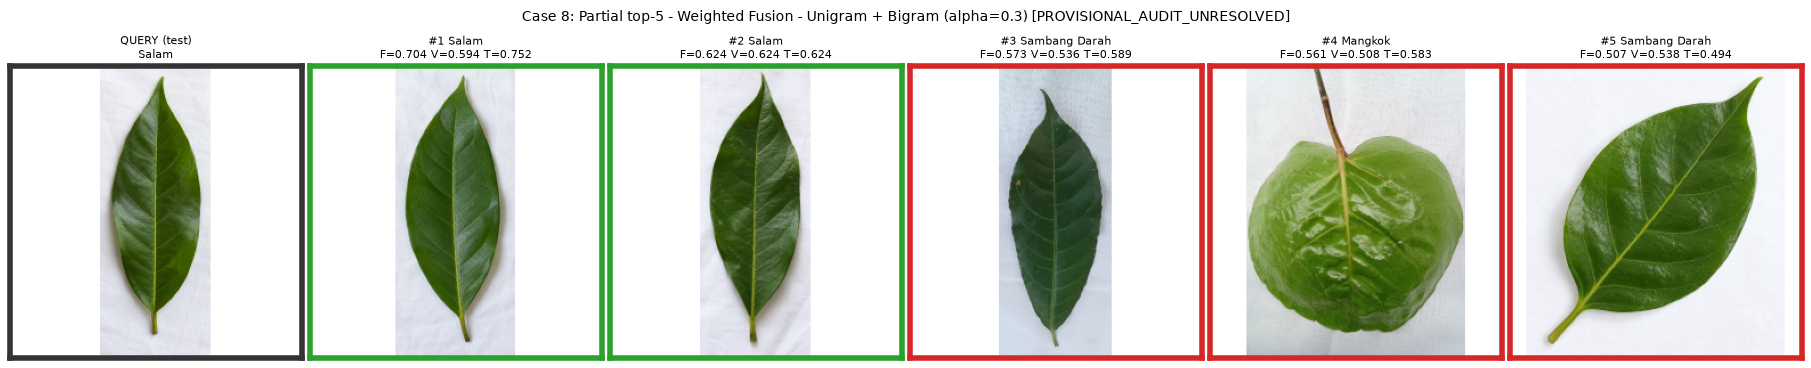

[SAVED] 225_case_08_test_leaf_9c7d463a5bb1a561_PROVISIONAL.png
Cases: 8 | images readable for cases: 34 / 34


,case_number,partition,query_sample_id,true_class,case_type,top1_predicted_class,top5_precision
0,1,validation,leaf_68b0c81b496519cd,Salam,Top-1 error,Sambang Darah,0.2
1,2,validation,leaf_8809ccde35d4b945,Salam,Top-1 error,Sambang Darah,0.2
2,3,validation,leaf_d12754f94f5ff7fc,Salam,Top-1 error,Sambang Darah,0.4
3,4,validation,leaf_2976a10d6fff3cd5,Tapak Kuda,Top-1 error,Mangkok,0.8
4,5,validation,leaf_a838808299383884,Salam,Top-1 error,Sambang Darah,0.8
5,6,test,leaf_1a45e1e109be76ee,Sambang Darah,Partial top-5,Sambang Darah,0.4
6,7,test,leaf_1ebaf9512209a61f,Salam,Partial top-5,Salam,0.4
7,8,test,leaf_9c7d463a5bb1a561,Salam,Partial top-5,Salam,0.4


[SAVED] 729_case_study_selected_PROVISIONAL.csv
[SAVED] 730_case_study_top5_details_PROVISIONAL.csv
[SAVED] 731_case_study_image_audit.csv
[SAVED] 732_case_study_checks.csv

CELL 17 COMPLETED


In [18]:
# ============================================================
# CELL 17 - RETRIEVAL VISUALIZATION (query + top-5 case studies)
# ============================================================
# Cases: all top-1 errors first, then the lowest Precision@5 queries
# (test first, then validation). Processed images are drawn when they
# are available; otherwise a labelled placeholder panel is drawn and the
# missing file is listed in 731 (no synthetic images are created).

assert globals().get("EVAL06_ERROR_ANALYSIS_COMPLETED") is True, "Jalankan Cell 16 terlebih dahulu."

EVAL06_VISUALIZATION_COMPLETED = False
print("NOTEBOOK 06 - CELL 17: RETRIEVAL VISUALIZATION")
print("=" * 75)

MAX_CASES = 8
image_path_map = EVAL06_IMAGE_AUDIT_DF.set_index("sample_id")["resolved_image_path"].to_dict()
readable_map = EVAL06_IMAGE_AUDIT_DF.set_index("sample_id")["image_readable"].to_dict()
class_map = dict(zip(EVAL06_SAMPLE_IDS, EVAL06_LABELS))

ranked_cases = EVAL06_ERROR_ANALYSIS_DF.assign(
    partition_order=EVAL06_ERROR_ANALYSIS_DF["partition"].map({"test": 0, "validation": 1}),
    case_type=np.where(~EVAL06_ERROR_ANALYSIS_DF["top1_correct"], "Top-1 error",
                       np.where(EVAL06_ERROR_ANALYSIS_DF["top5_precision"] < 1, "Partial top-5", "Fully correct top-5")))
ranked_cases = ranked_cases.sort_values(["top1_correct", "top5_precision", "partition_order", "query_sample_id"],
                                        kind="stable").head(MAX_CASES).reset_index(drop=True)
ranked_cases.insert(0, "case_number", np.arange(1, len(ranked_cases) + 1))


def eval06_draw_panel(ax, sample_id, title, border_color):
    path = image_path_map.get(sample_id, "")
    if readable_map.get(sample_id, False) and path:
        with Image.open(path) as im:
            ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
    else:
        ax.set_facecolor("#F2F2F2")
        ax.text(0.5, 0.5, "image not\navailable\n" + sample_id[-8:], ha="center", va="center",
                fontsize=8, transform=ax.transAxes, color="#555555")
    for spine in ax.spines.values():
        spine.set_edgecolor(border_color)
        spine.set_linewidth(4)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title, fontsize=8)


detail_rows = []
for case in ranked_cases.itertuples(index=False):
    split = case.partition
    qi = EVAL06_QUERY_IDS[split].index(case.query_sample_id)
    scores = eval06_fused_scores(split, EVAL06_SELECTED_TEXT_CONFIG, EVAL06_SELECTED_ALPHA)
    order = eval06_rank_order(scores[qi])[:5]
    fig, axes = plt.subplots(1, 6, figsize=(18, 3.9), constrained_layout=True)
    eval06_draw_panel(axes[0], case.query_sample_id, f"QUERY ({split})\n{case.true_class}", "#333333")
    for rank, gi in enumerate(order, start=1):
        gid = EVAL06_GALLERY_IDS_ARRAY[gi]
        relevant = EVAL06_GALLERY_LABELS[gi] == case.true_class
        v = EVAL06_VISUAL_SIMILARITY_BY_SPLIT[split][qi, gi]
        t = EVAL06_TEXT_SIMILARITY_BY_CONFIG[EVAL06_SELECTED_TEXT_CONFIG][split][qi, gi]
        eval06_draw_panel(axes[rank], gid, f"#{rank} {EVAL06_GALLERY_LABELS[gi]}\nF={scores[qi, gi]:.3f} V={v:.3f} T={t:.3f}",
                          "#2CA02C" if relevant else "#D62728")
        detail_rows.append({"case_number": case.case_number, "partition": split, "query_sample_id": case.query_sample_id,
                            "query_class": case.true_class, "rank": rank, "gallery_sample_id": gid,
                            "gallery_class": EVAL06_GALLERY_LABELS[gi], "relevant": bool(relevant),
                            "fusion_similarity": float(scores[qi, gi]), "visual_similarity": float(v),
                            "text_similarity": float(t)})
    label = "" if split == "validation" else f" [{EVAL06_TEST_EVALUATION_STATUS}]"
    fig.suptitle(f"Case {case.case_number}: {case.case_type} - {EVAL06_SELECTED_LABEL}{label}", fontsize=10)
    case_suffix = SFX if split == "test" else ""
    eval06_save_figure(fig, f"225_case_{case.case_number:02d}_{split}_{case.query_sample_id}{case_suffix}.png", 17, dpi=150)

EVAL06_CASE_DETAILS_DF = pd.DataFrame(detail_rows)
case_ids = set(ranked_cases["query_sample_id"]) | set(EVAL06_CASE_DETAILS_DF["gallery_sample_id"])
EVAL06_CASE_IMAGE_AUDIT_DF = pd.DataFrame([{"sample_id": s, "image_readable": bool(readable_map.get(s, False)),
                                            "resolved_image_path": image_path_map.get(s, "")} for s in sorted(case_ids)])
EVAL06_CASE_CHECKS_DF = pd.DataFrame([
    {"check": "Each case has exactly 5 retrieved items",
     "passed": EVAL06_CASE_DETAILS_DF.groupby("case_number").size().eq(5).all()},
    {"check": "Top-5 relevance agrees with Cell 16",
     "passed": all(EVAL06_CASE_DETAILS_DF.loc[EVAL06_CASE_DETAILS_DF["case_number"] == c.case_number, "relevant"].sum()
                   == c.top5_relevant_count for c in ranked_cases.itertuples())},
    {"check": "No duplicate gallery item within a case",
     "passed": EVAL06_CASE_DETAILS_DF.groupby("case_number")["gallery_sample_id"].apply(lambda v: v.is_unique).all()},
])
assert EVAL06_CASE_CHECKS_DF["passed"].all(), EVAL06_CASE_CHECKS_DF.to_string(index=False)

print("Cases:", len(ranked_cases), "| images readable for cases:",
      int(EVAL06_CASE_IMAGE_AUDIT_DF["image_readable"].sum()), "/", len(EVAL06_CASE_IMAGE_AUDIT_DF))
display(ranked_cases[["case_number", "partition", "query_sample_id", "true_class", "case_type",
                      "top1_predicted_class", "top5_precision"]])

eval06_save_csv(ranked_cases, f"729_case_study_selected{SFX}.csv", 17)
eval06_save_csv(EVAL06_CASE_DETAILS_DF, f"730_case_study_top5_details{SFX}.csv", 17)
eval06_save_csv(EVAL06_CASE_IMAGE_AUDIT_DF, "731_case_study_image_audit.csv", 17)
eval06_save_csv(EVAL06_CASE_CHECKS_DF, "732_case_study_checks.csv", 17)

EVAL06_VISUALIZATION_COMPLETED = True
print("\nCELL 17 COMPLETED")

## Cell 18 — Validation vs Test Comparison

NOTEBOOK 06 - CELL 18: VALIDATION VS TEST
Test status: PROVISIONAL_AUDIT_UNRESOLVED


,method,k,metric,validation,test,test_minus_validation,test_status
0,Weighted Fusion - Unigram + Bigram (alpha=0.3),5,Precision@K,0.7714,0.8286,0.0571,PROVISIONAL_AUDIT_UNRESOLVED
1,Weighted Fusion - Unigram + Bigram (alpha=0.3),5,Recall@K,0.3061,0.3294,0.0233,PROVISIONAL_AUDIT_UNRESOLVED
2,Weighted Fusion - Unigram + Bigram (alpha=0.3),5,MRR@K,0.8532,1.0000,0.1468,PROVISIONAL_AUDIT_UNRESOLVED
3,Weighted Fusion - Unigram + Bigram (alpha=0.3),5,mAP@K,0.7052,0.7941,0.0889,PROVISIONAL_AUDIT_UNRESOLVED
4,Weighted Fusion - Unigram + Bigram (alpha=0.3),5,nDCG@K,0.7715,0.8573,0.0858,PROVISIONAL_AUDIT_UNRESOLVED
5,Visual Only,5,Precision@K,0.6000,0.6286,0.0286,PROVISIONAL_AUDIT_UNRESOLVED
6,Visual Only,5,Recall@K,0.2374,0.2538,0.0165,PROVISIONAL_AUDIT_UNRESOLVED
7,Visual Only,5,MRR@K,0.9048,0.9444,0.0397,PROVISIONAL_AUDIT_UNRESOLVED
8,Visual Only,5,mAP@K,0.5522,0.5878,0.0356,PROVISIONAL_AUDIT_UNRESOLVED
9,Visual Only,5,nDCG@K,0.6525,0.6940,0.0415,PROVISIONAL_AUDIT_UNRESOLVED


,query_class,validation_map_at_5,test_map_at_5,validation_queries,test_queries,test_minus_validation
0,Mangkok,1.0000,1.0000,4,4,0.0000
1,Salam,0.2017,0.4358,4,4,0.2342
2,Sambang Darah,0.6042,0.6625,4,4,0.0583
3,Sirih,0.8500,0.8208,4,4,-0.0292
4,Tapak Kuda,0.8373,1.0000,5,5,0.1627


,limitation,count_or_size,status
0,Cross-split visually similar images (dHash can...,44,OPEN
1,Identical descriptions across partitions,4,PENDING_REVIEW
2,Specimen / capture identity not declared,1,PENDING_REVIEW
3,Image pixel audit not recomputed in this envir...,0,processed_images_recomputed
4,Test partition inspected in earlier runs,1,PERMANENT - test is not an independent estimate
5,Small validation set -> optimistic selection,21,Selection over 22 candidates on 21 queries
6,Query visual features far outside gallery rang...,7,"leaf_1a80f5749cc68900, leaf_3c3fafa9c7913736, ..."
7,Earlier runs used a different (unverified) vis...,1,Resolved for this run (NB03 vectors); earlier ...


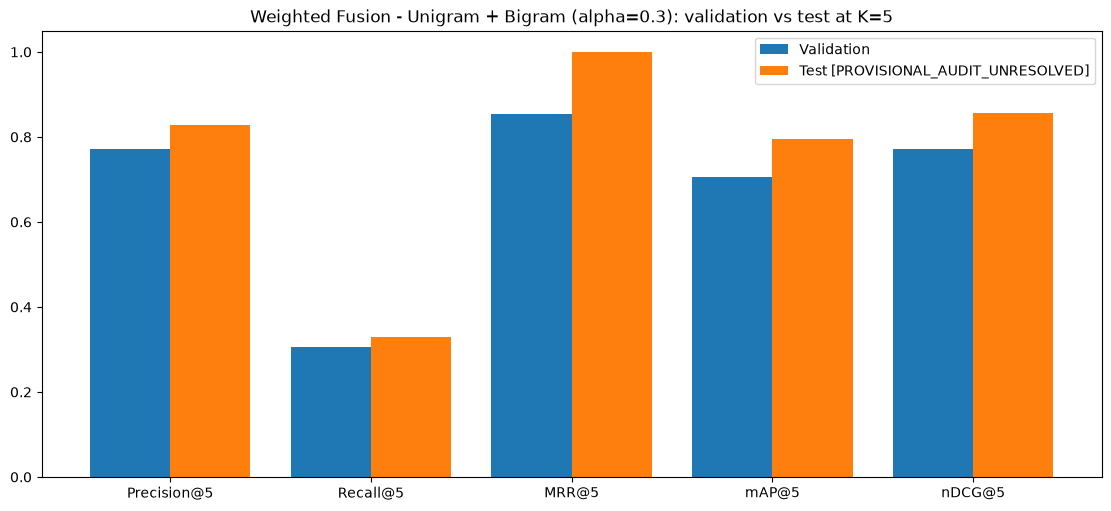

[SAVED] 226_validation_vs_test_metrics_at_5_PROVISIONAL.png


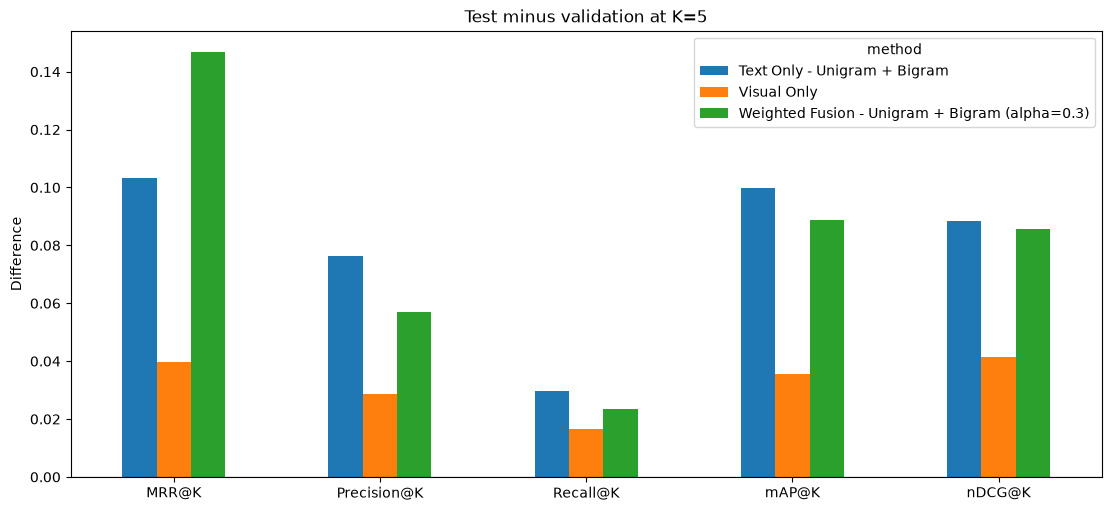

[SAVED] 227_validation_test_metric_gaps_PROVISIONAL.png
[SAVED] 734_validation_vs_test_metric_comparison_PROVISIONAL.csv
[SAVED] 735_validation_vs_test_metric_gaps_at_5_PROVISIONAL.csv
[SAVED] 736_validation_vs_test_class_gaps_PROVISIONAL.csv
[SAVED] 737_validation_vs_test_limitations.csv
[SAVED] 738_validation_vs_test_reconciliation.csv

CELL 18 COMPLETED


In [19]:
# ============================================================
# CELL 18 - VALIDATION VS TEST COMPARISON & LIMITATIONS
# ============================================================

assert globals().get("EVAL06_VISUALIZATION_COMPLETED") is True, "Jalankan Cell 17 terlebih dahulu."

EVAL06_COMPARISON_COMPLETED = False
print("NOTEBOOK 06 - CELL 18: VALIDATION VS TEST")
print("=" * 75)

val_sources = {
    EVAL06_SELECTED_LABEL: EVAL06_SELECTED_METRICS_BY_K_DF,
    "Visual Only": EVAL06_VALIDATION_MACRO_DF.loc[EVAL06_VALIDATION_MACRO_DF["method"] == "Visual Only"],
    f"Text Only - {EVAL06_SELECTED_TEXT_CONFIG}":
        EVAL06_VALIDATION_MACRO_DF.loc[EVAL06_VALIDATION_MACRO_DF["method"] == f"Text Only - {EVAL06_SELECTED_TEXT_CONFIG}"],
}
rows = []
for method, val in val_sources.items():
    test = EVAL06_TEST_MACRO_ALL_DF.loc[EVAL06_TEST_MACRO_ALL_DF["method"] == method]
    assert len(val) == len(test) == len(EVAL06_TOP_K_VALUES), method
    for k in EVAL06_TOP_K_VALUES:
        v = val.loc[val["k"] == k].iloc[0]
        t = test.loc[test["k"] == k].iloc[0]
        for column, name in EVAL06_METRIC_DISPLAY.items():
            rows.append({"method": method, "k": k, "metric": name, "validation": float(v[column]),
                         "test": float(t[column]), "test_minus_validation": float(t[column] - v[column]),
                         "test_status": EVAL06_TEST_EVALUATION_STATUS})
EVAL06_VAL_TEST_COMPARISON_DF = pd.DataFrame(rows)
EVAL06_VAL_TEST_AT5_DF = EVAL06_VAL_TEST_COMPARISON_DF.loc[EVAL06_VAL_TEST_COMPARISON_DF["k"] == 5].reset_index(drop=True)

val_cls = EVAL06_ALPHA_CLASS_DF.loc[(EVAL06_ALPHA_CLASS_DF["text_configuration"] == EVAL06_SELECTED_TEXT_CONFIG)
                                    & np.isclose(EVAL06_ALPHA_CLASS_DF["alpha"], EVAL06_SELECTED_ALPHA)
                                    & (EVAL06_ALPHA_CLASS_DF["k"] == 5)].set_index("query_class")
test_cls = EVAL06_TEST_CLASS_DF.loc[(EVAL06_TEST_CLASS_DF["role"] == "selected_frozen")
                                    & (EVAL06_TEST_CLASS_DF["k"] == 5)].set_index("query_class")
EVAL06_CLASS_GAPS_DF = pd.DataFrame({
    "query_class": EVAL06_CLASSES,
    "validation_map_at_5": val_cls.loc[EVAL06_CLASSES, "map_at_k"].to_numpy(),
    "test_map_at_5": test_cls.loc[EVAL06_CLASSES, "map_at_k"].to_numpy(),
    "validation_queries": val_cls.loc[EVAL06_CLASSES, "queries"].to_numpy(),
    "test_queries": test_cls.loc[EVAL06_CLASSES, "queries"].to_numpy()})
EVAL06_CLASS_GAPS_DF["test_minus_validation"] = EVAL06_CLASS_GAPS_DF["test_map_at_5"] - EVAL06_CLASS_GAPS_DF["validation_map_at_5"]

EVAL06_LIMITATIONS_DF = pd.DataFrame([
    ("Cross-split visually similar images (dHash candidates)", EVAL06_CROSS_SPLIT_NEAR_DUPLICATES,
     "OPEN" if EVAL06_OPEN_PAIR_REVIEWS else "REVIEWED"),
    ("Identical descriptions across partitions", EVAL06_CROSS_SPLIT_TEXT_GROUPS,
     EVAL06_RESOLUTION_MATRIX_DF.set_index("issue_id").loc["TEXT_REPEAT_SPLIT", "resolution_state"]),
    ("Specimen / capture identity not declared", int(EVAL06_GROUP_COLUMN is None),
     EVAL06_RESOLUTION_MATRIX_DF.set_index("issue_id").loc["SPECIMEN_PROVENANCE", "resolution_state"]),
    ("Image pixel audit not recomputed in this environment", int(EVAL06_IMAGE_HASH_SOURCE != "processed_images_recomputed"),
     EVAL06_IMAGE_HASH_SOURCE),
    ("Test partition inspected in earlier runs", int(EVAL06_TEST_PREVIOUSLY_INSPECTED),
     "PERMANENT - test is not an independent estimate"),
    ("Small validation set -> optimistic selection", len(EVAL06_QUERY_IDS["validation"]),
     "Selection over 22 candidates on 21 queries"),
    ("Query visual features far outside gallery range (|z| > 10)", int(EVAL06_VISUAL_OOD_DF["sample_id"].nunique()),
     ", ".join(sorted(EVAL06_VISUAL_OOD_DF["sample_id"].unique())) or "none"),
    ("Earlier runs used a different (unverified) visual extractor", 1,
     "Resolved for this run (NB03 vectors); earlier numbers are not comparable"),
], columns=["limitation", "count_or_size", "status"])

recon = EVAL06_TEST_SELECTED_PER_QUERY_DF.query("k == 5")["ap_at_k"].mean()
EVAL06_RECONCILIATION_DF = pd.DataFrame([
    {"check": "Test mAP@5 equals mean per-query AP@5",
     "passed": bool(np.isclose(recon, EVAL06_VAL_TEST_AT5_DF.query("method == @EVAL06_SELECTED_LABEL and metric == 'mAP@K'")["test"].iloc[0]))},
    {"check": "Validation mAP@5 equals selection lock",
     "passed": bool(np.isclose(EVAL06_SELECTION_LOCK["selected_validation_map_at_5"],
                               EVAL06_VAL_TEST_AT5_DF.query("method == @EVAL06_SELECTED_LABEL and metric == 'mAP@K'")["validation"].iloc[0]))},
    {"check": "Same frozen configuration on both partitions", "passed": True},
])
assert EVAL06_RECONCILIATION_DF["passed"].all(), EVAL06_RECONCILIATION_DF.to_string(index=False)

print("Test status:", EVAL06_TEST_EVALUATION_STATUS)
display(EVAL06_VAL_TEST_AT5_DF.round(4))
display(EVAL06_CLASS_GAPS_DF.round(4))
display(EVAL06_LIMITATIONS_DF)

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
sel = EVAL06_VAL_TEST_AT5_DF.loc[EVAL06_VAL_TEST_AT5_DF["method"] == EVAL06_SELECTED_LABEL]
x = np.arange(len(sel))
ax.bar(x - 0.2, sel["validation"], width=0.4, label="Validation")
ax.bar(x + 0.2, sel["test"], width=0.4, label=f"Test [{EVAL06_TEST_EVALUATION_STATUS}]")
ax.set_xticks(x, [m.replace("K", "5") for m in sel["metric"]])
ax.set(ylim=(0, 1.05), title=f"{EVAL06_SELECTED_LABEL}: validation vs test at K=5")
ax.legend()
eval06_save_figure(fig, f"226_validation_vs_test_metrics_at_5{SFX}.png", 18)

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
pivot = EVAL06_VAL_TEST_AT5_DF.pivot(index="metric", columns="method", values="test_minus_validation")
pivot.plot(kind="bar", ax=ax)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Test minus validation at K=5", ylabel="Difference", xlabel="")
ax.tick_params(axis="x", rotation=0)
eval06_save_figure(fig, f"227_validation_test_metric_gaps{SFX}.png", 18)

eval06_save_csv(EVAL06_VAL_TEST_COMPARISON_DF, f"734_validation_vs_test_metric_comparison{SFX}.csv", 18)
eval06_save_csv(EVAL06_VAL_TEST_AT5_DF, f"735_validation_vs_test_metric_gaps_at_5{SFX}.csv", 18)
eval06_save_csv(EVAL06_CLASS_GAPS_DF, f"736_validation_vs_test_class_gaps{SFX}.csv", 18)
eval06_save_csv(EVAL06_LIMITATIONS_DF, "737_validation_vs_test_limitations.csv", 18)
eval06_save_csv(EVAL06_RECONCILIATION_DF, "738_validation_vs_test_reconciliation.csv", 18)

EVAL06_COMPARISON_COMPLETED = True
print("\nCELL 18 COMPLETED")

## Cell 19 — Results Synthesis

NOTEBOOK 06 - CELL 19: RESULTS SYNTHESIS


,method,Precision@K,Recall@K,MRR@K,mAP@K,nDCG@K
0,Visual Only,0.6000,0.2374,0.9048,0.5522,0.6525
1,Text Only - Unigram,0.6952,0.2748,0.7738,0.6246,0.6988
2,Text Only - Unigram + Bigram,0.7619,0.3037,0.8492,0.6911,0.7623
3,"Weighted Fusion - Unigram + Bigram (alpha=0.5,...",0.7429,0.2942,0.8770,0.6933,0.7565
4,Weighted Fusion - Unigram + Bigram (alpha=0.3)...,0.7714,0.3061,0.8532,0.7052,0.7715


,method,Precision@K,Recall@K,MRR@K,mAP@K,nDCG@K
0,Weighted Fusion - Unigram + Bigram (alpha=0.3),0.8286,0.3294,1.0000,0.7941,0.8573
1,Visual Only,0.6286,0.2538,0.9444,0.5878,0.6940
2,Text Only - Unigram + Bigram,0.8381,0.3333,0.9524,0.7908,0.8509


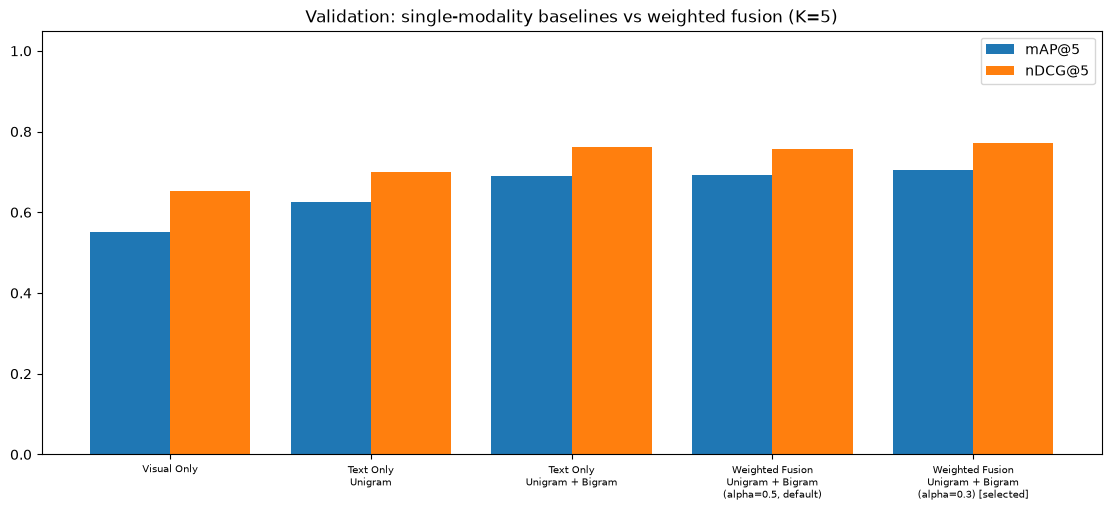

[SAVED] 228_results_validation_selection_baselines.png


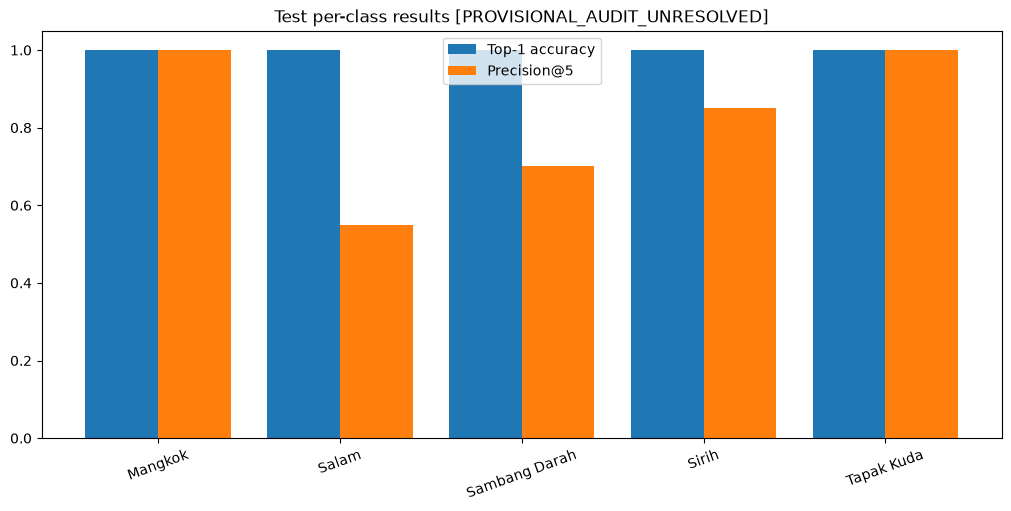

[SAVED] 229_results_test_class_success_PROVISIONAL.png
[SAVED] 741_results_validation_baselines.csv
[SAVED] 742_results_alpha_sensitivity.csv
[SAVED] 743_results_test_summary_PROVISIONAL.csv
[SAVED] 744_results_class_errors_PROVISIONAL.csv
[SAVED] 745_results_audit_findings.csv
[SAVED] 746_results_synthesis_checks.csv
[SAVED] 747_experiment_synthesis_report_PROVISIONAL.md

CELL 19 COMPLETED


In [20]:
# ============================================================
# CELL 19 - RESULTS SYNTHESIS & EXPERIMENT REPORT
# ============================================================
# Every number in the report is read from tables computed in this run.

assert globals().get("EVAL06_COMPARISON_COMPLETED") is True, "Jalankan Cell 18 terlebih dahulu."

EVAL06_SYNTHESIS_COMPLETED = False
print("NOTEBOOK 06 - CELL 19: RESULTS SYNTHESIS")
print("=" * 75)

baseline_rows = []
for name, frame in [("Visual Only", EVAL06_VALIDATION_MACRO_DF.query("method == 'Visual Only'")),
                    ("Text Only - Unigram", EVAL06_VALIDATION_MACRO_DF.query("method == 'Text Only - Unigram'")),
                    ("Text Only - Unigram + Bigram", EVAL06_VALIDATION_MACRO_DF.query("method == 'Text Only - Unigram + Bigram'")),
                    (f"Weighted Fusion - {EVAL06_SELECTED_TEXT_CONFIG} (alpha=0.5, default)",
                     EVAL06_ALPHA_MACRO_DF.loc[(EVAL06_ALPHA_MACRO_DF["text_configuration"] == EVAL06_SELECTED_TEXT_CONFIG)
                                               & np.isclose(EVAL06_ALPHA_MACRO_DF["alpha"], 0.5)]),
                    (EVAL06_SELECTED_LABEL + " [selected]", EVAL06_SELECTED_METRICS_BY_K_DF)]:
    for r in frame.itertuples(index=False):
        baseline_rows.append({"method": name, "k": r.k, **{EVAL06_METRIC_DISPLAY[c]: getattr(r, c) for c in EVAL06_METRIC_DISPLAY}})
EVAL06_RESULTS_VALIDATION_DF = pd.DataFrame(baseline_rows)
EVAL06_RESULTS_ALPHA_DF = EVAL06_ALPHA_AT5_DF[["text_configuration", "alpha", "map_at_k", "mean_ndcg_at_k",
                                               "mean_mrr_at_k", "mean_precision_at_k", "mean_recall_at_k"]]
EVAL06_RESULTS_TEST_DF = EVAL06_TEST_MACRO_ALL_DF.rename(columns=EVAL06_METRIC_DISPLAY)[
    ["method", "role", "k"] + list(EVAL06_METRIC_DISPLAY.values()) + ["status"]]

v5 = EVAL06_RESULTS_VALIDATION_DF.query("k == 5").set_index("method")
t5 = EVAL06_RESULTS_TEST_DF.query("k == 5").set_index("method")
sel_v = v5.loc[EVAL06_SELECTED_LABEL + " [selected]"]
sel_t = t5.loc[EVAL06_SELECTED_LABEL]
n_err = {s: int((~EVAL06_ERROR_ANALYSIS_DF.query("partition == @s")["top1_correct"]).sum()) for s in ("validation", "test")}
sens = EVAL06_LEAKAGE_SENSITIVITY_DF.set_index("partition")


def fmt(x):
    return f"{x:.4f}"


def md_table(df):
    cols = list(df.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for row in df.itertuples(index=False):
        lines.append("| " + " | ".join(fmt(v) if isinstance(v, float) else str(v) for v in row) + " |")
    return "\n".join(lines)


val_table = v5.reset_index()[["method"] + list(EVAL06_METRIC_DISPLAY.values())]
test_table = t5.reset_index()[["method"] + list(EVAL06_METRIC_DISPLAY.values())]
open_items = EVAL06_RESOLUTION_MATRIX_DF.loc[~EVAL06_RESOLUTION_MATRIX_DF["resolution_state"].isin(ACCEPTED_STATES),
                                             ["issue_id", "finding_count", "resolution_state"]]

report = f"""# Notebook 06 - Weighted Score Fusion: Experiment Report

Run ID: `{EVAL06_RUN_ID}`
Pipeline version: `{EVAL06_PIPELINE_VERSION}`
Test status: **{EVAL06_TEST_EVALUATION_STATUS}** (independent estimate: {EVAL06_TEST_IS_INDEPENDENT_ESTIMATE})

## Data and features
- Samples: {EVAL06_N_SAMPLES} ({len(EVAL06_CLASSES)} classes) - gallery {len(EVAL06_QUERY_IDS['gallery'])}, validation {len(EVAL06_QUERY_IDS['validation'])}, test {len(EVAL06_QUERY_IDS['test'])} (group-aware, seed {EVAL06_RANDOM_STATE}).
- Visual: Notebook 03 vectors, {EVAL06_VISUAL_DIM} dims (HSV 64 + GLCM 72 + Hu 7), NB03 normalizer fitted on gallery only.
- Text: cleaned_description, TF-IDF fitted on gallery only (vocabulary: {', '.join(f'{c} = {len(v.vocabulary_)}' for c, v in EVAL06_TFIDF_VECTORIZERS.items())}).
- Visual similarity: {EVAL06_VISUAL_SIMILARITY_FORMULA} (scale = {EVAL06_VISUAL_DISTANCE_SCALE:.6f}).
- Fusion: {EVAL06_FUSION_FORMULA}.

## Validation-only selection
- Selected: **{EVAL06_SELECTED_TEXT_CONFIG}, alpha = {EVAL06_SELECTED_ALPHA}** ({EVAL06_SELECTED_METHOD}); validation mAP@5 = {fmt(sel_v['mAP@K'])}.
- The legacy alpha = 0.3 was not reused; alpha was re-selected from the corrected features.

### Validation metrics at K=5
{md_table(val_table)}

## Test ({EVAL06_TEST_EVALUATION_STATUS})
{md_table(test_table)}

- Selected configuration: test mAP@5 = {fmt(sel_t['mAP@K'])} vs validation {fmt(sel_v['mAP@K'])}.
- Top-1 errors: validation {n_err['validation']}/{len(EVAL06_QUERY_IDS['validation'])}, test {n_err['test']}/{len(EVAL06_QUERY_IDS['test'])}.
- Top-1 neighbour has an identical description: validation {int(sens.loc['validation', 'top1_is_identical_description'])}, test {int(sens.loc['test', 'top1_is_identical_description'])}.
- Top-1 neighbour is a flagged near-duplicate image: validation {int(sens.loc['validation', 'top1_is_flagged_near_duplicate'])}, test {int(sens.loc['test', 'top1_is_flagged_near_duplicate'])}.

## Audit status
- Image hash source: {EVAL06_IMAGE_HASH_SOURCE}.
- Cross-split near-duplicate candidates: {EVAL06_CROSS_SPLIT_NEAR_DUPLICATES} (open pair reviews: {EVAL06_OPEN_PAIR_REVIEWS}).
- Cross-split repeated-description groups: {EVAL06_CROSS_SPLIT_TEXT_GROUPS}.
- Specimen identity column: {EVAL06_GROUP_COLUMN}.
- Query samples with visual features far outside the gallery range (|z| > 10): {EVAL06_VISUAL_OOD_DF['sample_id'].nunique()} ({', '.join(sorted(EVAL06_VISUAL_OOD_DF['sample_id'].unique())) or 'none'}).
- Test inspected in earlier runs: {EVAL06_TEST_PREVIOUSLY_INSPECTED}.
- Human sign-off valid: {EVAL06_HUMAN_APPROVAL_VALID}.

Open issues:
{md_table(open_items) if len(open_items) else 'None'}

## Interpretation constraints
- Technical execution success does not establish methodological validity.
- Test numbers must be reported with the status label above. They are not an independent
  generalisation estimate while the status is not {EVAL06_STATUS_INDEPENDENT}.
- Candidate near-duplicates and repeated descriptions are not proof of leakage, but they may
  inflate retrieval scores until they are reviewed.
"""

EVAL06_SYNTHESIS_CHECKS_DF = pd.DataFrame([
    {"check": "Selected validation mAP@5 equals lock", "passed": bool(np.isclose(sel_v["mAP@K"], EVAL06_SELECTION_LOCK["selected_validation_map_at_5"]))},
    {"check": "Selected test mAP@5 equals Cell 15", "passed": bool(np.isclose(sel_t["mAP@K"], test_map5))},
    {"check": "Report contains status label", "passed": EVAL06_TEST_EVALUATION_STATUS in report},
])
assert EVAL06_SYNTHESIS_CHECKS_DF["passed"].all()

display(val_table.round(4))
display(test_table.round(4))

fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
x = np.arange(len(val_table))
ax.bar(x - 0.2, val_table["mAP@K"], width=0.4, label="mAP@5")
ax.bar(x + 0.2, val_table["nDCG@K"], width=0.4, label="nDCG@5")
ax.set_xticks(x, [m.replace(" - ", "\n").replace(" (", "\n(") for m in val_table["method"]], fontsize=7)
ax.set(ylim=(0, 1.05), title="Validation: single-modality baselines vs weighted fusion (K=5)")
ax.legend()
eval06_save_figure(fig, "228_results_validation_selection_baselines.png", 19)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
cls = EVAL06_CLASS_ERROR_SUMMARY_DF.query("partition == 'test'").set_index("true_class").loc[EVAL06_CLASSES]
ax.bar(np.arange(5) - 0.2, cls["top1_accuracy"], width=0.4, label="Top-1 accuracy")
ax.bar(np.arange(5) + 0.2, cls["mean_precision_at_5"], width=0.4, label="Precision@5")
ax.set_xticks(np.arange(5), EVAL06_CLASSES, rotation=20)
ax.set(ylim=(0, 1.05), title=f"Test per-class results [{EVAL06_TEST_EVALUATION_STATUS}]")
ax.legend()
eval06_save_figure(fig, f"229_results_test_class_success{SFX}.png", 19)

eval06_save_csv(EVAL06_RESULTS_VALIDATION_DF, "741_results_validation_baselines.csv", 19)
eval06_save_csv(EVAL06_RESULTS_ALPHA_DF, "742_results_alpha_sensitivity.csv", 19)
eval06_save_csv(EVAL06_RESULTS_TEST_DF, f"743_results_test_summary{SFX}.csv", 19)
eval06_save_csv(EVAL06_CLASS_ERROR_SUMMARY_DF, f"744_results_class_errors{SFX}.csv", 19)
eval06_save_csv(EVAL06_RESOLUTION_MATRIX_DF, "745_results_audit_findings.csv", 19)
eval06_save_csv(EVAL06_SYNTHESIS_CHECKS_DF, "746_results_synthesis_checks.csv", 19)
eval06_save_text(report, f"747_experiment_synthesis_report{SFX}.md", 19)

EVAL06_SYNTHESIS_REPORT = report
EVAL06_SYNTHESIS_COMPLETED = True
print("\nCELL 19 COMPLETED")

## Cell 20 — Final Notebook Audit

NOTEBOOK 06 - CELL 20: FINAL NOTEBOOK AUDIT


,category,validation_check,passed,severity_if_failed,detail
0,Features,Saved visual matrices have 143 columns,True,BLOCK,
1,Features,Saved visual matrices equal in-memory matrices,True,BLOCK,
2,Gallery-only,Saved visual normalizer fitted on gallery count,True,BLOCK,
3,Gallery-only,Saved Unigram TF-IDF equals fresh gallery-only...,True,BLOCK,
4,Gallery-only,Saved Unigram validation matrix = transform wi...,True,BLOCK,
5,Gallery-only,Saved Unigram + Bigram TF-IDF equals fresh gal...,True,BLOCK,
6,Gallery-only,Saved Unigram + Bigram validation matrix = tra...,True,BLOCK,
7,Split,sample_id order and class labels match NB02/NB...,True,BLOCK,
8,Split,Gallery / validation / test do not overlap,True,BLOCK,
9,Lock,alpha / TF-IDF in test rankings == latest sele...,True,BLOCK,


,item,value
0,Run ID,20261127T090108Z_c12d4354b8
1,Samples (gallery/validation/test),104 (62/21/21)
2,Visual dimension,143
3,TF-IDF vocabulary (gallery fit),"Unigram=66, Unigram + Bigram=233"
4,Selected TF-IDF,Unigram + Bigram
5,Selected alpha,0.3
6,Validation mAP@5,0.7052
7,Test mAP@5,0.7941
8,Technical status,TECHNICAL_COMPLETE
9,Test / scientific status,PROVISIONAL_AUDIT_UNRESOLVED


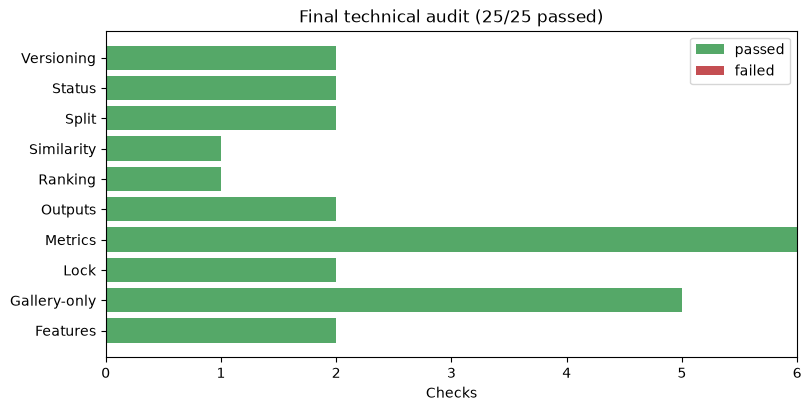

[SAVED] 230_final_notebook_technical_audit.png
[SAVED] 749_final_notebook_checks.csv
[SAVED] 751_final_dataset_split_inventory.csv
[SAVED] 753_final_methodological_limitations.csv
[SAVED] 754_final_experiment_summary_PROVISIONAL.md
[SAVED] 755_final_notebook_handoff_PROVISIONAL.json
[SAVED] 750_final_output_inventory.csv
[SAVED] 600_run_manifest.json

NOTEBOOK 06 COMPLETED
Technical status: TECHNICAL_COMPLETE (25/25 checks)
Test status     : PROVISIONAL_AUDIT_UNRESOLVED
Outputs         : 180 files in run 20261127T090108Z_c12d4354b8
[INFO] Technical completion is not methodological approval.


In [21]:
# ============================================================
# CELL 20 - FINAL NOTEBOOK AUDIT & OUTPUT INVENTORY
# ============================================================
# Re-reads the SAVED artifacts of this run (not only in-memory objects)
# and verifies the technical requirements. Then the run is registered as
# COMPLETED. Technical completion != methodological approval.

from scipy.sparse import load_npz
from joblib import load as joblib_load

assert globals().get("EVAL06_SYNTHESIS_COMPLETED") is True, "Jalankan Cell 19 terlebih dahulu."

print("NOTEBOOK 06 - CELL 20: FINAL NOTEBOOK AUDIT")
print("=" * 75)
final_checks = []

# 1. Features (from disk) ---------------------------------------------------
splits_npz = np.load(EVAL06_ARTIFACTS_DIR / "visual_gallery_fitted_splits.npz")
eval06_check(final_checks, "Features", "Saved visual matrices have 143 columns",
             all(splits_npz[s].shape[1] == 143 for s in EVAL06_SPLIT_NAMES))
eval06_check(final_checks, "Features", "Saved visual matrices equal in-memory matrices",
             all(np.array_equal(splits_npz[s], EVAL06_VISUAL_FEATURES_BY_SPLIT[s]) for s in EVAL06_SPLIT_NAMES))
saved_norm = joblib_load(EVAL06_ARTIFACTS_DIR / "visual_gallery_fitted_normalizer.joblib")
eval06_check(final_checks, "Gallery-only", "Saved visual normalizer fitted on gallery count",
             saved_norm["n_reference_samples"] == len(EVAL06_QUERY_IDS["gallery"]))
for config, spec in EVAL06_TEXT_CONFIGURATIONS.items():
    saved_vec = joblib_load(EVAL06_ARTIFACTS_DIR / f"tfidf_{spec['slug']}_gallery_fitted.joblib")
    fresh = TfidfVectorizer(ngram_range=spec["ngram_range"], **EVAL06_TFIDF_PARAMS).fit(EVAL06_FEATURE_TEXT_DOCUMENTS["gallery"])
    eval06_check(final_checks, "Gallery-only", f"Saved {config} TF-IDF equals fresh gallery-only fit",
                 saved_vec.vocabulary_ == fresh.vocabulary_ and np.allclose(saved_vec.idf_, fresh.idf_))
    eval06_check(final_checks, "Gallery-only", f"Saved {config} validation matrix = transform with gallery vectorizer",
                 np.allclose(load_npz(EVAL06_ARTIFACTS_DIR / f"tfidf_{spec['slug']}_validation.npz").toarray(),
                             fresh.transform(EVAL06_FEATURE_TEXT_DOCUMENTS["validation"]).toarray()))

# 2. Split / identity -------------------------------------------------------
split_file = pd.read_csv(EVAL06_METRICS_DIR / "620_group_aware_split_assignments.csv", dtype=str, encoding="utf-8-sig")
eval06_check(final_checks, "Split", "sample_id order and class labels match NB02/NB03 sources",
             split_file["sample_id"].tolist() == EVAL06_SAMPLE_IDS.tolist()
             and split_file["class_label"].tolist() == EVAL06_LABELS.tolist())
id_sets = {s: set(split_file.loc[split_file["split"] == s, "sample_id"]) for s in EVAL06_SPLIT_NAMES}
eval06_check(final_checks, "Split", "Gallery / validation / test do not overlap",
             not (id_sets["gallery"] & id_sets["validation"]) and not (id_sets["gallery"] & id_sets["test"])
             and not (id_sets["validation"] & id_sets["test"]))

# 3. Selection lock vs rankings --------------------------------------------
lock_file = json.loads(EVAL06_SELECTION_LOCK_PATH.read_text(encoding="utf-8"))
test_rank_file = pd.read_csv(EVAL06_METRICS_DIR / f"711_frozen_test_full_rankings{SFX}.csv", encoding="utf-8-sig")
eval06_check(final_checks, "Lock", "alpha / TF-IDF in test rankings == latest selection lock",
             test_rank_file["alpha"].eq(lock_file["selected_alpha"]).all()
             and test_rank_file["text_configuration"].eq(lock_file["selected_text_configuration"]).all())
eval06_check(final_checks, "Lock", "Lock is validation-only and not the legacy alpha by assumption",
             lock_file["selection_partition"] == "validation" and lock_file["legacy_alpha_reused"] is False)
val_rank_file = pd.read_csv(EVAL06_METRICS_DIR / "646_validation_full_rankings.csv", encoding="utf-8-sig")
eval06_check(final_checks, "Ranking", "No duplicate candidates in saved validation/test rankings",
             val_rank_file.groupby(["method", "query_sample_id"])["gallery_sample_id"].apply(lambda v: v.is_unique).all()
             and test_rank_file.groupby("query_sample_id")["gallery_sample_id"].apply(lambda v: v.is_unique).all())

# 4. Metrics (from disk) -----------------------------------------------------
for pq_name, macro_name, keys in [("653_validation_per_query_metrics.csv", "654_validation_macro_metric_summary.csv", ["method", "k"]),
                                  ("662_validation_alpha_per_query_metrics.csv", "663_validation_alpha_macro_metrics.csv",
                                   ["text_configuration", "alpha", "k"]),
                                  (f"717_test_per_query_metrics{SFX}.csv", f"718_test_macro_metrics{SFX}.csv", ["method", "k"])]:
    pq = pd.read_csv(EVAL06_METRICS_DIR / pq_name, encoding="utf-8-sig")
    macro = pd.read_csv(EVAL06_METRICS_DIR / macro_name, encoding="utf-8-sig")
    merged = pq.groupby(keys)[EVAL06_METRIC_COLUMNS].mean().rename(columns=EVAL06_MACRO_COLUMNS).reset_index() \
        .merge(macro, on=keys, suffixes=("_recomputed", ""))
    eval06_check(final_checks, "Metrics", f"{macro_name}: macro == mean(per-query)",
                 len(merged) == len(macro) and all(np.allclose(merged[c + "_recomputed"], merged[c])
                                                   for c in EVAL06_MACRO_COLUMNS.values()))
    eval06_check(final_checks, "Metrics", f"{pq_name}: values finite and in [0, 1]",
                 pq[EVAL06_METRIC_COLUMNS].stack().between(0, 1 + 1e-12).all())
sim = np.load(EVAL06_ARTIFACTS_DIR / "similarity_matrices.npz")
eval06_check(final_checks, "Similarity", "All saved similarity matrices finite and in [0, 1]",
             all(np.isfinite(sim[k]).all() and sim[k].min() >= 0 and sim[k].max() <= 1 + 1e-12
                 for k in sim.files if not k.startswith("visual_distance")))

# 5. Outputs ------------------------------------------------------------------
inventory = []
for item in EVAL06_OUTPUT_LOG:
    path = Path(item["path"])
    inventory.append({**item, "exists": path.is_file(), "size_bytes": path.stat().st_size if path.is_file() else 0,
                      "sha256": eval06_sha256_file(path) if path.is_file() else "",
                      "inside_this_run": str(path).startswith((str(EVAL06_METRICS_DIR), str(EVAL06_FIGURES_DIR),
                                                               str(EVAL06_ARTIFACTS_DIR)))})
EVAL06_OUTPUT_INVENTORY_DF = pd.DataFrame(inventory).drop_duplicates("path")
pngs = EVAL06_OUTPUT_INVENTORY_DF.loc[EVAL06_OUTPUT_INVENTORY_DF["kind"] == "png"]
eval06_check(final_checks, "Outputs", "All logged outputs exist and are non-empty",
             EVAL06_OUTPUT_INVENTORY_DF["exists"].all() and EVAL06_OUTPUT_INVENTORY_DF["size_bytes"].gt(0).all())
eval06_check(final_checks, "Outputs", "All figures generated", len(pngs) >= 25 and pngs["size_bytes"].gt(0).all(),
             detail=f"figures={len(pngs)}")
eval06_check(final_checks, "Versioning", "All outputs written inside this run's folders",
             EVAL06_OUTPUT_INVENTORY_DF["inside_this_run"].all())
eval06_check(final_checks, "Versioning", "No file of this run existed before the run started",
             all(datetime.fromtimestamp(Path(p).stat().st_mtime, timezone.utc) >= EVAL06_RUN_STARTED_UTC.replace(microsecond=0)
                 for p in EVAL06_OUTPUT_INVENTORY_DF["path"]))
eval06_check(final_checks, "Status", "Test status label consistent with sign-off",
             (EVAL06_TEST_EVALUATION_STATUS == EVAL06_STATUS_PROVISIONAL) != EVAL06_HUMAN_APPROVAL_VALID)
eval06_check(final_checks, "Status", "Previously inspected test never labelled independent",
             not (EVAL06_TEST_PREVIOUSLY_INSPECTED and EVAL06_TEST_IS_INDEPENDENT_ESTIMATE))

EVAL06_FINAL_CHECKS_DF = eval06_checks_frame(final_checks)
display(EVAL06_FINAL_CHECKS_DF)
eval06_require(EVAL06_FINAL_CHECKS_DF, "Cell 20")

EVAL06_TECHNICAL_STATUS = "TECHNICAL_COMPLETE"
EVAL06_SCIENTIFIC_STATUS = EVAL06_TEST_EVALUATION_STATUS

sel_v5 = EVAL06_SELECTED_METRICS_BY_K_DF.query("k == 5").iloc[0]
sel_t5 = EVAL06_TEST_MACRO_DF.query("k == 5").iloc[0]
EVAL06_FINAL_SUMMARY_DF = pd.DataFrame([
    ("Run ID", EVAL06_RUN_ID),
    ("Samples (gallery/validation/test)", f"{EVAL06_N_SAMPLES} ({len(EVAL06_QUERY_IDS['gallery'])}/"
                                          f"{len(EVAL06_QUERY_IDS['validation'])}/{len(EVAL06_QUERY_IDS['test'])})"),
    ("Visual dimension", EVAL06_VISUAL_DIM),
    ("TF-IDF vocabulary (gallery fit)", ", ".join(f"{c}={len(v.vocabulary_)}" for c, v in EVAL06_TFIDF_VECTORIZERS.items())),
    ("Selected TF-IDF", EVAL06_SELECTED_TEXT_CONFIG),
    ("Selected alpha", EVAL06_SELECTED_ALPHA),
    ("Validation mAP@5", round(float(sel_v5["map_at_k"]), 4)),
    ("Test mAP@5", round(float(sel_t5["map_at_k"]), 4)),
    ("Technical status", EVAL06_TECHNICAL_STATUS),
    ("Test / scientific status", EVAL06_SCIENTIFIC_STATUS),
    ("Image hash source", EVAL06_IMAGE_HASH_SOURCE),
], columns=["item", "value"])
display(EVAL06_FINAL_SUMMARY_DF)

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
by_cat = EVAL06_FINAL_CHECKS_DF.groupby("category")["passed"].agg(["sum", "count"])
ax.barh(by_cat.index, by_cat["sum"], color="#55A868", label="passed")
ax.barh(by_cat.index, by_cat["count"] - by_cat["sum"], left=by_cat["sum"], color="#C44E52", label="failed")
ax.set(title=f"Final technical audit ({int(EVAL06_FINAL_CHECKS_DF['passed'].sum())}/{len(EVAL06_FINAL_CHECKS_DF)} passed)",
       xlabel="Checks")
ax.legend()
eval06_save_figure(fig, "230_final_notebook_technical_audit.png", 20)

summary_md = ("# Notebook 06 final summary\n\n"
              + "\n".join(f"- **{r.item}**: {r.value}" for r in EVAL06_FINAL_SUMMARY_DF.itertuples())
              + "\n\nTechnical completion does not imply methodological approval.\n")
eval06_save_csv(EVAL06_FINAL_CHECKS_DF, "749_final_notebook_checks.csv", 20)
eval06_save_csv(EVAL06_SPLIT_ASSIGNMENTS_DF, "751_final_dataset_split_inventory.csv", 20)
eval06_save_csv(EVAL06_LIMITATIONS_DF, "753_final_methodological_limitations.csv", 20)
eval06_save_text(summary_md, f"754_final_experiment_summary{SFX}.md", 20)
eval06_save_json({"run_id": EVAL06_RUN_ID, "technical_status": EVAL06_TECHNICAL_STATUS,
                  "test_status": EVAL06_TEST_EVALUATION_STATUS, "selected_text_configuration": EVAL06_SELECTED_TEXT_CONFIG,
                  "selected_alpha": EVAL06_SELECTED_ALPHA, "selection_lock_sha256": EVAL06_SELECTION_LOCK_SHA256,
                  "validation_map_at_5": float(sel_v5["map_at_k"]), "test_map_at_5": float(sel_t5["map_at_k"]),
                  "independent_estimate": EVAL06_TEST_IS_INDEPENDENT_ESTIMATE},
                 f"755_final_notebook_handoff{SFX}.json", 20)

# Inventory last (includes everything above), then finalize run manifest & registry.
inventory = [{**i, "sha256": eval06_sha256_file(i["path"]), "size_bytes": Path(i["path"]).stat().st_size}
             for i in pd.DataFrame(EVAL06_OUTPUT_LOG).drop_duplicates("path").to_dict("records")]
eval06_save_csv(pd.DataFrame(inventory), "750_final_output_inventory.csv", 20)

EVAL06_RUN_MANIFEST.update({"finished_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
                            "technical_status": EVAL06_TECHNICAL_STATUS, "test_status": EVAL06_TEST_EVALUATION_STATUS,
                            "output_count": len(inventory) + 2})
eval06_save_json(EVAL06_RUN_MANIFEST, "600_run_manifest.json", 20)
eval06_update_registry(status="COMPLETED", finished_utc=EVAL06_RUN_MANIFEST["finished_utc"])
EVAL06_LATEST_POINTER_PATH.write_text(json.dumps({
    "run_id": EVAL06_RUN_ID, "metrics_dir": str(EVAL06_METRICS_DIR), "figures_dir": str(EVAL06_FIGURES_DIR),
    "artifacts_dir": str(EVAL06_ARTIFACTS_DIR), "test_status": EVAL06_TEST_EVALUATION_STATUS}, indent=2), encoding="utf-8")

print("\n" + "=" * 75)
print("NOTEBOOK 06 COMPLETED")
print("=" * 75)
print("Technical status:", EVAL06_TECHNICAL_STATUS, f"({int(EVAL06_FINAL_CHECKS_DF['passed'].sum())}/{len(EVAL06_FINAL_CHECKS_DF)} checks)")
print("Test status     :", EVAL06_TEST_EVALUATION_STATUS)
print("Outputs         :", len(inventory) + 2, "files in run", EVAL06_RUN_ID)
print("[INFO] Technical completion is not methodological approval.")